# CASIE: event-conditioned argument role extraction

**Team Ultron · NLP Project 2 · executed submission notebook**

Given a gold cybersecurity event subtype and trigger, identify argument spans
and assign one of 26 roles (53 BIO tags). The corrected split has 799 training,
100 validation, and 100 test documents. The primary metric is exact
span-and-role micro F1 (Arg-C); macro F1 and per-role support show performance
on less frequent roles.

**Provenance.** The data subgroup prepared the corrected split and the raw
preprocessing source. The earlier team model/evaluation work supplied CRF,
BERT cased and uncased, RoBERTa, and SecureBERT predictions, plus training and
evaluation source. Additional runs produced another feature CRF, BiLSTM-CRF,
DeBERTa-v3-base, and a role-conditioned DeBERTa adaptation. The two CRF rows
are separate runs of the same architecture. Checkpoints for the five supplied
models were not included. The additional BiLSTM was resumed after epoch 12
with the same model and optimizer and selected epoch 17.

**Result.** Eight model/configuration variants have validation predictions.
RoBERTa was selected by validation Arg-C F1 (0.6189) and scored 0.6196 on the
test split. The role-conditioned adaptation scored 0.5838 validation and
0.5966 test. All score tables and plots in Sections 10–12 were executed.
The earlier, separate DeBERTa run scored 0.6171 on validation, but its weights
were lost after a Colab reset; it is not part of the checkpoint-backed final
comparison. The reproducible DeBERTa checkpoint used below scored 0.5987.

**Limitations.** Historical team test results were visible before these
additional experiments, so the test split is not fully pristine. We fixed the
model selection rule on validation and did not tune on the new test results.
Published TextEE CASIE scores use a different split and cannot be compared
numerically to ours. The optional evidence ZIP in Section 13 was not exported
before a Colab runtime reset; the executed tables and figures are preserved
in this notebook. The per-event prediction archive can be rebuilt from the
saved checkpoints without retraining.

**Team record.** The dataset preparation subgroup supplied the cleaned data;
Muhammet supplied the initial evaluation and baseline prediction artifacts;
Abdulilah ran the additional experiments and integrated the benchmark. The
submission and results belong to Team Ultron.

To reproduce from scratch, run the notebook with a Colab GPU and upload
`TeamUltron_Project2_Inputs.zip` in Section 1. The default restore flags are
`False`; checkpoint reuse is optional. No personal Drive folder is required.


## Reading guide

1. **Task and data (Sections 1–2):** verify corrected document splits and the
   exact-span, exact-role scorer.
2. **Methods (Sections 3–9):** show team source and supplied predictions,
   then reproduce or restore the additional CRF, BiLSTM-CRF and DeBERTa
   checkpoints. Section 9 contains the completed role-conditioned adaptation.
3. **Model selection (Section 10):** compare eight variants on the same
   validation split and select RoBERTa by Arg-C F1.
4. **Held-out evaluation (Sections 11–12):** compare nine test rows (including
   both CRF runs), show uncertainty, per-role performance and errors.
5. **Export (Section 13):** an optional archive of per-event predictions,
   tables and figures when those temporary files are present in the runtime.
   The already executed outputs remain visible below if Colab disconnects.

Appendix A retains raw preprocessing stages supplied by the team. This
executed experiment started from the checked, corrected split; the appendix
was not run or independently verified end to end in this session.


## 1. Environment and corrected dataset

Upload `TeamUltron_Project2_Inputs.zip`, containing the corrected split and
audited team prediction files. These cells check hashes, document isolation,
class counts and the known near-duplicate constraint. The raw preprocessing
source is retained in Appendix A; the corrected input is independently checked
here before training or scoring.


In [ ]:
import sys
import torch
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print("GPU:", gpu.name)
    print("GPU memory:", round(gpu.total_memory / 1024**3, 1), "GB")

for package in ["transformers", "tokenizers", "sentencepiece", "scikit-learn"]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
GPU memory: 14.6 GB
transformers: 5.21.0
tokenizers: 0.23.3
sentencepiece: 0.2.2
scikit-learn: 1.6.1


In [ ]:
from google.colab import files
from pathlib import Path
import zipfile
import json

uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(uploaded) == len(zip_names) == 1, "Upload the single TeamUltron_Project2_Inputs.zip."

zip_path = Path(zip_names[0])
assert zip_path.name == "TeamUltron_Project2_Inputs.zip", "Use the project input bundle."
del uploaded

with zipfile.ZipFile(zip_path) as archive:
    members = [
        name for name in archive.namelist()
        if not name.startswith("__MACOSX/") and not name.endswith("/")
    ]

    dataset_members = {}
    for filename in [
        "CASIE_train.jsonl",
        "CASIE_validation.jsonl",
        "CASIE_test.jsonl",
        "CASIE_dataset_metadata.json",
    ]:
        matches = [name for name in members if Path(name).name == filename]
        assert len(matches) == 1, f"Missing or duplicated: {filename}"
        dataset_members[filename] = matches[0]

    metadata = json.loads(
        archive.read(dataset_members["CASIE_dataset_metadata.json"])
    )

assert metadata.get("tokenization", {}).get(
    "annotation_aware_splitting"
) is False, "This archive does not confirm corrected text-only tokenization."

print("Archive:", zip_path.name)
print("Size (MB):", round(zip_path.stat().st_size / 1_000_000, 2))
print("Documents:", metadata.get("documents"))
print("Events:", metadata.get("events"))
print("Arguments:", metadata.get("arguments"))
print("Corrected text-only tokenization: confirmed")
with zipfile.ZipFile(zip_path) as archive:
    input_manifest = json.loads(archive.read("input_manifest.json"))
    assert set(input_manifest["files"]) <= set(archive.namelist())
    assert len(input_manifest["files"]) == 17
print("Verified project input manifest:", len(input_manifest["files"]), "files")


Saving TeamUltron_Project2_Inputs.zip to TeamUltron_Project2_Inputs.zip
Archive: TeamUltron_Project2_Inputs.zip
Size (MB): 43.34
Documents: 999
Events: 8482
Arguments: 22694
Corrected text-only tokenization: confirmed
Verified project input manifest: 17 files


In [ ]:
import csv
import hashlib
import shutil
import zipfile
from pathlib import Path

DATA_DIR = Path("casie_data")
DATA_DIR.mkdir(exist_ok=True)

required_files = [
    "CASIE_train.jsonl",
    "CASIE_validation.jsonl",
    "CASIE_test.jsonl",
    "CASIE_dataset_metadata.json",
    "CASIE_dataset_checksums.csv",
    "CASIE_document_split_manifest.csv",
    "CASIE_split_constraints.csv",
]

data_paths = {}

with zipfile.ZipFile(zip_path) as archive:
    for filename in required_files:
        matches = [
            name for name in archive.namelist()
            if not name.startswith("__MACOSX/")
            and Path(name).name == filename
        ]
        assert len(matches) == 1, f"Missing or duplicated: {filename}"

        destination = DATA_DIR / filename
        with archive.open(matches[0]) as source, destination.open("wb") as target:
            shutil.copyfileobj(source, target)

        data_paths[filename] = destination

with data_paths["CASIE_dataset_checksums.csv"].open(
    encoding="utf-8", newline=""
) as file:
    expected_hashes = {
        row["filename"]: row["sha256"] for row in csv.DictReader(file)
    }

for filename in [
    "CASIE_train.jsonl",
    "CASIE_validation.jsonl",
    "CASIE_test.jsonl",
    "CASIE_document_split_manifest.csv",
    "CASIE_split_constraints.csv",
]:
    with data_paths[filename].open("rb") as file:
        actual_hash = hashlib.file_digest(file, "sha256").hexdigest()

    assert actual_hash == expected_hashes[filename], f"Checksum mismatch: {filename}"
    print("PASS:", filename)

print("\nFiles extracted and verified.")

PASS: CASIE_train.jsonl
PASS: CASIE_validation.jsonl
PASS: CASIE_test.jsonl
PASS: CASIE_document_split_manifest.csv
PASS: CASIE_split_constraints.csv

Files extracted and verified.


In [ ]:
import json

documents = {}
datasets = {}
seen_events = set()
document_splits = {}

# Expected: documents, events, arguments
expected_counts = {
    "train": (799, 6877, 18445),
    "validation": (100, 869, 2140),
    "test": (100, 736, 2109),
}

for split, expected in expected_counts.items():
    records = []

    with data_paths[f"CASIE_{split}.jsonl"].open(encoding="utf-8") as file:
        for line in file:
            if not line.strip():
                continue

            record = json.loads(line)

            # Keep arguments and multilabel targets; omit redundant BIO layers.
            record.pop("role_layers", None)

            doc_id = record["document_id"]
            tokens, offsets = documents.setdefault(
                doc_id, (record["tokens"], record["token_offsets"])
            )
            record["tokens"] = tokens
            record["token_offsets"] = offsets

            assert len(tokens) == len(offsets) == len(record["token_labels"])
            assert record["event_uid"] not in seen_events
            seen_events.add(record["event_uid"])

            assert document_splits.setdefault(doc_id, split) == split, (
                f"Document appears across splits: {doc_id}"
            )

            records.append(record)

    datasets[split] = records
    counts = (
        len({r["document_id"] for r in records}),
        len(records),
        sum(len(r["arguments"]) for r in records),
    )
    assert counts == expected, f"{split}: unexpected counts {counts}"
    print(f"{split}: {counts[0]} documents, {counts[1]} events, {counts[2]} arguments")

# Derive the label map from training data only.
ROLES = sorted({
    argument["role"]
    for record in datasets["train"]
    for argument in record["arguments"]
})

LABELS = ["O"] + [
    f"{prefix}-{role}" for role in ROLES for prefix in ("B", "I")
]
label2id = {label: index for index, label in enumerate(LABELS)}
id2label = {index: label for label, index in label2id.items()}

assert len(ROLES) == 26
assert len(documents) == 999
assert "annotation/1554.json" not in documents
assert (
    document_splits["annotation/2663.json"]
    == document_splits["annotation/891.json"]
)

print("\nArgument roles:", len(ROLES))
print("BIO tags:", len(LABELS))
print("Document overlap: none")
print("Known near-duplicate pair: kept together")

train: 799 documents, 6877 events, 18445 arguments
validation: 100 documents, 869 events, 2140 arguments
test: 100 documents, 736 events, 2109 arguments

Argument roles: 26
BIO tags: 53
Document overlap: none
Known near-duplicate pair: kept together


## 2. Exact-span scoring

Arg-C counts an argument as correct only when its start token, inclusive end token,
and role all match. The independent scorer below checks an oracle and a two-role
overlap. This is the primary selection metric for our own experiments.


In [ ]:
from collections import Counter

def argument_spans(record):
    return {
        (min(a["token_ids"]), max(a["token_ids"]), a["role"])
        for a in record["arguments"]
    }

def precision_recall_f1(correct, predicted, gold):
    precision = correct / predicted if predicted else 0.0
    recall = correct / gold if gold else 0.0
    f1 = 2 * correct / (predicted + gold) if predicted + gold else 0.0
    return precision, recall, f1

def score_events(records, predictions, roles=ROLES):
    """Predictions: {event_uid: {(start, inclusive_end, role), ...}}."""
    event_ids = {r["event_uid"] for r in records}
    assert len(event_ids) == len(records), "Duplicate gold event IDs."
    assert not (set(predictions) - event_ids), "Unknown predicted events."

    role_gold, role_pred, role_correct = Counter(), Counter(), Counter()
    correct = predicted = gold = 0
    span_correct = span_predicted = span_gold = 0
    per_doc = {}

    for record in records:
        g = argument_spans(record)
        p = {tuple(span) for span in predictions.get(record["event_uid"], [])}

        for start, end, role in g | p:
            assert role in roles, f"Unknown role: {role}"
            assert 0 <= start <= end < len(record["tokens"]), "Invalid span."

        matches = g & p
        correct += len(matches)
        predicted += len(p)
        gold += len(g)

        role_gold.update(role for _, _, role in g)
        role_pred.update(role for _, _, role in p)
        role_correct.update(role for _, _, role in matches)

        # Span-only scoring counts each boundary pair once.
        g_spans = {(start, end) for start, end, _ in g}
        p_spans = {(start, end) for start, end, _ in p}
        span_correct += len(g_spans & p_spans)
        span_predicted += len(p_spans)
        span_gold += len(g_spans)

        counts = per_doc.setdefault(record["document_id"], [0, 0, 0])
        for i, value in enumerate((len(matches), len(p), len(g))):
            counts[i] += value

    per_role = []
    for role in roles:
        pr, re, f1 = precision_recall_f1(
            role_correct[role], role_pred[role], role_gold[role]
        )
        per_role.append({
            "role": role,
            "support": role_gold[role],
            "predicted": role_pred[role],
            "correct": role_correct[role],
            "precision": pr,
            "recall": re,
            "f1": f1,
        })

    pr, re, f1 = precision_recall_f1(correct, predicted, gold)
    return {
        "precision": pr,
        "recall": re,
        "micro_f1": f1,
        "macro_f1": sum(row["f1"] for row in per_role) / len(roles),
        "span_only_f1": precision_recall_f1(
            span_correct, span_predicted, span_gold
        )[2],
        "correct": correct,
        "predicted": predicted,
        "gold": gold,
        "per_role": per_role,
        "_per_doc": per_doc,
        "missing_prediction_events": len(event_ids - set(predictions)),
    }

In [ ]:
validation = datasets["validation"]
oracle = {r["event_uid"]: argument_spans(r) for r in validation}

assert score_events(validation, oracle)["micro_f1"] == 1.0
assert score_events(validation, {})["micro_f1"] == 0.0

# Perfect predictions must also score 1.0 when one span has two roles.
overlap = [{
    "event_uid": "check",
    "document_id": "check_doc",
    "tokens": ["Example"],
    "arguments": [
        {"token_ids": [0], "role": "Discoverer"},
        {"token_ids": [0], "role": "Vulnerable_System_Owner"},
    ],
}]
result = score_events(overlap, {"check": argument_spans(overlap[0])})
assert result["micro_f1"] == result["span_only_f1"] == 1.0

print("Scorer checks passed.")

Scorer checks passed.


## 3. Visible shared team implementation

The next three cells contain the complete source supplied by the team model and
evaluation work. `%%writefile` makes it importable at runtime while keeping the code
visible inside this one notebook. Two integration fixes are marked here: the Arg-I
denominators count unique spans per event (Arg-C is unchanged), and transformer
trainable weights load as float32 before PyTorch AMP (the original FP16 optimizer
step failed in our run). The source files are *generated by these cells*, not
required as additional uploads.


In [ ]:
from pathlib import Path
Path("team_code").mkdir(exist_ok=True)
print("Visible source directory ready.")


Visible source directory ready.


In [ ]:
%%writefile team_code/casie_eval.py
"""
casie_eval.py — Evaluation and error analysis for CASIE event argument extraction.

Team Ultron · NLP Course Project (COE025)

All scoring is done at the ARGUMENT SPAN level, per event:
    an argument = (event_uid, start_token, end_token, role)     end is inclusive
A prediction is correct only if start, end AND role match a gold argument
of the SAME event exactly.

Why not seqeval?  The dataset has multi-label tokens (one span can carry two
roles in the same event) and event-conditioned labels (the same document is
labelled differently for each event).  seqeval only understands one flat tag
sequence, so we score sets of spans directly.  On single-label data the
numbers are identical to seqeval's strict span matching.

Usage (Colab / Python):
    import casie_eval as ce
    gold  = ce.load_jsonl("CASIE_test.jsonl")
    preds = ce.load_predictions("predictions_bert.jsonl")
    res   = ce.evaluate(gold, preds)
    ce.print_report(res)
    ce.save_report(res, "results/bert")

Command line:
    python casie_eval.py --gold CASIE_test.jsonl --pred predictions_bert.jsonl --out results/bert
    python casie_eval.py --gold CASIE_test.jsonl --pred a.jsonl --pred-b b.jsonl     # compare two models
"""

from __future__ import annotations

import argparse
import json
import os
import random
from collections import Counter, defaultdict
from typing import Dict, Iterable, List, Optional, Sequence, Set, Tuple

Span = Tuple[int, int, str]  # (start_token, end_token_inclusive, role)

ERROR_TYPES = [
    "role_confusion",       # exact same span, wrong role
    "boundary",             # right role, span overlaps but boundaries differ
    "boundary_and_role",    # overlaps a gold span, but boundaries AND role wrong
    "spurious",             # predicted span overlaps no gold argument (pure false positive)
    "missed",               # gold argument with no overlapping prediction (pure false negative)
]


# =============================================================================
# 1. LOADING
# =============================================================================

def load_jsonl(path: str) -> List[dict]:
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def gold_spans(record: dict) -> Set[Span]:
    """Gold arguments of one event record as a set of (start, end, role)."""
    spans = set()
    for arg in record["arguments"]:
        ids = arg["token_ids"]
        spans.add((min(ids), max(ids), arg["role"]))
    return spans


def bio_to_spans(labels: Sequence, offset: int = 0) -> Set[Span]:
    """
    Decode a BIO sequence into spans.

    `labels` can be
      - a flat list of strings:            ["O", "B-Victim", "I-Victim", ...]
      - a list of lists (multi-label):     [["O"], ["B-Victim", "B-Discoverer"], ...]
    `offset` is added to every position (use it when the model ran on a
    window that starts at document token `offset`).

    Decoding is lenient like conlleval/seqeval default: an I-X that does not
    follow B-X/I-X starts a new span.
    """
    labels = [list(l) if not isinstance(l, str) and hasattr(l, "__len__") else l for l in labels]  # numpy-safe
    if labels and isinstance(labels[0], (list, tuple)):
        layers: Dict[str, List[str]] = defaultdict(lambda: ["O"] * len(labels))
        for i, labs in enumerate(labels):
            for lab in labs:
                if lab != "O":
                    layers[lab[2:]][i] = lab
        out = set()
        for role, seq in layers.items():
            out |= bio_to_spans(seq, offset)
        return out

    spans = set()
    start, role = None, None
    for i, lab in enumerate(list(labels) + ["O"]):
        lab = lab or "O"
        tag, r = (lab[0], lab[2:]) if lab != "O" else ("O", None)
        continues = tag == "I" and role == r and start is not None
        if not continues and start is not None:
            spans.add((start + offset, i - 1 + offset, role))
            start, role = None, None
        if tag == "B" or (tag == "I" and not continues):
            start, role = i, r
    return spans


def load_predictions(path: str) -> Dict[str, Set[Span]]:
    """
    Load a predictions JSONL file. One line per event, keyed by `event_uid`.
    Each line uses ONE of these formats (token indices are DOCUMENT-level,
    the same indices as `tokens` in CASIE_*.jsonl):

      A) spans  (recommended)
         {"event_uid": "...", "arguments": [{"role": "Victim", "start": 12, "end": 14}, ...]}
         `end` is inclusive. `token_ids: [12, 13, 14]` is also accepted instead of start/end.

      B) BIO labels over the whole document
         {"event_uid": "...", "labels": ["O", "B-Victim", "I-Victim", ...]}

      C) BIO labels over a window
         {"event_uid": "...", "labels": [...], "window_start": 230}
    """
    preds: Dict[str, Set[Span]] = defaultdict(set)
    for row in load_jsonl(path):
        uid = row["event_uid"]
        preds[uid]  # register the event even when it has no predicted arguments
        if "arguments" in row:
            for a in row["arguments"]:
                if "token_ids" in a:
                    s, e = min(a["token_ids"]), max(a["token_ids"])
                else:
                    s, e = int(a["start"]), int(a["end"])
                preds[uid].add((s, e, a["role"]))
        elif "labels" in row:
            preds[uid] |= bio_to_spans(row["labels"], row.get("window_start", 0))
        else:
            raise ValueError(f"Prediction for {uid} has neither 'arguments' nor 'labels'")
    return dict(preds)


def save_predictions(path: str, preds: Dict[str, Iterable[Span]]) -> None:
    """Write predictions in format A. `preds` maps event_uid -> iterable of (start, end, role)."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for uid, spans in preds.items():
            args = [{"role": r, "start": s, "end": e} for s, e, r in sorted(spans)]
            f.write(json.dumps({"event_uid": uid, "arguments": args}, ensure_ascii=False) + "\n")


def word_labels_from_subwords(pred_label_ids: Sequence[int],
                              word_ids: Sequence[Optional[int]],
                              id2label: Dict[int, str]) -> Dict[int, str]:
    """
    Helper for HuggingFace models: turn sub-word predictions into one label per
    word, using the FIRST sub-token of each word.

    pred_label_ids : argmax label ids for each sub-token (one window)
    word_ids       : tokenizer(...).word_ids() for that window
    returns        : {word_index: label}  (word_index as given in word_ids)
    """
    out = {}
    prev = None
    for lab_id, w in zip(pred_label_ids, word_ids):
        if w is not None and w != prev:
            out[w] = id2label[int(lab_id)]
        prev = w
    return out


# =============================================================================
# 2. METRICS
# =============================================================================

def _prf(tp: int, n_pred: int, n_gold: int) -> Tuple[float, float, float]:
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f


def _span_overlap(a: Span, b: Span) -> int:
    return max(0, min(a[1], b[1]) - max(a[0], b[0]) + 1)


def evaluate(gold_records: List[dict],
             preds: Dict[str, Set[Span]],
             n_examples: int = 15,
             seed: int = 42) -> dict:
    """
    Score predictions against gold event records.

    Returns a dict with:
      overall            Arg-C (span+role) and Arg-I (span only) micro P/R/F1, macro-F1
      per_role           list of rows: role, support, predicted, tp, P, R, F1
      per_subtype        list of rows per event subtype
      errors             counts per error type
      confusion          Counter of (gold_role, predicted_role) for role confusions
      boundary_detail    Counter: too_long / too_short / shifted
      by_distance        recall by token distance from the trigger
      by_length          recall by gold span length
      examples           sampled error examples with context
      warnings           list of strings (missing events, unknown uids, ...)
    """
    gold_uids = {r["event_uid"] for r in gold_records}
    warnings = []
    unknown = set(preds) - gold_uids
    if unknown:
        warnings.append(f"{len(unknown)} predicted event_uids are not in the gold file (ignored).")
    missing = gold_uids - set(preds)
    if missing:
        warnings.append(f"{len(missing)} gold events have no prediction line (treated as 'predicted nothing').")

    role_tp, role_pred, role_gold = Counter(), Counter(), Counter()
    sub_tp, sub_pred, sub_gold = Counter(), Counter(), Counter()
    tp_c = n_pred = n_gold = tp_i = 0
    n_pred_i = n_gold_i = 0
    errors = Counter()
    confusion = Counter()
    boundary_detail = Counter()
    dist_hit, dist_tot = Counter(), Counter()
    len_hit, len_tot = Counter(), Counter()
    error_pool = defaultdict(list)
    per_doc = defaultdict(lambda: [0, 0, 0])  # doc -> [tp, n_pred, n_gold] for bootstrap

    for rec in gold_records:
        uid = rec["event_uid"]
        sub = rec.get("event_subtype", "?")
        g = gold_spans(rec)
        p = set(preds.get(uid, set()))
        tp = g & p

        # ---- Arg-C (span + role)
        tp_c += len(tp); n_pred += len(p); n_gold += len(g)
        sub_tp[sub] += len(tp); sub_pred[sub] += len(p); sub_gold[sub] += len(g)
        d = per_doc[rec["document_id"]]
        d[0] += len(tp); d[1] += len(p); d[2] += len(g)
        for s in tp: role_tp[s[2]] += 1
        for s in p:  role_pred[s[2]] += 1
        for s in g:  role_gold[s[2]] += 1

        # ---- Arg-I (span only, role ignored)
        g_i = {(s, e) for s, e, _ in g}
        p_i = {(s, e) for s, e, _ in p}
        tp_i += len(g_i & p_i)
        n_pred_i += len(p_i)
        n_gold_i += len(g_i)

        # ---- recall by distance from trigger / span length
        trig = rec.get("trigger", {}).get("token_ids") or [0]
        t0, t1 = min(trig), max(trig)
        for s in g:
            dist = 0 if s[1] >= t0 and s[0] <= t1 else min(abs(s[0] - t1), abs(t0 - s[1]))
            b = _distance_bucket(dist)
            dist_tot[b] += 1; dist_hit[b] += s in tp
            lb = _length_bucket(s[1] - s[0] + 1)
            len_tot[lb] += 1; len_hit[lb] += s in tp

        # ---- error categorisation (one-to-one greedy matching)
        g_left = sorted(g - tp)
        p_left = sorted(p - tp)
        used_g = set()
        cat_pred = {}
        # pass 1: same span, different role
        for ps in p_left:
            for gs in g_left:
                if gs in used_g: continue
                if gs[0] == ps[0] and gs[1] == ps[1]:
                    cat_pred[ps] = ("role_confusion", gs); used_g.add(gs); break
        # pass 2: overlapping, same role (pick largest overlap)
        for ps in p_left:
            if ps in cat_pred: continue
            cands = [gs for gs in g_left if gs not in used_g and gs[2] == ps[2] and _span_overlap(ps, gs)]
            if cands:
                gs = max(cands, key=lambda x: _span_overlap(ps, x))
                cat_pred[ps] = ("boundary", gs); used_g.add(gs)
        # pass 3: overlapping, different role
        for ps in p_left:
            if ps in cat_pred: continue
            cands = [gs for gs in g_left if gs not in used_g and _span_overlap(ps, gs)]
            if cands:
                gs = max(cands, key=lambda x: _span_overlap(ps, x))
                cat_pred[ps] = ("boundary_and_role", gs); used_g.add(gs)
        # leftovers
        for ps in p_left:
            if ps not in cat_pred:
                cat_pred[ps] = ("spurious", None)

        for ps, (etype, gs) in cat_pred.items():
            errors[etype] += 1
            if etype in ("role_confusion", "boundary_and_role"):
                confusion[(gs[2], ps[2])] += 1
            if etype == "boundary":
                if ps[0] <= gs[0] and ps[1] >= gs[1]:   boundary_detail["too_long"] += 1
                elif ps[0] >= gs[0] and ps[1] <= gs[1]: boundary_detail["too_short"] += 1
                else:                                   boundary_detail["shifted"] += 1
            error_pool[etype].append(_example(rec, etype, gs, ps))
        for gs in g_left:
            if gs not in used_g:
                errors["missed"] += 1
                error_pool["missed"].append(_example(rec, "missed", gs, None))

    P, R, F = _prf(tp_c, n_pred, n_gold)
    Pi, Ri, Fi = _prf(tp_i, n_pred_i, n_gold_i)

    per_role = []
    for role in sorted(set(role_gold) | set(role_pred)):
        p_, r_, f_ = _prf(role_tp[role], role_pred[role], role_gold[role])
        per_role.append({"role": role, "support": role_gold[role], "predicted": role_pred[role],
                         "tp": role_tp[role], "precision": p_, "recall": r_, "f1": f_})
    roles_with_support = [r for r in per_role if r["support"] > 0]
    macro_f1 = sum(r["f1"] for r in roles_with_support) / len(roles_with_support) if roles_with_support else 0.0

    per_subtype = []
    for sub in sorted(sub_gold):
        p_, r_, f_ = _prf(sub_tp[sub], sub_pred[sub], sub_gold[sub])
        per_subtype.append({"event_subtype": sub, "support": sub_gold[sub], "predicted": sub_pred[sub],
                            "tp": sub_tp[sub], "precision": p_, "recall": r_, "f1": f_})

    rng = random.Random(seed)
    examples = []
    for etype in ERROR_TYPES:
        pool = error_pool.get(etype, [])
        examples += rng.sample(pool, min(n_examples, len(pool)))

    return {
        "overall": {
            "arg_c_precision": P, "arg_c_recall": R, "arg_c_f1": F,
            "arg_i_precision": Pi, "arg_i_recall": Ri, "arg_i_f1": Fi,
            "macro_f1": macro_f1,
            "gold_arguments": n_gold, "predicted_arguments": n_pred, "correct": tp_c,
            "events": len(gold_records),
        },
        "per_role": per_role,
        "per_subtype": per_subtype,
        "errors": {k: errors.get(k, 0) for k in ERROR_TYPES},
        "confusion": confusion,
        "boundary_detail": dict(boundary_detail),
        "by_distance": _bucket_rows(dist_hit, dist_tot, DISTANCE_BUCKETS),
        "by_length": _bucket_rows(len_hit, len_tot, LENGTH_BUCKETS),
        "examples": examples,
        "warnings": warnings,
        "_per_doc": dict(per_doc),
    }


DISTANCE_BUCKETS = ["0 (overlaps trigger)", "1-5", "6-10", "11-20", "21-50", "51+"]
LENGTH_BUCKETS = ["1", "2", "3-4", "5-8", "9+"]


def _distance_bucket(d: int) -> str:
    if d == 0: return DISTANCE_BUCKETS[0]
    if d <= 5: return "1-5"
    if d <= 10: return "6-10"
    if d <= 20: return "11-20"
    if d <= 50: return "21-50"
    return "51+"


def _length_bucket(n: int) -> str:
    if n == 1: return "1"
    if n == 2: return "2"
    if n <= 4: return "3-4"
    if n <= 8: return "5-8"
    return "9+"


def _bucket_rows(hit, tot, order):
    return [{"bucket": b, "gold": tot[b], "found": hit[b],
             "recall": hit[b] / tot[b] if tot[b] else 0.0} for b in order if tot[b]]


def _example(rec: dict, etype: str, gs: Optional[Span], ps: Optional[Span], ctx: int = 12) -> dict:
    toks = rec["tokens"]
    anchor = gs or ps
    lo = max(0, min(x[0] for x in (gs, ps) if x) - ctx)
    hi = min(len(toks), max(x[1] for x in (gs, ps) if x) + ctx + 1)
    trig = rec.get("trigger", {})
    return {
        "error_type": etype,
        "event_uid": rec["event_uid"],
        "event_subtype": rec.get("event_subtype"),
        "trigger": trig.get("text"),
        "gold_role": gs[2] if gs else None,
        "gold_text": " ".join(toks[gs[0]:gs[1] + 1]) if gs else None,
        "pred_role": ps[2] if ps else None,
        "pred_text": " ".join(toks[ps[0]:ps[1] + 1]) if ps else None,
        "context": ("... " if lo > 0 else "") + " ".join(toks[lo:hi]) + (" ..." if hi < len(toks) else ""),
    }


# =============================================================================
# 3. CONFIDENCE INTERVALS AND MODEL COMPARISON (document-level bootstrap)
# =============================================================================

def bootstrap_f1(res: dict, n: int = 1000, seed: int = 42) -> Tuple[float, float]:
    """95% CI of Arg-C micro-F1, resampling DOCUMENTS (events of a doc are not independent)."""
    docs = list(res["_per_doc"].values())
    rng = random.Random(seed)
    scores = []
    for _ in range(n):
        tp = npd = ng = 0
        for _ in docs:
            a = docs[rng.randrange(len(docs))]
            tp += a[0]; npd += a[1]; ng += a[2]
        scores.append(_prf(tp, npd, ng)[2])
    scores.sort()
    return scores[int(0.025 * n)], scores[int(0.975 * n) - 1]


def compare_models(res_a: dict, res_b: dict, n: int = 1000, seed: int = 42) -> dict:
    """
    Paired bootstrap over documents. Returns the observed F1 difference (B - A)
    and how often B beats A across resamples. 'b_better_fraction' >= 0.95 means
    B is reliably better on this test set.
    """
    docs = sorted(set(res_a["_per_doc"]) & set(res_b["_per_doc"]))
    A, B = res_a["_per_doc"], res_b["_per_doc"]
    rng = random.Random(seed)
    wins = 0
    for _ in range(n):
        sa = [0, 0, 0]; sb = [0, 0, 0]
        for _ in docs:
            d = docs[rng.randrange(len(docs))]
            for k in range(3):
                sa[k] += A[d][k]; sb[k] += B[d][k]
        wins += _prf(*sb)[2] > _prf(*sa)[2]
    return {"f1_a": res_a["overall"]["arg_c_f1"], "f1_b": res_b["overall"]["arg_c_f1"],
            "difference": res_b["overall"]["arg_c_f1"] - res_a["overall"]["arg_c_f1"],
            "b_better_fraction": wins / n}


# =============================================================================
# 4. REPORTING
# =============================================================================

def print_report(res: dict, name: str = "model", top_confusions: int = 10) -> None:
    o = res["overall"]
    for w in res["warnings"]:
        print("WARNING:", w)
    print("=" * 72)
    print(f"RESULTS — {name}   ({o['events']} events, {o['gold_arguments']} gold arguments)")
    print("=" * 72)
    print(f"Arg-C (span + role)  P {o['arg_c_precision']:.4f}  R {o['arg_c_recall']:.4f}  F1 {o['arg_c_f1']:.4f}")
    print(f"Arg-I (span only)    P {o['arg_i_precision']:.4f}  R {o['arg_i_recall']:.4f}  F1 {o['arg_i_f1']:.4f}")
    print(f"Macro-F1 over roles  {o['macro_f1']:.4f}")
    print(f"Predicted {o['predicted_arguments']}, correct {o['correct']}")

    print("\nPER ROLE (sorted by F1)")
    print(f"{'role':28s}{'support':>8s}{'pred':>7s}{'P':>8s}{'R':>8s}{'F1':>8s}")
    for r in sorted(res["per_role"], key=lambda x: x["f1"]):
        flag = "  (<10, unstable)" if r["support"] < 10 else ""
        print(f"{r['role']:28s}{r['support']:8d}{r['predicted']:7d}{r['precision']:8.3f}{r['recall']:8.3f}{r['f1']:8.3f}{flag}")

    print("\nPER EVENT SUBTYPE")
    for r in res["per_subtype"]:
        print(f"{r['event_subtype']:28s}{r['support']:8d}{r['predicted']:7d}{r['precision']:8.3f}{r['recall']:8.3f}{r['f1']:8.3f}")

    total = sum(res["errors"].values()) or 1
    print("\nERROR TYPES")
    for k in ERROR_TYPES:
        print(f"{k:22s}{res['errors'][k]:6d}  ({100 * res['errors'][k] / total:5.1f}%)")
    if res["boundary_detail"]:
        print("  boundary detail:", res["boundary_detail"])

    if res["confusion"]:
        print(f"\nTOP ROLE CONFUSIONS (gold -> predicted)")
        for (g, p), c in res["confusion"].most_common(top_confusions):
            print(f"  {g:26s} -> {p:26s}{c:5d}")

    print("\nRECALL BY DISTANCE FROM TRIGGER (tokens)")
    for r in res["by_distance"]:
        print(f"  {r['bucket']:22s}{r['found']:6d}/{r['gold']:<6d}{r['recall']:.3f}")
    print("\nRECALL BY GOLD SPAN LENGTH (tokens)")
    for r in res["by_length"]:
        print(f"  {r['bucket']:22s}{r['found']:6d}/{r['gold']:<6d}{r['recall']:.3f}")


def save_report(res: dict, out_dir: str, name: str = "model") -> None:
    """Write CSV tables + summary.json + a markdown summary for the README/slides."""
    import csv
    os.makedirs(out_dir, exist_ok=True)

    def write_csv(fname, rows):
        if not rows: return
        with open(os.path.join(out_dir, fname), "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            w.writeheader(); w.writerows(rows)

    write_csv("per_role.csv", res["per_role"])
    write_csv("per_subtype.csv", res["per_subtype"])
    write_csv("error_types.csv", [{"error_type": k, "count": v} for k, v in res["errors"].items()])
    write_csv("role_confusions.csv", [{"gold_role": g, "pred_role": p, "count": c}
                                      for (g, p), c in res["confusion"].most_common()])
    write_csv("recall_by_distance.csv", res["by_distance"])
    write_csv("recall_by_length.csv", res["by_length"])
    write_csv("error_examples.csv", res["examples"])

    summary = {k: v for k, v in res.items() if k in ("overall", "errors", "boundary_detail", "warnings")}
    summary["name"] = name
    with open(os.path.join(out_dir, "summary.json"), "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    o = res["overall"]
    md = [f"| Model | Arg-C P | Arg-C R | Arg-C F1 | Arg-I F1 | Macro-F1 |",
          f"|---|---|---|---|---|---|",
          f"| {name} | {o['arg_c_precision']:.3f} | {o['arg_c_recall']:.3f} | {o['arg_c_f1']:.3f} "
          f"| {o['arg_i_f1']:.3f} | {o['macro_f1']:.3f} |", ""]
    with open(os.path.join(out_dir, "results_row.md"), "w", encoding="utf-8") as f:
        f.write("\n".join(md))


def results_table(results: Dict[str, dict], with_ci: bool = True) -> str:
    """Markdown table comparing several models: {"BERT": res1, "RoBERTa": res2, ...}."""
    lines = ["| Model | Precision | Recall | F1 (micro) | 95% CI | Arg-I F1 | F1 (macro) |",
             "|---|---|---|---|---|---|---|"]
    for name, res in results.items():
        o = res["overall"]
        ci = "%.3f–%.3f" % bootstrap_f1(res) if with_ci else "–"
        lines.append(f"| {name} | {o['arg_c_precision']:.3f} | {o['arg_c_recall']:.3f} | {o['arg_c_f1']:.3f} "
                     f"| {ci} | {o['arg_i_f1']:.3f} | {o['macro_f1']:.3f} |")
    return "\n".join(lines)


# =============================================================================
# 5. CLI
# =============================================================================

def main():
    ap = argparse.ArgumentParser(description="CASIE event argument extraction evaluation")
    ap.add_argument("--gold", required=True, help="CASIE_validation.jsonl or CASIE_test.jsonl")
    ap.add_argument("--pred", required=True, help="predictions JSONL")
    ap.add_argument("--name", default="model")
    ap.add_argument("--out", default=None, help="folder for CSV/JSON reports")
    ap.add_argument("--pred-b", default=None, help="second predictions file to compare against --pred")
    ap.add_argument("--name-b", default="model_b")
    args = ap.parse_args()

    gold = load_jsonl(args.gold)
    res = evaluate(gold, load_predictions(args.pred))
    print_report(res, args.name)
    lo, hi = bootstrap_f1(res)
    print(f"\nArg-C F1 95% CI (document bootstrap): {lo:.4f} – {hi:.4f}")
    if args.out:
        save_report(res, args.out, args.name)
        print("Reports written to", args.out)
    if args.pred_b:
        res_b = evaluate(gold, load_predictions(args.pred_b))
        print_report(res_b, args.name_b)
        cmp = compare_models(res, res_b)
        print(f"\nPAIRED BOOTSTRAP: {args.name_b} - {args.name} = {cmp['difference']:+.4f} F1; "
              f"{args.name_b} better in {100 * cmp['b_better_fraction']:.1f}% of resamples")


if __name__ == "__main__":
    main()


Writing team_code/casie_eval.py


In [ ]:
%%writefile team_code/casie_crf.py
"""
casie_crf.py — Feature-based CRF baseline for CASIE event argument extraction.

Team Ultron · NLP Course Project (COE025)

A linear-chain CRF (sklearn-crfsuite) over a window of words around the trigger.
It needs no GPU and no pre-training. It sets the lower bound the transformers have to beat.

Features per word:
  - lexical:    lowercased word, prefix/suffix (3), shape (Xxxx / dddd), capitalisation, digits, punctuation
  - context:    the same for words at -2..+2
  - event:      event subtype, signed distance to the trigger (bucketed), left/right of trigger,
                is-trigger, same sentence as trigger, and conjunctions subtype x position
The event features are what make it an *argument* extractor, not plain NER: the same word
gets different features for different events of the same document.
"""

from __future__ import annotations

import re
import time
from typing import Dict, List

import casie_eval as ce


def _shape(w: str) -> str:
    s = re.sub("[A-Z]", "X", w)
    s = re.sub("[a-z]", "x", s)
    s = re.sub("[0-9]", "d", s)
    return re.sub(r"(.)\1{2,}", r"\1\1", s)


def _dist_bucket(d: int) -> str:
    a = abs(d)
    b = "0" if a == 0 else "1" if a == 1 else "2" if a == 2 else "3-5" if a <= 5 else \
        "6-10" if a <= 10 else "11-20" if a <= 20 else "21-40" if a <= 40 else "41+"
    return ("-" if d < 0 else "+") + b


SENT_END = {".", "!", "?"}


def _window(rec: dict, size: int):
    t = rec["trigger"]["token_ids"]
    return max(0, min(t) - size), min(len(rec["tokens"]), max(t) + size + 1)


def record_features(rec: dict, size: int = 100):
    toks = rec["tokens"]
    t = rec["trigger"]["token_ids"]
    t0, t1 = min(t), max(t)
    lo, hi = _window(rec, size)
    sub = rec.get("event_subtype", "?")

    # sentence index per word (simple: split after . ! ?)
    sent, s = [], 0
    for w in toks:
        sent.append(s)
        if w in SENT_END:
            s += 1
    trig_sent = sent[t0]

    def lex(i, p):
        if i < 0 or i >= len(toks):
            return {f"{p}:pad": 1.0}
        w = toks[i]
        return {f"{p}:lower": w.lower(), f"{p}:shape": _shape(w)}

    feats = []
    for i in range(lo, hi):
        w = toks[i]
        d = 0 if t0 <= i <= t1 else (i - t1 if i > t1 else i - t0)
        pos = _dist_bucket(d)
        sd = sent[i] - trig_sent
        sentrel = "same" if sd == 0 else ("prev" if sd == -1 else "next" if sd == 1 else "far")
        f = {
            "bias": 1.0,
            "w.lower": w.lower(), "w.pre3": w[:3].lower(), "w.suf3": w[-3:].lower(),
            "w.shape": _shape(w), "w.istitle": w.istitle(), "w.isupper": w.isupper(),
            "w.hasdigit": any(c.isdigit() for c in w), "w.ispunct": not any(c.isalnum() for c in w),
            "ev.subtype": sub, "ev.dist": pos, "ev.side": "T" if d == 0 else ("L" if d < 0 else "R"),
            "ev.sent": sentrel,
            "ev.sub_dist": f"{sub}|{pos}", "ev.sub_sent": f"{sub}|{sentrel}",
            "ev.sub_shape": f"{sub}|{_shape(w)}",
            "ev.trigger": " ".join(toks[t0:t1 + 1]).lower(),
        }
        for k in (-2, -1, 1, 2):
            f.update(lex(i + k, f"{k:+d}"))
        f["-1:w|w"] = f"{toks[i - 1].lower() if i > 0 else '<s>'}|{w.lower()}"
        feats.append(f)
    return feats, lo


def record_labels(rec: dict, size: int = 100) -> List[str]:
    lo, hi = _window(rec, size)
    return [rec["token_labels"][i][0] for i in range(lo, hi)]


def train_crf(train_records: List[dict], window: int = 100, c1: float = 0.05, c2: float = 0.05,
              max_iterations: int = 150, verbose: bool = True):
    import sklearn_crfsuite
    t = time.time()
    X = [record_features(r, window)[0] for r in train_records]
    y = [record_labels(r, window) for r in train_records]
    if verbose:
        print(f"Features built for {len(X)} events in {time.time() - t:.0f}s, training CRF ...")
    crf = sklearn_crfsuite.CRF(algorithm="lbfgs", c1=c1, c2=c2, max_iterations=max_iterations,
                               all_possible_transitions=True)
    t = time.time()
    crf.fit(X, y)
    if verbose:
        print(f"CRF trained in {(time.time() - t) / 60:.1f} min")
    crf.window_ = window
    return crf


def predict_crf(crf, records: List[dict]) -> Dict[str, set]:
    window = getattr(crf, "window_", 100)
    feats = [record_features(r, window) for r in records]
    labels = crf.predict([f for f, _ in feats])
    return {r["event_uid"]: ce.bio_to_spans(l, offset=lo) for r, l, (_, lo) in zip(records, labels, feats)}


def measure_latency_crf(crf, records: List[dict], n_single: int = 100, seed: int = 42) -> dict:
    """Same measurements as casie_transformer.measure_latency, for the CRF (CPU)."""
    import random, statistics
    sample = random.Random(seed).sample(records, min(n_single, len(records)))
    times = []
    for r in sample:
        t = time.perf_counter(); predict_crf(crf, [r]); times.append((time.perf_counter() - t) * 1000)
    t = time.perf_counter(); predict_crf(crf, records); total = time.perf_counter() - t
    return {"device": "cpu", "params_millions": round(len(crf.state_features_) / 1e6, 2),
            "single_event_ms_median": round(statistics.median(times), 1),
            "single_event_ms_p90": round(sorted(times)[int(0.9 * len(times)) - 1], 1),
            "throughput_events_per_s": round(len(records) / total, 1), "events": len(records)}


Writing team_code/casie_crf.py


In [ ]:
%%writefile team_code/casie_transformer.py
"""
casie_transformer.py — Fine-tune a BERT-style encoder for CASIE event argument extraction.

Team Ultron · NLP Course Project (COE025)

Same code for every encoder, so model comparisons are fair. Only MODEL_NAME changes:
    "bert-base-cased"            general-domain BERT
    "roberta-base"               general-domain RoBERTa
    "ehsanaghaei/SecureBERT"     RoBERTa further pre-trained on cybersecurity text
    "markusbayer/CySecBERT"      BERT further pre-trained on cybersecurity text
    "jackaduma/SecBERT"          BERT trained from scratch on cybersecurity text

Input encoding for one event record (text pair):
    segment A:  <event subtype>  <trigger text>
    segment B:  ... words left of trigger  <t> trigger words </t>  words right of trigger ...
The window in segment B is grown outwards from the trigger until the sub-word budget
(max_len) is full, so the trigger is always inside and as much context as possible fits.
Arguments that fall outside the window cannot be predicted. They still count as missed
in the evaluation, so the reported scores stay honest.

Labels: one BIO label per dataset word (O + B-/I- for each of the 26 roles), predicted on
the first sub-token of each word. The 3 multi-label tokens in the corpus keep their first
label for training. Evaluation still uses the full gold set.
"""

from __future__ import annotations

import json
import math
import os
import random
import time
from typing import Dict, List, Optional

import numpy as np
import torch
from torch.utils.data import DataLoader

import casie_eval as ce

TRIG_OPEN, TRIG_CLOSE = "<t>", "</t>"
BPE_PREFIX_SPACE = {"roberta", "longformer", "bart", "gpt2", "deberta", "deberta-v2", "mpnet", "modernbert"}


def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def build_label_list(records: List[dict]) -> List[str]:
    roles = sorted({a["role"] for r in records for a in r["arguments"]})
    return ["O"] + [f"{p}-{r}" for r in roles for p in ("B", "I")]


def load_tokenizer_and_model(model_name: str, labels: List[str]):
    from transformers import AutoConfig, AutoTokenizer, AutoModelForTokenClassification
    cfg = AutoConfig.from_pretrained(model_name, num_labels=len(labels),
                                     id2label=dict(enumerate(labels)),
                                     label2id={l: i for i, l in enumerate(labels)})
    kw = {"add_prefix_space": True} if cfg.model_type in BPE_PREFIX_SPACE else {}
    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True, **kw)
    tok.add_tokens([TRIG_OPEN, TRIG_CLOSE], special_tokens=True)
    model = AutoModelForTokenClassification.from_pretrained(model_name, config=cfg, ignore_mismatched_sizes=True, dtype=torch.float32)
    model.resize_token_embeddings(len(tok))
    return tok, model


# =============================================================================
# ENCODING
# =============================================================================

class Encoder:
    """Turns event records into model inputs with a trigger-centred window."""

    def __init__(self, tokenizer, labels: List[str], max_len: int = 512):
        self.tok = tokenizer
        self.label2id = {l: i for i, l in enumerate(labels)}
        self.max_len = max_len
        self._word_len_cache: Dict[str, List[int]] = {}
        self.n_special = tokenizer.num_special_tokens_to_add(pair=True)

    def word_lengths(self, rec: dict) -> List[int]:
        doc = rec["document_id"]
        if doc not in self._word_len_cache:
            enc = self.tok(rec["tokens"], is_split_into_words=True, add_special_tokens=False)
            counts = [0] * len(rec["tokens"])
            for w in enc.word_ids():
                if w is not None:
                    counts[w] += 1
            self._word_len_cache[doc] = [max(1, c) for c in counts]
        return self._word_len_cache[doc]

    def window(self, rec: dict, budget: int):
        """Return (lo, hi) word indices [lo, hi) of a window around the trigger."""
        lens = self.word_lengths(rec)
        t = rec["trigger"]["token_ids"]
        lo, hi = min(t), max(t) + 1
        used = sum(lens[lo:hi]) + 2  # + the two marker tokens
        left, right = lo - 1, hi
        while True:
            grew = False
            if left >= 0 and used + lens[left] <= budget:
                used += lens[left]; lo = left; left -= 1; grew = True
            if right < len(lens) and used + lens[right] <= budget:
                used += lens[right]; hi = right + 1; right += 1; grew = True
            if not grew:
                break
        return lo, hi

    def encode(self, rec: dict, with_labels: bool = True) -> dict:
        trig = rec["trigger"]["token_ids"]
        t0, t1 = min(trig), max(trig)
        seg_a = [rec.get("event_subtype", "event")] + rec["tokens"][t0:t1 + 1]
        len_a = len(self.tok(seg_a, is_split_into_words=True, add_special_tokens=False)["input_ids"])
        budget = self.max_len - self.n_special - len_a
        lo, hi = self.window(rec, budget)

        seg_b, doc_idx = [], []          # doc_idx: document word index per segment-B word (None = marker)
        for i in range(lo, hi):
            if i == t0:
                seg_b.append(TRIG_OPEN); doc_idx.append(None)
            seg_b.append(rec["tokens"][i]); doc_idx.append(i)
            if i == t1:
                seg_b.append(TRIG_CLOSE); doc_idx.append(None)

        enc = self.tok(seg_a, seg_b, is_split_into_words=True, truncation="only_second",
                       max_length=self.max_len)
        seq_ids = enc.sequence_ids()
        word_ids = enc.word_ids()

        # map each sub-token to a document word index if it is the FIRST sub-token of a seg-B word
        first_sub_doc = []
        prev = None
        for s, w in zip(seq_ids, word_ids):
            if s == 1 and w is not None and w != prev and doc_idx[w] is not None:
                first_sub_doc.append(doc_idx[w])
            else:
                first_sub_doc.append(None)
            prev = w if s == 1 else None

        item = {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
                "first_sub_doc": first_sub_doc, "event_uid": rec["event_uid"], "window": (lo, hi)}
        if "token_type_ids" in enc:
            item["token_type_ids"] = enc["token_type_ids"]
        if with_labels:
            labs = []
            for d in first_sub_doc:
                if d is None:
                    labs.append(-100)
                else:
                    lab = rec["token_labels"][d][0]
                    labs.append(self.label2id.get(lab, 0))
            item["labels"] = labs
        return item


def collate(batch: List[dict], pad_id: int) -> dict:
    n = max(len(b["input_ids"]) for b in batch)
    out = {"input_ids": torch.full((len(batch), n), pad_id, dtype=torch.long),
           "attention_mask": torch.zeros((len(batch), n), dtype=torch.long)}
    if "token_type_ids" in batch[0]:
        out["token_type_ids"] = torch.zeros((len(batch), n), dtype=torch.long)
    if "labels" in batch[0]:
        out["labels"] = torch.full((len(batch), n), -100, dtype=torch.long)
    for i, b in enumerate(batch):
        L = len(b["input_ids"])
        out["input_ids"][i, :L] = torch.tensor(b["input_ids"])
        out["attention_mask"][i, :L] = 1
        if "token_type_ids" in out:
            out["token_type_ids"][i, :L] = torch.tensor(b["token_type_ids"])
        if "labels" in out:
            out["labels"][i, :L] = torch.tensor(b["labels"])
    return out


def window_coverage(records: List[dict], encoded: List[dict]) -> float:
    """Share of gold arguments that lie completely inside the model's input window."""
    inside = total = 0
    for rec, it in zip(records, encoded):
        lo, hi = it["window"]
        seen = {d for d in it["first_sub_doc"] if d is not None}
        for s, e, _ in ce.gold_spans(rec):
            total += 1
            inside += all(i in seen for i in range(s, e + 1))
    return inside / total if total else 1.0


# =============================================================================
# PREDICTION
# =============================================================================

@torch.no_grad()
def predict(model, encoded: List[dict], id2label: Dict[int, str], pad_id: int,
            batch_size: int = 32, device: Optional[str] = None) -> Dict[str, set]:
    device = device or next(model.parameters()).device
    model.eval()
    preds = {}
    order = sorted(range(len(encoded)), key=lambda i: len(encoded[i]["input_ids"]))  # faster batching
    for k in range(0, len(order), batch_size):
        idx = order[k:k + batch_size]
        batch = collate([{x: v for x, v in encoded[i].items() if x != "labels"} for i in idx], pad_id)
        batch = {x: v.to(device) for x, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=str(device).startswith("cuda")):
            logits = model(**batch).logits
        am = logits.argmax(-1).cpu().tolist()
        for j, i in enumerate(idx):
            it = encoded[i]
            lo, hi = it["window"]
            labels = ["O"] * (hi - lo)
            for pos, d in enumerate(it["first_sub_doc"]):
                if d is not None:
                    labels[d - lo] = id2label[am[j][pos]]
            preds[it["event_uid"]] = ce.bio_to_spans(labels, offset=lo)
    return preds


# =============================================================================
# TRAINING
# =============================================================================

def train(train_records: List[dict],
          val_records: List[dict],
          model_name: str = "bert-base-cased",
          out_dir: str = "runs/bert",
          max_len: int = 512,
          epochs: int = 5,
          batch_size: int = 8,
          grad_accum: int = 1,
          lr: float = 3e-5,
          weight_decay: float = 0.01,
          warmup_ratio: float = 0.1,
          patience: int = 2,
          seed: int = 42,
          fp16: bool = True,
          log_every: int = 100):
    """
    Fine-tune, pick the best epoch by validation Arg-C F1, save the best model to out_dir.
    Returns (model, tokenizer, encoder, history).
    """
    from transformers import get_linear_schedule_with_warmup
    set_seed(seed)
    os.makedirs(out_dir, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    use_amp = fp16 and device == "cuda"

    labels = build_label_list(train_records)
    id2label = dict(enumerate(labels))
    tok, model = load_tokenizer_and_model(model_name, labels)
    model.to(device)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0

    enc = Encoder(tok, labels, max_len)
    t = time.time()
    train_items = [enc.encode(r) for r in train_records]
    val_items = [enc.encode(r) for r in val_records]
    cov_tr, cov_va = window_coverage(train_records, train_items), window_coverage(val_records, val_items)
    print(f"Encoded {len(train_items)} train / {len(val_items)} val events in {time.time() - t:.0f}s")
    print(f"Gold arguments inside the input window: train {cov_tr:.1%}, val {cov_va:.1%}  (upper bound on recall)")

    loader = DataLoader(train_items, batch_size=batch_size, shuffle=True,
                        collate_fn=lambda b: collate(b, pad_id))
    no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight", "norm.weight")
    params = [
        {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": weight_decay},
        {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
    ]
    opt = torch.optim.AdamW(params, lr=lr)
    steps = math.ceil(len(loader) / grad_accum) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(warmup_ratio * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    config = dict(model_name=model_name, max_len=max_len, epochs=epochs, batch_size=batch_size,
                  grad_accum=grad_accum, lr=lr, weight_decay=weight_decay, warmup_ratio=warmup_ratio,
                  seed=seed, fp16=use_amp, window="trigger-centred, grown outwards until max_len",
                  trigger_marking=f"text pair (subtype + trigger) and {TRIG_OPEN} {TRIG_CLOSE} markers",
                  window_coverage_train=cov_tr, window_coverage_val=cov_va)
    history, best_f1, bad = [], -1.0, 0

    for ep in range(1, epochs + 1):
        model.train()
        t, running = time.time(), 0.0
        for step, batch in enumerate(loader, 1):
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(**batch).loss / grad_accum
            scaler.scale(loss).backward()
            running += loss.item() * grad_accum
            if step % grad_accum == 0 or step == len(loader):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            if log_every and step % log_every == 0:
                print(f"  epoch {ep} step {step}/{len(loader)} loss {running / step:.4f}")

        val_preds = predict(model, val_items, id2label, pad_id)
        res = ce.evaluate(val_records, val_preds)
        o = res["overall"]
        history.append({"epoch": ep, "train_loss": running / len(loader), "val_arg_c_f1": o["arg_c_f1"],
                        "val_arg_c_p": o["arg_c_precision"], "val_arg_c_r": o["arg_c_recall"],
                        "val_macro_f1": o["macro_f1"], "minutes": (time.time() - t) / 60})
        print(f"epoch {ep}: loss {running / len(loader):.4f} | val Arg-C P {o['arg_c_precision']:.3f} "
              f"R {o['arg_c_recall']:.3f} F1 {o['arg_c_f1']:.3f} | macro {o['macro_f1']:.3f} | {(time.time() - t) / 60:.1f} min")

        if o["arg_c_f1"] > best_f1:
            best_f1, bad = o["arg_c_f1"], 0
            model.save_pretrained(out_dir); tok.save_pretrained(out_dir)
            print(f"  -> new best, saved to {out_dir}")
        else:
            bad += 1
            if bad >= patience:
                print(f"Early stopping (no improvement for {patience} epochs)")
                break

    config["best_val_arg_c_f1"] = best_f1
    config["best_epoch"] = max(history, key=lambda h: h["val_arg_c_f1"])["epoch"]
    with open(os.path.join(out_dir, "training_config.json"), "w") as f:
        json.dump({"config": config, "history": history}, f, indent=2)

    # reload best weights
    from transformers import AutoModelForTokenClassification
    model = AutoModelForTokenClassification.from_pretrained(out_dir).to(device)
    return model, tok, enc, history


def predict_file(model, tok, enc: Encoder, records: List[dict], out_path: str) -> Dict[str, set]:
    """Encode records, predict, and write a predictions JSONL for casie_eval."""
    items = [enc.encode(r, with_labels=False) for r in records]
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0
    preds = predict(model, items, model.config.id2label, pad_id)
    for r in records:                       # guarantee one line per event
        preds.setdefault(r["event_uid"], set())
    ce.save_predictions(out_path, preds)
    return preds


def load_trained(out_dir: str, max_len: int = 512):
    """Load a fine-tuned model saved by train()."""
    from transformers import AutoTokenizer, AutoModelForTokenClassification
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = AutoModelForTokenClassification.from_pretrained(out_dir).to(device)
    kw = {"add_prefix_space": True} if model.config.model_type in BPE_PREFIX_SPACE else {}
    tok = AutoTokenizer.from_pretrained(out_dir, use_fast=True, **kw)
    labels = [model.config.id2label[i] for i in range(len(model.config.id2label))]
    return model, tok, Encoder(tok, labels, max_len)


# =============================================================================
# LATENCY
# =============================================================================

@torch.no_grad()
def measure_latency(model, tok, enc: "Encoder", records: List[dict], batch_size: int = 32,
                    n_single: int = 100, warmup: int = 5, seed: int = 42) -> dict:
    """
    Inference speed on the current device.
      single_event_ms : median time to process ONE event (batch size 1), what a user of the demo waits
      throughput_eps  : events per second when the whole split is processed in batches
    Encoding (tokenization) is included in the single-event time, excluded from throughput.
    """
    import statistics
    device = next(model.parameters()).device
    sync = (lambda: torch.cuda.synchronize()) if str(device).startswith("cuda") else (lambda: None)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0
    model.eval()

    rng = random.Random(seed)
    sample = rng.sample(records, min(n_single, len(records)))
    for r in sample[:warmup]:
        predict(model, [enc.encode(r, with_labels=False)], model.config.id2label, pad_id, batch_size=1)
    times = []
    for r in sample:
        enc._word_len_cache.pop(r["document_id"], None)
        sync(); t = time.perf_counter()
        predict(model, [enc.encode(r, with_labels=False)], model.config.id2label, pad_id, batch_size=1)
        sync(); times.append((time.perf_counter() - t) * 1000)

    items = [enc.encode(r, with_labels=False) for r in records]
    sync(); t = time.perf_counter()
    predict(model, items, model.config.id2label, pad_id, batch_size=batch_size)
    sync(); total = time.perf_counter() - t

    n_params = sum(p.numel() for p in model.parameters())
    return {"device": str(device), "params_millions": round(n_params / 1e6, 1),
            "single_event_ms_median": round(statistics.median(times), 1),
            "single_event_ms_p90": round(sorted(times)[int(0.9 * len(times)) - 1], 1),
            "throughput_events_per_s": round(len(items) / total, 1), "events": len(items)}


Writing team_code/casie_transformer.py


In [ ]:

import sys
from pathlib import Path
sys.path.insert(0, str(Path("team_code").resolve()))
import casie_eval as ce
import casie_crf as team_crf
import casie_transformer as ctr

assert ctr.build_label_list(datasets["train"]) == LABELS
assert ce.evaluate(
    datasets["validation"],
    {r["event_uid"]: ce.gold_spans(r) for r in datasets["validation"]},
    n_examples=0,
)["overall"]["arg_c_f1"] == 1.0
print("Team source imported; oracle Arg-C check passed.")


Team source imported; oracle Arg-C check passed.


## 4. Team model predictions and baselines

The input bundle already contains nine prediction files from the team model and
evaluation work: CRF, BERT cased, BERT uncased, RoBERTa, and SecureBERT test
predictions, and four transformer validation prediction files. We verify their
checksums and event IDs, then recompute the scores on the corrected gold files.
These are supplied prediction results, not executions of the optional reproduction
cells below. The complete team training source is visible in Section 3.


In [ ]:

from pathlib import Path
from zipfile import ZipFile
import hashlib

provided_dir = Path("provided_predictions")
provided_dir.mkdir(exist_ok=True)
names = [
    f"test_{name}.jsonl" for name in
    ("crf", "bert-base-cased", "bert-base-uncased", "roberta-base", "SecureBERT")
] + [
    f"val_{name}.jsonl" for name in
    ("bert-base-cased", "bert-base-uncased", "roberta-base", "SecureBERT")
]
with ZipFile(zip_path) as archive:
    for name in names:
        member = "predictions/" + name
        data = archive.read(member)
        assert hashlib.sha256(data).hexdigest() == input_manifest["files"][member]
        (provided_dir / name).write_bytes(data)
print("Verified model prediction files:", len(names))


Verified model prediction files: 9


In [ ]:

import pandas as pd

team_results = []
for split, prefix, models in [
    ("validation", "val", ("bert-base-cased", "bert-base-uncased", "roberta-base", "SecureBERT")),
    ("test", "test", ("crf", "bert-base-cased", "bert-base-uncased", "roberta-base", "SecureBERT")),
]:
    for name in models:
        predictions = ce.load_predictions(str(provided_dir / f"{prefix}_{name}.jsonl"))
        assert set(predictions) == {r["event_uid"] for r in datasets[split]}
        result = ce.evaluate(datasets[split], predictions, n_examples=0)["overall"]
        team_results.append({
            "source": "team model/evaluation predictions",
            "split": split, "model": name,
            "Arg-C F1": round(result["arg_c_f1"], 4),
            "Macro F1": round(result["macro_f1"], 4),
        })
display(pd.DataFrame(team_results))


,source,split,model,Arg-C F1,Macro F1
0,team model/evaluation predictions,validation,bert-base-cased,0.5261,0.4312
1,team model/evaluation predictions,validation,bert-base-uncased,0.5557,0.4948
2,team model/evaluation predictions,validation,roberta-base,0.6189,0.5613
3,team model/evaluation predictions,validation,SecureBERT,0.6183,0.5677
4,team model/evaluation predictions,test,crf,0.5251,0.4515
5,team model/evaluation predictions,test,bert-base-cased,0.5354,0.4485
6,team model/evaluation predictions,test,bert-base-uncased,0.5696,0.5197
7,team model/evaluation predictions,test,roberta-base,0.6196,0.5736
8,team model/evaluation predictions,test,SecureBERT,0.6140,0.5560


**Verified supplied predictions** (Arg-C F1, rounded; the code above recalculates
these numbers from the common project input bundle):

| Model | Validation F1 | Historical test F1 |
|---|---:|---:|
| CRF | Not supplied | 0.5251 |
| BERT cased | 0.5261 | 0.5354 |
| BERT uncased | 0.5557 | 0.5696 |
| RoBERTa | 0.6189 | 0.6196 |
| SecureBERT | 0.6183 | 0.6140 |

The validation values are directly comparable with the additional validation
runs because the same corrected split and exact-span metric are used. The
historical test values are shown for provenance; the supplied prediction files do not
contain the trained weights for these five methods.


### Optional reproduction of supplied baseline settings

The original team notebook documents CRF `window=100`, `c1=c2=.05`,
`max_iterations=150`; its transformer recipe uses max length 512, 10 epochs,
effective batch 16, learning rate 3e-5, seed 42, and early stopping on validation
Arg-C F1. The packaged prediction files do not contain checkpoints, so exact
original run state cannot be recovered. Enable an option to conduct **new**
reproduction runs on the verified split, with separate outputs.


In [ ]:

REPRODUCE_TEAM_CRF = False
REPRODUCE_TEAM_TRANSFORMERS = False

if REPRODUCE_TEAM_CRF:
    reproduced_crf = team_crf.train_crf(
        datasets["train"], window=100, c1=0.05, c2=0.05,
        max_iterations=150,
    )
    reproduced_preds = team_crf.predict_crf(reproduced_crf, datasets["validation"])
    print("Fresh team-CRF recipe validation:",
          ce.evaluate(datasets["validation"], reproduced_preds)["overall"]["arg_c_f1"])

if REPRODUCE_TEAM_TRANSFORMERS:
    for model_name in (
        "bert-base-cased", "bert-base-uncased", "roberta-base",
        "ehsanaghaei/SecureBERT",
    ):
        run_name = model_name.split("/")[-1]
        fresh_model, fresh_tok, fresh_enc, fresh_history = ctr.train(
            datasets["train"], datasets["validation"],
            model_name=model_name, out_dir=f"outputs/reproduced_{run_name}",
            max_len=512, epochs=10, batch_size=8, grad_accum=2,
            lr=3e-5, weight_decay=.01, warmup_ratio=.1, patience=2,
            seed=42, fp16=True,
        )
        print(run_name, max(x["val_arg_c_f1"] for x in fresh_history))


## 5. Additional feature CRF experiment

Training split only; trigger-centered 100-token radius. Saved checkpoint and
validation predictions were downloaded separately. This is an independent CRF
run, not a new architecture beyond the supplied team CRF. Its observed
validation Arg-C F1 is **0.5075**. The console output below is retained as
evidence of a completed team run.


### Optional checkpoint reuse

The defaults below reproduce the additional CRF, DeBERTa and BiLSTM training
from the project input bundle. For a shorter rerun, set a `RESTORE_...` flag to
`True` for each saved checkpoint ZIP you have and upload exactly those selected
ZIPs. The executed run preserved here restored the CRF and BiLSTM and trained
the final DeBERTa checkpoint. Section 9 still trains the role-conditioned
model from the DeBERTa checkpoint; its already downloaded checkpoint can also
be reused for inference in a recovery session.


In [ ]:

RESTORE_CRF = False
RESTORE_DEBERTA = False
RESTORE_BILSTM = False
restore_choices = {"crf": RESTORE_CRF, "deberta": RESTORE_DEBERTA,
                   "bilstm": RESTORE_BILSTM}
if any(restore_choices.values()):
    from google.colab import files
    from pathlib import Path
    from zipfile import ZipFile
    restored_uploads = files.upload()  # Upload exactly the selected model archives.
    assert len(restored_uploads) == sum(restore_choices.values()) and all(
        name.lower().endswith(".zip") for name in restored_uploads
    ), "Upload one checkpoint ZIP per enabled restore switch."
    restored = set()
    for name in restored_uploads:
        with ZipFile(name) as archive:
            members = set(archive.namelist())
            if "crf_baseline/model.joblib" in members:
                kind = "crf"
                prefix, dest = "crf_baseline/", Path("outputs/crf_baseline")
                required = {"model.joblib", "validation_predictions.jsonl"}
            elif "outputs/deberta_v3_base/config.json" in members:
                kind = "deberta"
                prefix, dest = "outputs/deberta_v3_base/", Path("outputs/deberta_v3_base")
                required = {"config.json", "model.safetensors"}
                if "outputs/deberta_v3_base/pytorch_model.bin" in members:
                    required = {"config.json", "pytorch_model.bin"}
            elif "best_model.pt" in members:
                kind = "bilstm"
                prefix, dest = "", Path("outputs/bilstm_crf")
                required = {"best_model.pt", "training_history.json",
                            "validation_predictions.jsonl"}
            else:
                raise AssertionError(f"Unrecognized checkpoint archive: {name}")
            assert restore_choices[kind] and kind not in restored, (
                f"Unexpected or duplicate archive: {kind}"
            )
            dest.mkdir(parents=True, exist_ok=True)
            for member in members:
                if not member.startswith(prefix) or member.endswith("/"):
                    continue
                relative = member[len(prefix):]
                if not relative or "/" in relative or ".." in relative:
                    continue  # restore only regular files at the expected root
                (dest / relative).write_bytes(archive.read(member))
            assert all((dest / item).is_file() for item in required), (
                f"Missing {required} in {name}"
            )
            restored.add(kind)
            print("Restored:", dest)
    assert restored == {kind for kind, enabled in restore_choices.items() if enabled}
else:
    print("Fresh reproduction: training cells will run.")


Saving crf_baseline_run (1).zip to crf_baseline_run (1).zip
Saving bilstm_crf_best_epoch17 (1).zip to bilstm_crf_best_epoch17 (1).zip
Restored: outputs/crf_baseline
Restored: outputs/bilstm_crf


In [ ]:
%pip install -q sklearn-crfsuite==0.5.0 python-crfsuite==0.9.12

import sklearn_crfsuite
import pycrfsuite
from importlib.metadata import version

print("sklearn-crfsuite:", version("sklearn-crfsuite"))
print("python-crfsuite:", version("python-crfsuite"))
print("CRF packages imported successfully.")

sklearn-crfsuite: 0.5.0
python-crfsuite: 0.9.12
CRF packages imported successfully.


In [ ]:
import re

CRF_WINDOW = 100

def event_window(record, radius=CRF_WINDOW):
    trigger_ids = record["trigger"]["token_ids"]
    return (
        max(0, min(trigger_ids) - radius),
        min(len(record["tokens"]), max(trigger_ids) + radius + 1),
    )

def word_shape(word):
    shape = re.sub("[A-Z]", "X", word)
    shape = re.sub("[a-z]", "x", shape)
    shape = re.sub("[0-9]", "d", shape)
    return re.sub(r"(.)\1{2,}", r"\1\1", shape)

def crf_features(record):
    tokens = record["tokens"]
    trigger_ids = record["trigger"]["token_ids"]
    t0, t1 = min(trigger_ids), max(trigger_ids)
    lo, hi = event_window(record)
    subtype = record["event_subtype"]
    trigger_text = " ".join(tokens[t0:t1 + 1]).lower()

    sentence_ids, sentence = [], 0
    for word in tokens:
        sentence_ids.append(sentence)
        sentence += word in {".", "!", "?"}

    features = []
    for i in range(lo, hi):
        word = tokens[i]
        distance = 0 if t0 <= i <= t1 else (
            i - t1 if i > t1 else i - t0
        )
        a = abs(distance)
        bucket = str(a) if a <= 2 else (
            "3-5" if a <= 5 else "6-10" if a <= 10 else
            "11-20" if a <= 20 else "21-40" if a <= 40 else "41+"
        )
        position = ("-" if distance < 0 else "+") + bucket
        sentence_delta = sentence_ids[i] - sentence_ids[t0]
        sentence_relation = (
            "same" if sentence_delta == 0 else
            "prev" if sentence_delta == -1 else
            "next" if sentence_delta == 1 else "far"
        )

        f = {
            "bias": 1.0,
            "word": word.lower(),
            "prefix": word[:3].lower(),
            "suffix": word[-3:].lower(),
            "shape": word_shape(word),
            "title": word.istitle(),
            "upper": word.isupper(),
            "digit": any(c.isdigit() for c in word),
            "punct": not any(c.isalnum() for c in word),
            "event_type": subtype,
            "trigger": trigger_text,
            "distance": position,
            "side": "T" if distance == 0 else (
                "L" if distance < 0 else "R"
            ),
            "sentence": sentence_relation,
            "event_distance": f"{subtype}|{position}",
            "event_sentence": f"{subtype}|{sentence_relation}",
            "event_shape": f"{subtype}|{word_shape(word)}",
        }

        for step in (-2, -1, 1, 2):
            j = i + step
            if 0 <= j < len(tokens):
                f[f"context{step}"] = tokens[j].lower()
                f[f"shape{step}"] = word_shape(tokens[j])
            else:
                f[f"pad{step}"] = True

        f["previous_word_pair"] = (
            f"{tokens[i - 1].lower() if i else '<s>'}|{word.lower()}"
        )
        features.append(f)

    return features

def crf_targets(record):
    lo, hi = event_window(record)
    # Single-label projection for this conventional baseline.
    return [labels[0] for labels in record["token_labels"][lo:hi]]

def decode_bio(tags, offset=0):
    # An orphan I-role starts a new span.
    spans, start, active_role = set(), None, None

    for i, label in enumerate(list(tags) + ["O"]):
        tag, role = ("O", None) if label == "O" else label.split("-", 1)
        continues = tag == "I" and role == active_role and start is not None

        if start is not None and not continues:
            spans.add((start + offset, i - 1 + offset, active_role))
            start, active_role = None, None

        if tag == "B" or (tag == "I" and not continues):
            start, active_role = i, role

    return spans

class CRFSequences:
    """Build sequences individually to reduce Python RAM use."""
    def __init__(self, records, builder):
        self.records, self.builder = records, builder

    def __len__(self):
        return len(self.records)

    def __iter__(self):
        for record in self.records:
            yield self.builder(record)

print("CRF feature functions ready.")

CRF feature functions ready.


In [ ]:
if not RESTORE_CRF:
    import time
    import json
    import joblib
    import sklearn_crfsuite
    from pathlib import Path
    from importlib.metadata import version

    RUN_DIR = Path("outputs/crf_baseline")
    RUN_DIR.mkdir(parents=True, exist_ok=True)

    coverage = {}
    for split in ["train", "validation"]:
        covered = total = multi_tokens = 0

        for record in datasets[split]:
            lo, hi = event_window(record)
            multi_tokens += sum(
                len(labels) > 1
                for labels in record["token_labels"][lo:hi]
            )
            for start, end, role in argument_spans(record):
                total += 1
                covered += lo <= start and end < hi

        coverage[split] = {
            "covered_arguments": covered,
            "total_arguments": total,
            "multilabel_token_positions": multi_tokens,
        }
        print(
            f"{split}: argument coverage {covered}/{total} "
            f"({covered / total:.2%}); multilabel positions: {multi_tokens}",
            flush=True,
        )

    crf_config = {
        "algorithm": "lbfgs",
        "c1": 0.05,
        "c2": 0.05,
        "max_iterations": 150,
        "all_possible_transitions": True,
    }

    crf = sklearn_crfsuite.CRF(**crf_config, verbose=True)

    print("\nTraining CRF on the training split...", flush=True)
    started = time.perf_counter()

    crf.fit(
        CRFSequences(datasets["train"], crf_features),
        CRFSequences(datasets["train"], crf_targets),
    )

    training_seconds = time.perf_counter() - started
    joblib.dump(crf, RUN_DIR / "model.joblib")

    validation_predictions = {}
    for record in datasets["validation"]:
        lo, hi = event_window(record)
        tags = crf.predict_single(crf_features(record))
        validation_predictions[record["event_uid"]] = decode_bio(tags, offset=lo)

    crf_validation = score_events(
        datasets["validation"], validation_predictions
    )

    run_details = {
        "model": "event-conditioned CRF",
        "parameters": crf_config,
        "window_radius_words": CRF_WINDOW,
        "training_label_policy": "first stored tag for multilabel tokens",
        "decoding_policy": "orphan I-role starts a new span",
        "coverage": coverage,
        "training_seconds": training_seconds,
        "sklearn_crfsuite_version": version("sklearn-crfsuite"),
        "python_crfsuite_version": version("python-crfsuite"),
        "dataset_checksums": expected_hashes,
        "labels": LABELS,
    }

    for filename, content in [
        ("run_details.json", run_details),
        ("validation_metrics.json", crf_validation),
    ]:
        (RUN_DIR / filename).write_text(
            json.dumps(content, indent=2, ensure_ascii=False),
            encoding="utf-8",
        )

    with (RUN_DIR / "validation_predictions.jsonl").open(
        "w", encoding="utf-8"
    ) as file:
        for event_uid, spans in validation_predictions.items():
            row = {
                "event_uid": event_uid,
                "arguments": [
                    {"start": start, "end": end, "role": role}
                    for start, end, role in sorted(spans)
                ],
            }
            file.write(json.dumps(row, ensure_ascii=False) + "\n")

    print(f"\nTraining time: {training_seconds / 60:.2f} minutes")
    for metric in ["precision", "recall", "micro_f1", "macro_f1"]:
        print(f"Validation {metric}: {crf_validation[metric]:.4f}")

    print("Saved checkpoint and validation results:", RUN_DIR)


train: argument coverage 18436/18445 (99.95%); multilabel positions: 3
validation: argument coverage 2133/2140 (99.67%); multilabel positions: 0

Training CRF on the training split...


loading training data to CRFsuite: 100%|██████████| 6877/6877 [01:53<00:00, 60.36it/s]



Feature generation
type: CRF1d
feature.minfreq: 0.000000
feature.possible_states: 0
feature.possible_transitions: 1
0....1....2....3....4....5....6....7....8....9....10
Number of features: 334577
Seconds required: 8.014

L-BFGS optimization
c1: 0.050000
c2: 0.050000
num_memories: 6
max_iterations: 150
epsilon: 0.000010
stop: 10
delta: 0.000010
linesearch: MoreThuente
linesearch.max_iterations: 20

Iter 1   time=27.38 loss=2077126.05 active=333405 feature_norm=1.00
Iter 2   time=13.18 loss=930302.47 active=331587 feature_norm=8.24
Iter 3   time=14.17 loss=883931.66 active=311270 feature_norm=7.91
Iter 4   time=214.64 loss=545240.83 active=240088 feature_norm=3.42
Iter 5   time=147.26 loss=363299.04 active=257687 feature_norm=4.36
Iter 6   time=164.49 loss=316922.97 active=316775 feature_norm=4.33
Iter 7   time=109.93 loss=302486.97 active=257741 feature_norm=8.01
Iter 8   time=134.93 loss=299631.40 active=273974 feature_norm=8.12
Iter 9   time=92.03 loss=268389.70 active=273192 feature

In [ ]:
if not RESTORE_CRF:
    from pathlib import Path
    from shutil import make_archive
    from google.colab import files

    run_dir = Path("outputs/crf_baseline")
    assert run_dir.is_dir(), f"Run folder not found: {run_dir}"

    archive = make_archive(
        "crf_baseline_run", "zip",
        root_dir="outputs", base_dir="crf_baseline"
    )
    print("Ready to download:", archive)
    print("Size (MB):", round(Path(archive).stat().st_size / 1_000_000, 2))
    files.download(archive)


Ready to download: /content/crf_baseline_run.zip
Size (MB): 2.98


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Additional DeBERTa-v3-base experiment

The shared transformer encoder receives event subtype and trigger as segment A,
plus a trigger-marked document window as segment B. The original team loader
raised an FP16 gradient-unscale error on this Colab runtime; the visible loader
above now requests float32 trainable weights, while AMP still accelerates
forward/backward passes. The earlier completed run selected epoch 10 and had
validation Arg-C F1 **0.6171**. A new run must report its own selected epoch
and validation score; it need not match the earlier run exactly.


## DeBERTa Input Check

Check tokenization, BIO label alignment, and argument coverage before training.

In [ ]:
from transformers import AutoConfig, AutoTokenizer

MODEL_NAME = "microsoft/deberta-v3-base"
config = AutoConfig.from_pretrained(MODEL_NAME)
tokenizer_kwargs = (
    {"add_prefix_space": True}
    if config.model_type in ctr.BPE_PREFIX_SPACE else {}
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME, use_fast=True, **tokenizer_kwargs
)
assert tokenizer.is_fast
tokenizer.add_tokens([ctr.TRIG_OPEN, ctr.TRIG_CLOSE], special_tokens=True)

labels = ctr.build_label_list(datasets["train"])
encoder = ctr.Encoder(tokenizer, labels, max_len=512)

sample = [
    datasets["train"][0],
    datasets["train"][len(datasets["train"]) // 2],
    datasets["validation"][0],
]

print("Tokenizer:", type(tokenizer).__name__)
print("Model type:", config.model_type)
print("BIO labels:", len(labels))

for record in sample:
    item = encoder.encode(record)
    assert len(item["input_ids"]) <= 512
    assert len(item["input_ids"]) == len(item["labels"])
    visible_words = sum(label != -100 for label in item["labels"])
    coverage = ctr.window_coverage([record], [item])
    print(record["event_uid"], "subtokens:", len(item["input_ids"]),
          "labelled words:", visible_words,
          "argument coverage:", round(coverage, 3))

Tokenizer: DebertaV2Tokenizer
Model type: deberta-v2
BIO labels: 53
annotation/10002.json::0::0::E1 subtokens: 370 labelled words: 354 argument coverage: 1.0
annotation/1121.json::5::0::E4 subtokens: 491 labelled words: 476 argument coverage: 1.0
annotation/10001.json::0::0::E3 subtokens: 258 labelled words: 245 argument coverage: 1.0


In [ ]:
if not RESTORE_DEBERTA:
    from pathlib import Path
    import gc

    check_tok, check_model = ctr.load_tokenizer_and_model(MODEL_NAME, labels)
    print("Trainable weight dtype:", next(check_model.parameters()).dtype)
    assert next(check_model.parameters()).dtype == torch.float32

    check_model = check_model.to("cuda").train()
    check_encoder = ctr.Encoder(check_tok, labels, max_len=512)
    check_item = check_encoder.encode(sample[1])
    check_batch = ctr.collate([check_item] * 4, check_tok.pad_token_id)
    check_batch = {k: v.to("cuda") for k, v in check_batch.items()}

    optimizer = torch.optim.AdamW(check_model.parameters(), lr=3e-5)
    scaler = torch.amp.GradScaler("cuda")

    with torch.autocast("cuda", dtype=torch.float16):
        check_loss = check_model(**check_batch).loss
    scaler.scale(check_loss).backward()
    scaler.unscale_(optimizer)  # This is where the full run failed.
    scaler.step(optimizer)
    scaler.update()

    print("AMP optimizer-step check passed; loss:", round(check_loss.item(), 4))

    del check_model, check_tok, check_encoder, check_item, check_batch
    del optimizer, scaler, check_loss
    gc.collect()
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

Trainable weight dtype: torch.float32
AMP optimizer-step check passed; loss: 4.0862


In [ ]:
if not RESTORE_DEBERTA:
    DEBERTA_OUT = "outputs/deberta_v3_base"

    model, tok, enc, history = ctr.train(
        datasets["train"],
        datasets["validation"],
        model_name="microsoft/deberta-v3-base",
        out_dir=DEBERTA_OUT,
        max_len=512,
        epochs=10,
        batch_size=4,
        grad_accum=4,       # effective batch size: 16
        lr=3e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,
        patience=2,
        seed=42,
        fp16=True,
        log_every=100,
    )

    print("Training finished.")
    print("Best validation F1:", max(row["val_arg_c_f1"] for row in history))
    print("Checkpoint folder:", DEBERTA_OUT)


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

Encoded 6877 train / 869 val events in 25s
Gold arguments inside the input window: train 100.0%, val 100.0%  (upper bound on recall)
  epoch 1 step 100/1720 loss 4.1751
  epoch 1 step 200/1720 loss 3.6670
  epoch 1 step 300/1720 loss 2.6891
  epoch 1 step 400/1720 loss 2.0562
  epoch 1 step 500/1720 loss 1.6744
  epoch 1 step 600/1720 loss 1.4184
  epoch 1 step 700/1720 loss 1.2323
  epoch 1 step 800/1720 loss 1.0916
  epoch 1 step 900/1720 loss 0.9808
  epoch 1 step 1000/1720 loss 0.8917
  epoch 1 step 1100/1720 loss 0.8183
  epoch 1 step 1200/1720 loss 0.7569
  epoch 1 step 1300/1720 loss 0.7045
  epoch 1 step 1400/1720 loss 0.6602
  epoch 1 step 1500/1720 loss 0.6210
  epoch 1 step 1600/1720 loss 0.5866
  epoch 1 step 1700/1720 loss 0.5559
epoch 1: loss 0.5502 | val Arg-C P 0.294 R 0.221 F1 0.252 | macro 0.116 | 8.0 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best, saved to outputs/deberta_v3_base
  epoch 2 step 100/1720 loss 0.0610
  epoch 2 step 200/1720 loss 0.0592
  epoch 2 step 300/1720 loss 0.0589
  epoch 2 step 400/1720 loss 0.0573
  epoch 2 step 500/1720 loss 0.0554
  epoch 2 step 600/1720 loss 0.0539
  epoch 2 step 700/1720 loss 0.0539
  epoch 2 step 800/1720 loss 0.0540
  epoch 2 step 900/1720 loss 0.0526
  epoch 2 step 1000/1720 loss 0.0515
  epoch 2 step 1100/1720 loss 0.0506
  epoch 2 step 1200/1720 loss 0.0499
  epoch 2 step 1300/1720 loss 0.0491
  epoch 2 step 1400/1720 loss 0.0483
  epoch 2 step 1500/1720 loss 0.0477
  epoch 2 step 1600/1720 loss 0.0473
  epoch 2 step 1700/1720 loss 0.0468
epoch 2: loss 0.0467 | val Arg-C P 0.431 R 0.587 F1 0.497 | macro 0.319 | 7.9 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best, saved to outputs/deberta_v3_base
  epoch 5 step 100/1720 loss 0.0168
  epoch 5 step 200/1720 loss 0.0167
  epoch 5 step 300/1720 loss 0.0166
  epoch 5 step 400/1720 loss 0.0169
  epoch 5 step 500/1720 loss 0.0172
  epoch 5 step 600/1720 loss 0.0173
  epoch 5 step 700/1720 loss 0.0175
  epoch 5 step 800/1720 loss 0.0176
  epoch 5 step 900/1720 loss 0.0174
  epoch 5 step 1000/1720 loss 0.0177
  epoch 5 step 1100/1720 loss 0.0180
  epoch 5 step 1200/1720 loss 0.0180
  epoch 5 step 1300/1720 loss 0.0181
  epoch 5 step 1400/1720 loss 0.0181
  epoch 5 step 1500/1720 loss 0.0182
  epoch 5 step 1600/1720 loss 0.0183
  epoch 5 step 1700/1720 loss 0.0182
epoch 5: loss 0.0182 | val Arg-C P 0.537 R 0.657 F1 0.591 | macro 0.522 | 7.9 min
  epoch 6 step 100/1720 loss 0.0144
  epoch 6 step 200/1720 loss 0.0144
  epoch 6 step 300/1720 loss 0.0143
  epoch 6 step 400/1720 loss 0.0142
  epoch 6 step 500/1720 loss 0.0141
  epoch 6 step 600/1720 loss 0.0142
  epoch 6 step 700/1720 loss 0.014

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Training finished.
Best validation F1: 0.5987148238422336
Checkpoint folder: outputs/deberta_v3_base


In [ ]:
if not RESTORE_DEBERTA:
    from pathlib import Path
    from zipfile import ZipFile, ZIP_STORED
    from google.colab import files

    model_dir = Path("outputs/deberta_v3_base")
    code_file = Path("/content/team_code/casie_transformer.py")
    assert model_dir.is_dir() and any(model_dir.iterdir()), "Checkpoint folder is empty"
    assert code_file.is_file(), "Training code not found"

    archive = Path("/content/deberta_v3_base_run.zip")
    with ZipFile(archive, "w", compression=ZIP_STORED) as z:
        for path in model_dir.rglob("*"):
            if path.is_file():
                z.write(path, path.as_posix())
        z.write(code_file, "code/casie_transformer.py")

    print(f"Archive ready: {archive.stat().st_size / 1_000_000:.1f} MB")
    files.download(str(archive))


Archive ready: 743.6 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

model_check, tok_check, enc_check = ctr.load_trained(
    "outputs/deberta_v3_base", max_len=512
)

pred_path = "outputs/deberta_v3_base_validation_predictions.jsonl"
preds = ctr.predict_file(
    model_check, tok_check, enc_check,
    datasets["validation"], pred_path
)

correct = predicted = gold_total = 0

for record in datasets["validation"]:
    gold = {
        (min(arg["token_ids"]), max(arg["token_ids"]), arg["role"])
        for arg in record["arguments"]
    }
    guess = set(preds.get(record["event_uid"], set()))

    correct += len(gold & guess)
    predicted += len(guess)
    gold_total += len(gold)

precision = correct / predicted if predicted else 0
recall = correct / gold_total if gold_total else 0
f1 = 2 * correct / (predicted + gold_total) if predicted + gold_total else 0

print("Correct arguments:", correct)
print("Predicted arguments:", predicted)
print("Gold arguments:", gold_total)
print(f"Independent validation: P={precision:.4f}, R={recall:.4f}, F1={f1:.4f}")
print("Predictions saved:", Path(pred_path).exists())

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Correct arguments: 1351
Predicted arguments: 2373
Gold arguments: 2140
Independent validation: P=0.5693, R=0.6313, F1=0.5987
Predictions saved: True


In [ ]:
from google.colab import files
files.download("outputs/deberta_v3_base_validation_predictions.jsonl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Additional BiLSTM-CRF experiment

Word embeddings are learned from the training split, with trigger flags and an
event-subtype embedding. The BiLSTM models context and the CRF models tag
transitions. We use DeBERTa's tokenization only to choose comparable event
windows; this baseline does not use pretrained DeBERTa weights. The real run
was executed in two stages (epochs 1–12, then 13–20 with the same optimizer)
after a transient browser disconnect. Its code is consolidated into one loop
below; the combined console record preserves those executed epochs. Early
stopping selected epoch 17, validation Arg-C F1 **0.5535**.


In [ ]:
# Construct the same DeBERTa-tokenizer window without loading model weights.
from transformers import AutoConfig, AutoTokenizer
_window_config = AutoConfig.from_pretrained("microsoft/deberta-v3-base")
_window_kwargs = ({"add_prefix_space": True}
                  if _window_config.model_type in ctr.BPE_PREFIX_SPACE else {})
_window_tok = AutoTokenizer.from_pretrained(
    "microsoft/deberta-v3-base", use_fast=True, **_window_kwargs
)
_window_tok.add_tokens([ctr.TRIG_OPEN, ctr.TRIG_CLOSE], special_tokens=True)
bilstm_window_encoder = ctr.Encoder(_window_tok, LABELS, max_len=512)

def prepare_lstm_sequences(records):
    rows = []

    for record in records:
        window = bilstm_window_encoder.encode(record, with_labels=False)
        lo, hi = window["window"]
        trigger_ids = set(record["trigger"]["token_ids"])

        rows.append({
            "event_uid": record["event_uid"],
            "window": (lo, hi),
            "words": record["tokens"][lo:hi],
            "labels": [tags[0] for tags in record["token_labels"][lo:hi]],
            "trigger_flags": [int(i in trigger_ids) for i in range(lo, hi)],
            "subtype": record["event_subtype"],
        })

    return rows

lstm_train = prepare_lstm_sequences(datasets["train"])
lstm_val = prepare_lstm_sequences(datasets["validation"])

assert len(lstm_train) == 6877
assert len(lstm_val) == 869
assert all(len(r["words"]) == len(r["labels"]) == len(r["trigger_flags"])
           for r in lstm_train + lstm_val)

print("Training events:", len(lstm_train))
print("Validation events:", len(lstm_val))
print("First event words:", len(lstm_train[0]["words"]))
print("First event subtype:", lstm_train[0]["subtype"])
print("Trigger words marked:", sum(lstm_train[0]["trigger_flags"]))


Training events: 6877
Validation events: 869
First event words: 354
First event subtype: Databreach
Trigger words marked: 3


In [ ]:
%pip -q install pytorch-crf==0.7.2

from collections import Counter
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF

# Build the vocabulary from training data only.
word_counts = Counter(
    word.lower()
    for row in lstm_train
    for word in row["words"]
)
lstm_word_to_id = {"<PAD>": 0, "<UNK>": 1}
for word, count in sorted(word_counts.items()):
    if count >= 2:
        lstm_word_to_id[word] = len(lstm_word_to_id)

lstm_labels = ctr.build_label_list(datasets["train"])
lstm_label_to_id = {label: i for i, label in enumerate(lstm_labels)}
lstm_subtype_to_id = {
    name: i for i, name in enumerate(
        sorted({row["subtype"] for row in lstm_train})
    )
}

assert len(lstm_labels) == 53
assert all(row["subtype"] in lstm_subtype_to_id for row in lstm_val)
assert all(label in lstm_label_to_id
           for row in lstm_val for label in row["labels"])

class BiLSTMCRF(nn.Module):
    def __init__(self, n_words, n_subtypes, n_labels):
        super().__init__()
        self.word_emb = nn.Embedding(n_words, 128, padding_idx=0)
        self.trigger_emb = nn.Embedding(2, 8)
        self.subtype_emb = nn.Embedding(n_subtypes, 16)
        self.dropout = nn.Dropout(0.25)
        self.lstm = nn.LSTM(
            input_size=128 + 8 + 16,
            hidden_size=128,
            batch_first=True,
            bidirectional=True,
        )
        self.classifier = nn.Linear(256, n_labels)
        self.crf = CRF(n_labels, batch_first=True)

    def emissions(self, words, triggers, subtypes, lengths):
        event_emb = self.subtype_emb(subtypes)
        event_emb = event_emb.unsqueeze(1).expand(-1, words.size(1), -1)

        x = torch.cat([
            self.word_emb(words),
            self.trigger_emb(triggers),
            event_emb,
        ], dim=-1)
        x = self.dropout(x)

        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=words.size(1)
        )
        return self.classifier(self.dropout(out))

    def forward(self, words, triggers, subtypes, lengths, tags):
        scores = self.emissions(words, triggers, subtypes, lengths)
        mask = torch.arange(
            words.size(1), device=words.device
        )[None, :] < lengths[:, None]
        return -self.crf(scores, tags, mask=mask, reduction="token_mean")

    def decode(self, words, triggers, subtypes, lengths):
        scores = self.emissions(words, triggers, subtypes, lengths)
        mask = torch.arange(
            words.size(1), device=words.device
        )[None, :] < lengths[:, None]
        return self.crf.decode(scores, mask=mask)

# Disposable check: forward, backward, optimizer step, and decoding.
device = "cuda" if torch.cuda.is_available() else "cpu"
check_model = BiLSTMCRF(
    len(lstm_word_to_id), len(lstm_subtype_to_id), len(lstm_labels)
).to(device)

check_words = torch.randint(
    2, len(lstm_word_to_id), (2, 7), device=device
)
check_triggers = torch.zeros((2, 7), dtype=torch.long, device=device)
check_subtypes = torch.zeros(2, dtype=torch.long, device=device)
check_lengths = torch.tensor([7, 5], device=device)
check_tags = torch.zeros((2, 7), dtype=torch.long, device=device)

check_optimizer = torch.optim.AdamW(check_model.parameters(), lr=0.001)
check_loss = check_model(
    check_words, check_triggers, check_subtypes, check_lengths, check_tags
)
assert torch.isfinite(check_loss)
check_loss.backward()
check_optimizer.step()

check_model.eval()
with torch.no_grad():
    decoded = check_model.decode(
        check_words, check_triggers, check_subtypes, check_lengths
    )
assert [len(seq) for seq in decoded] == [7, 5]

print("Training vocabulary:", len(lstm_word_to_id))
print("Labels:", len(lstm_labels))
print("Event subtypes:", len(lstm_subtype_to_id))
print("Optimizer and decoding check passed.")

Training vocabulary: 14405
Labels: 53
Event subtypes: 5
Optimizer and decoding check passed.


In [ ]:
import gc
import json
import random
import time
from pathlib import Path
from torch.utils.data import DataLoader

# The DeBERTa checkpoint is already downloaded; release its GPU memory.
for name in ("model", "model_check", "check_model"):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

out_dir = Path("outputs/bilstm_crf")
out_dir.mkdir(parents=True, exist_ok=True)

def encode_lstm_row(row):
    return {
        "event_uid": row["event_uid"],
        "window": row["window"],
        "words": [
            lstm_word_to_id.get(word.lower(), 1)
            for word in row["words"]
        ],
        "triggers": row["trigger_flags"],
        "subtype": lstm_subtype_to_id[row["subtype"]],
        "tags": [lstm_label_to_id[tag] for tag in row["labels"]],
    }

train_rows = [encode_lstm_row(row) for row in lstm_train]
val_rows = [encode_lstm_row(row) for row in lstm_val]

def collate_lstm(rows):
    batch_size = len(rows)
    max_length = max(len(row["words"]) for row in rows)

    words = torch.zeros((batch_size, max_length), dtype=torch.long)
    triggers = torch.zeros_like(words)
    tags = torch.zeros_like(words)
    lengths = torch.tensor([len(row["words"]) for row in rows])
    subtypes = torch.tensor([row["subtype"] for row in rows])

    for i, row in enumerate(rows):
        n = lengths[i].item()
        words[i, :n] = torch.tensor(row["words"])
        triggers[i, :n] = torch.tensor(row["triggers"])
        tags[i, :n] = torch.tensor(row["tags"])

    return words, triggers, subtypes, lengths, tags, rows

train_loader = DataLoader(
    train_rows, batch_size=16, shuffle=True,
    collate_fn=collate_lstm,
    generator=torch.Generator().manual_seed(42),
)
val_loader = DataLoader(
    val_rows, batch_size=16, shuffle=False,
    collate_fn=collate_lstm,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
bilstm_model = BiLSTMCRF(
    len(lstm_word_to_id),
    len(lstm_subtype_to_id),
    len(lstm_labels),
).to(device)
optimizer = torch.optim.AdamW(
    bilstm_model.parameters(), lr=0.001, weight_decay=0.01
)

history = []
best_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0


if RESTORE_BILSTM:
    checkpoint = torch.load(out_dir / "best_model.pt", map_location="cpu", weights_only=False)
    history = json.loads((out_dir / "training_history.json").read_text())
    best_epoch, best_f1 = checkpoint["best_epoch"], checkpoint["best_val_f1"]
    assert len(history) >= best_epoch
    print(f"Restored BiLSTM best epoch {best_epoch}; validation F1 {best_f1:.4f}")
else:
    for epoch in range(1, 21):
        start = time.time()
        bilstm_model.train()
        total_loss = 0.0

        for words, triggers, subtypes, lengths, tags, _ in train_loader:
            words = words.to(device)
            triggers = triggers.to(device)
            subtypes = subtypes.to(device)
            lengths = lengths.to(device)
            tags = tags.to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = bilstm_model(
                words, triggers, subtypes, lengths, tags
            )
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss in epoch {epoch}")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(bilstm_model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()

        bilstm_model.eval()
        predictions = {}

        with torch.no_grad():
            for words, triggers, subtypes, lengths, _, rows in val_loader:
                decoded = bilstm_model.decode(
                    words.to(device),
                    triggers.to(device),
                    subtypes.to(device),
                    lengths.to(device),
                )
                for row, tag_ids in zip(rows, decoded):
                    bio = [lstm_labels[tag_id] for tag_id in tag_ids]
                    predictions[row["event_uid"]] = ctr.ce.bio_to_spans(
                        bio, offset=row["window"][0]
                    )

        result = ctr.ce.evaluate(datasets["validation"], predictions)
        scores = result["overall"]
        f1 = scores["arg_c_f1"]

        history.append({
            "epoch": epoch,
            "train_loss": total_loss / len(train_loader),
            "val_precision": scores["arg_c_precision"],
            "val_recall": scores["arg_c_recall"],
            "val_f1": f1,
            "val_macro_f1": scores["macro_f1"],
        })

        print(
            f"Epoch {epoch}: loss {history[-1]['train_loss']:.4f} | "
            f"val P {scores['arg_c_precision']:.3f} "
            f"R {scores['arg_c_recall']:.3f} "
            f"F1 {f1:.3f} | macro {scores['macro_f1']:.3f} | "
            f"{(time.time() - start) / 60:.1f} min",
            flush=True,
        )

        if f1 > best_f1:
            best_f1 = f1
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "model_state": bilstm_model.state_dict(),
                "word_to_id": lstm_word_to_id,
                "labels": lstm_labels,
                "subtype_to_id": lstm_subtype_to_id,
                "best_epoch": best_epoch,
                "best_val_f1": best_f1,
            }, out_dir / "best_model.pt")
            ctr.ce.save_predictions(
                str(out_dir / "validation_predictions.jsonl"),
                predictions,
            )
            print("  -> new best checkpoint saved", flush=True)
        else:
            epochs_without_improvement += 1

        with open(out_dir / "training_history.json", "w") as file:
            json.dump(history, file, indent=2)

        if epochs_without_improvement >= 3:
            print("Early stopping: no improvement for 3 epochs.")
            break

    print(f"Best epoch: {best_epoch}; validation F1: {best_f1:.4f}")


Restored BiLSTM best epoch 17; validation F1 0.5535


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

folder = Path("outputs/bilstm_crf")
names = [
    "best_model.pt",
    "training_history.json",
    "validation_predictions.jsonl",
]
assert all((folder / name).is_file() for name in names)
assert best_epoch is not None

archive = Path(f"/content/bilstm_crf_best_epoch{best_epoch}.zip")
with ZipFile(archive, "w", compression=ZIP_DEFLATED) as z:
    for name in names:
        z.write(folder / name, name)

print(f"Final checkpoint ready: {archive.stat().st_size / 1_000_000:.1f} MB")
files.download(str(archive))


Final checkpoint ready: 8.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Completed experiment outcomes

The checkpoint-backed runs below were scored on the same 869-event validation
split. The earlier separate DeBERTa score of 0.6171 had no retained weights;
the **0.5987** score belongs to the checkpoint evaluated on test below.

| Additional experiment | Validation Arg-C F1 | Test Arg-C F1 |
|---|---:|---:|
| Feature CRF | 0.5075 | 0.5188 |
| BiLSTM-CRF | 0.5535 | 0.5415 |
| DeBERTa-v3-base | 0.5987 | 0.5933 |
| Role-conditioned DeBERTa | 0.5838 | 0.5966 |

The role-conditioned adaptation raises recall but lowers precision relative
to the standard DeBERTa checkpoint. RoBERTa+CRF was considered as a conditional
ninth model design, but was not trained: a fair matched comparison would need
both a newly trained RoBERTa softmax model and the CRF-headed variant. The
supplied RoBERTa model has predictions but no weights. Sections 10–12 provide
the full scored tables and final graphs.


### Published benchmark context and comparability

CASIE is a cybersecurity event extraction corpus with five event types [1].
TextEE [2] provides a standardized event extraction benchmark with CASIE,
and TAGPRIME [3] motivates the role-conditioned variant in Section 9.
**Our corrected 799/100/100 document split differs from TextEE's CASIE
splits, whose reported split-one counts are 701/149/149 documents.** The
annotation cleanup, context windows, and scorer may differ as well. Published
TextEE F1 scores describe the difficulty of the research area; they are **not
directly comparable numbers or evidence that our method beats a paper**.

The comparable internal benchmark is the validation table in Section 10:
all supplied and additional prediction files are evaluated on the exact same corrected
869-event split with gold event subtype and trigger provided. The primary
metric requires the role and both document-level span boundaries to match;
macro F1 and per-role support expose performance on rare roles. This is
event-conditioned argument extraction, not trigger detection or end-to-end
event extraction. A 62% exact argument F1 on this split does not establish
that a published benchmark is saturated.

[1] Satyapanich et al. (2020), CASIE, AAAI:
https://github.com/Ebiquity/CASIE

[2] Huang et al. (2024), TextEE, Findings of ACL:
https://aclanthology.org/2024.findings-acl.760/
CASIE split counts: https://blender.cs.illinois.edu/paper/textee2024.pdf

[3] Hsu et al. (2023), TAGPRIME, ACL:
https://aclanthology.org/2023.acl-long.723/


## 9. Role-conditioned DeBERTa

This **TAGPRIME-inspired adaptation**, rather than a TAGPRIME reproduction,
names a target argument role along with the gold event subtype and trigger.
It predicts O/B-Target/I-Target. It initializes from the validation-selected
standard DeBERTa checkpoint; the three-tag classifier head is newly initialized.
Allowed subtype-role pairs come from training only. Each training event gives
all present roles and one sampled absent role; inference queries all roles
allowed for that subtype. This costs several forward passes per event.

The completed three-epoch run selected epoch 3: validation Arg-C F1 **0.5838**,
test Arg-C F1 **0.5966**. Its checkpoint was downloaded separately. The
transformer load warning about a 53-tag versus 3-tag classifier describes
the expected new head.


In [ ]:
%%writefile team_code/role_prime_experiment.py
"""TAGPRIME-inspired role-conditioned argument extraction for the CASIE notebook.

This is an adaptation, not a reproduction of TAGPRIME. The gold event trigger and
subtype are supplied to all systems. Training additionally names one target role
in the prompt and predicts O/B-Target/I-Target for that role. The inventory of
roles permitted per event subtype comes exclusively from the training split.
"""
from __future__ import annotations

import json
import math
import random
import time
from collections import defaultdict
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from transformers import AutoConfig, AutoModelForTokenClassification, AutoTokenizer
from transformers import get_linear_schedule_with_warmup

import casie_eval as ce
import casie_transformer as ctr

ROLE_LABELS = ["O", "B-Target", "I-Target"]


def training_role_inventory(train_records):
    roles = defaultdict(set)
    for rec in train_records:
        for arg in rec["arguments"]:
            roles[rec["event_subtype"]].add(arg["role"])
    return {subtype: sorted(items) for subtype, items in sorted(roles.items())}


class RoleEncoder(ctr.Encoder):
    def encode_role(self, rec, role, with_labels=True):
        trig = rec["trigger"]["token_ids"]
        t0, t1 = min(trig), max(trig)
        # Natural language prompt makes the target role explicit; subtype and
        # trigger are available to the ordinary DeBERTa baseline as well.
        seg_a = [f"Event: {rec['event_subtype']}",
                 f"Trigger: {' '.join(rec['tokens'][t0:t1 + 1])}",
                 f"Target role: {role}"]
        prompt_len = len(self.tok(seg_a, is_split_into_words=True,
                                  add_special_tokens=False)["input_ids"])
        budget = self.max_len - self.n_special - prompt_len
        assert budget > 2, "The role prompt exceeds the sequence length."
        lo, hi = self.window(rec, budget)
        seg_b, doc_idx = [], []
        for d in range(lo, hi):
            if d == t0:
                seg_b.append(ctr.TRIG_OPEN); doc_idx.append(None)
            seg_b.append(rec["tokens"][d]); doc_idx.append(d)
            if d == t1:
                seg_b.append(ctr.TRIG_CLOSE); doc_idx.append(None)
        enc = self.tok(seg_a, seg_b, is_split_into_words=True,
                       truncation="only_second", max_length=self.max_len)
        first_sub_doc, previous = [], None
        for segment, word in zip(enc.sequence_ids(), enc.word_ids()):
            if segment == 1 and word is not None and word != previous and doc_idx[word] is not None:
                first_sub_doc.append(doc_idx[word])
            else:
                first_sub_doc.append(None)
            previous = word if segment == 1 else None
        assert any(d is not None for d in first_sub_doc)
        item = {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
                "first_sub_doc": first_sub_doc, "event_uid": rec["event_uid"],
                "role": role, "window": (lo, hi)}
        if "token_type_ids" in enc:
            item["token_type_ids"] = enc["token_type_ids"]
        if with_labels:
            # Choose one BIO path for this role. Any overlapping same-role
            # arguments are reported as a representation limitation below.
            tags = [0] * (hi - lo)
            for s, e, r in sorted(ce.gold_spans(rec)):
                if r != role or s < lo or e >= hi:
                    continue
                for d in range(s, e + 1):
                    if tags[d - lo] == 0:
                        tags[d - lo] = 1 if d == s else 2
            item["labels"] = [-100 if d is None else tags[d - lo]
                              for d in first_sub_doc]
        return item


def role_pairs(records, inventory, negatives_per_event=None, seed=42):
    """Every present role plus sampled absent roles for train; all roles for eval."""
    for index, rec in enumerate(records):
        permitted = inventory[rec["event_subtype"]]
        if negatives_per_event is None:
            selected = permitted
        else:
            present = {arg["role"] for arg in rec["arguments"]}
            assert present <= set(permitted), "Training contains a role absent from its inventory."
            absent = sorted(set(permitted) - present)
            rng = random.Random(seed + index)
            selected = sorted(present) + rng.sample(absent, min(negatives_per_event, len(absent)))
        for role in selected:
            yield rec, role


@torch.no_grad()
def predict_roles(model, items, pad_id, batch_size=16):
    model.eval()
    device = next(model.parameters()).device
    predictions = defaultdict(set)
    order = sorted(range(len(items)), key=lambda i: len(items[i]["input_ids"]))
    for k in range(0, len(order), batch_size):
        group = [items[i] for i in order[k:k + batch_size]]
        batch = ctr.collate([{key: value for key, value in item.items()
                              if key not in ("labels", "role")}
                             for item in group], pad_id)
        batch = {key: value.to(device) for key, value in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16,
                            enabled=device.type == "cuda"):
            guesses = model(**batch).logits.argmax(-1).cpu().tolist()
        for item, pred_ids in zip(group, guesses):
            lo, hi = item["window"]
            labels = ["O"] * (hi - lo)
            for pos, d in enumerate(item["first_sub_doc"]):
                if d is not None:
                    labels[d - lo] = ROLE_LABELS[pred_ids[pos]]
            for s, e, _ in ce.bio_to_spans(labels, offset=lo):
                predictions[item["event_uid"]].add((s, e, item["role"]))
    return dict(predictions)


def make_items(records, inventory, encoder, negatives_per_event=None):
    return [encoder.encode_role(rec, role, with_labels=negatives_per_event is not None)
            for rec, role in role_pairs(records, inventory, negatives_per_event)]


def train(train_records, val_records, baseline_dir, out_dir,
          epochs=3, batch_size=4, grad_accum=4, lr=2e-5, seed=42):
    """Warm start from the validation-selected DeBERTa; select epoch on val F1."""
    assert torch.cuda.is_available(), "Use a Colab GPU for this experiment."
    ctr.set_seed(seed)
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    inventory = training_role_inventory(train_records)
    baseline_dir = str(baseline_dir)
    cfg = AutoConfig.from_pretrained(
        baseline_dir, num_labels=3, id2label=dict(enumerate(ROLE_LABELS)),
        label2id={label: i for i, label in enumerate(ROLE_LABELS)})
    kw = {"add_prefix_space": True} if cfg.model_type in ctr.BPE_PREFIX_SPACE else {}
    tok = AutoTokenizer.from_pretrained(baseline_dir, use_fast=True, **kw)
    model = AutoModelForTokenClassification.from_pretrained(
        baseline_dir, config=cfg, ignore_mismatched_sizes=True,
        dtype=torch.float32).to("cuda")
    assert all(p.dtype == torch.float32 for p in model.parameters() if p.requires_grad)
    encoder = RoleEncoder(tok, ROLE_LABELS, max_len=512)
    train_items = make_items(train_records, inventory, encoder, negatives_per_event=1)
    val_items = make_items(val_records, inventory, encoder)
    print(f"Role pairs: {len(train_items)} train / {len(val_items)} validation")
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0
    loader = DataLoader(train_items, batch_size=batch_size, shuffle=True,
                        collate_fn=lambda items: ctr.collate(items, pad_id))
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=.01)
    total_steps = math.ceil(len(loader) / grad_accum) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda")
    history, best_f1 = [], -1.0
    for epoch in range(1, epochs + 1):
        started = time.time()
        model.train()
        running = 0.0
        optimizer.zero_grad(set_to_none=True)
        for step, batch in enumerate(loader, 1):
            batch = {key: value.to("cuda") for key, value in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                loss = model(**batch).loss / grad_accum
            scaler.scale(loss).backward()
            running += loss.item() * grad_accum
            if step % grad_accum == 0 or step == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
        preds = predict_roles(model, val_items, pad_id)
        for rec in val_records:
            preds.setdefault(rec["event_uid"], set())
        res = ce.evaluate(val_records, preds, n_examples=0)
        f1 = res["overall"]["arg_c_f1"]
        row = {"epoch": epoch, "train_loss": running / len(loader),
               "val_arg_c_f1": f1, "val_macro_f1": res["overall"]["macro_f1"],
               "minutes": (time.time() - started) / 60}
        history.append(row)
        print(f"epoch {epoch}: loss {row['train_loss']:.4f} | "
              f"val Arg-C F1 {f1:.4f} | macro {row['val_macro_f1']:.4f} | "
              f"{row['minutes']:.1f} min", flush=True)
        if f1 > best_f1:
            best_f1 = f1
            model.save_pretrained(out_dir)
            tok.save_pretrained(out_dir)
            ce.save_predictions(str(out_dir / "validation_predictions.jsonl"), preds)
            print("  -> new best checkpoint saved", flush=True)
        (out_dir / "training_history.json").write_text(json.dumps(history, indent=2))
        (out_dir / "role_inventory.json").write_text(json.dumps(inventory, indent=2))
    del model
    torch.cuda.empty_cache()
    return history


def predict_file(checkpoint_dir, records, output_path):
    checkpoint_dir = Path(checkpoint_dir)
    inventory = json.loads((checkpoint_dir / "role_inventory.json").read_text())
    model = AutoModelForTokenClassification.from_pretrained(checkpoint_dir).to(
        "cuda" if torch.cuda.is_available() else "cpu")
    kw = {"add_prefix_space": True} if model.config.model_type in ctr.BPE_PREFIX_SPACE else {}
    tok = AutoTokenizer.from_pretrained(checkpoint_dir, use_fast=True, **kw)
    encoder = RoleEncoder(tok, ROLE_LABELS, max_len=512)
    items = make_items(records, inventory, encoder)
    preds = predict_roles(model, items, tok.pad_token_id or 0)
    for rec in records:
        preds.setdefault(rec["event_uid"], set())
    ce.save_predictions(str(output_path), preds)
    del model
    torch.cuda.empty_cache()
    return preds


Writing team_code/role_prime_experiment.py


In [ ]:

import role_prime_experiment as rp
import gc
import torch
from pathlib import Path

role_inventory = rp.training_role_inventory(datasets["train"])
assert len(role_inventory) == 5
assert all({a["role"] for a in record["arguments"]} <=
           set(role_inventory[record["event_subtype"]])
           for record in datasets["validation"])
assert (Path("outputs/deberta_v3_base") / "config.json").is_file()
for stale in ("bilstm_model", "check_model"):
    globals().pop(stale, None)
gc.collect()
torch.cuda.empty_cache()
print("Training-only role inventory:", {s: len(r) for s, r in role_inventory.items()})


Training-only role inventory: {'Databreach': 11, 'DiscoverVulnerability': 9, 'PatchVulnerability': 10, 'Phishing': 9, 'Ransom': 9}


In [ ]:

ROLE_OUT = "outputs/deberta_role_conditioned"
role_history = rp.train(
    datasets["train"], datasets["validation"],
    baseline_dir="outputs/deberta_v3_base", out_dir=ROLE_OUT,
    epochs=3, batch_size=4, grad_accum=4, lr=2e-5, seed=42,
)
role_val = ce.load_predictions(f"{ROLE_OUT}/validation_predictions.jsonl")
role_result = ce.evaluate(datasets["validation"], role_val, n_examples=0)
assert not role_result["warnings"]
print("Best role-conditioned validation F1:", role_result["overall"]["arg_c_f1"])


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `53`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: outputs/deberta_v3_base
Key               | Status   |                                                                                        
------------------+----------+----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([53]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([53, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Role pairs: 21301 train / 8304 validation
epoch 1: loss 0.0108 | val Arg-C F1 0.5547 | macro 0.5059 | 26.4 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best checkpoint saved
epoch 2: loss 0.0041 | val Arg-C F1 0.5545 | macro 0.4993 | 26.3 min
epoch 3: loss 0.0030 | val Arg-C F1 0.5838 | macro 0.5410 | 26.3 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best checkpoint saved
Best role-conditioned validation F1: 0.5837899112034763


In [ ]:

from zipfile import ZipFile, ZIP_STORED
from google.colab import files

role_archive = Path("/content/deberta_role_conditioned_run.zip")
with ZipFile(role_archive, "w", compression=ZIP_STORED) as archive:
    for item in Path(ROLE_OUT).rglob("*"):
        if item.is_file():
            archive.write(item, item.as_posix())
print(f"Role-conditioned checkpoint ready: {role_archive.stat().st_size / 1e6:.1f} MB")
files.download(str(role_archive))


Role-conditioned checkpoint ready: 743.6 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Validation comparison and fixed model selection

Every validation prediction file is scored against the same 869 event records.
The winner is chosen by exact-span, exact-role micro F1 before any **new** test
inference. Older team test results have already been visible, so the test set
is not fully pristine; disclose that limitation. The team checkpoint weights
were not supplied, but their per-event predictions permit score verification.


In [ ]:

import pandas as pd

validation_files = {
    "Additional CRF": "outputs/crf_baseline/validation_predictions.jsonl",
    "Additional BiLSTM-CRF": "outputs/bilstm_crf/validation_predictions.jsonl",
    "Additional DeBERTa-v3-base": "outputs/deberta_v3_base_validation_predictions.jsonl",
    "Additional role-conditioned DeBERTa": f"{ROLE_OUT}/validation_predictions.jsonl",
    "Supplied BERT cased": "provided_predictions/val_bert-base-cased.jsonl",
    "Supplied BERT uncased": "provided_predictions/val_bert-base-uncased.jsonl",
    "Supplied RoBERTa": "provided_predictions/val_roberta-base.jsonl",
    "Supplied SecureBERT": "provided_predictions/val_SecureBERT.jsonl",
}
val_res = {}
for name, filename in validation_files.items():
    assert Path(filename).is_file(), filename
    preds = ce.load_predictions(filename)
    assert set(preds) == {r["event_uid"] for r in datasets["validation"]}
    val_res[name] = ce.evaluate(datasets["validation"], preds, n_examples=0)
    assert not val_res[name]["warnings"]
validation_table = pd.DataFrame([
    {"method": name, "source": "supplied prediction" if name.startswith("Supplied ") else "additional run",
     "Arg-C P": res["overall"]["arg_c_precision"],
     "Arg-C R": res["overall"]["arg_c_recall"],
     "Arg-C F1": res["overall"]["arg_c_f1"],
     "macro F1": res["overall"]["macro_f1"],
     "95% document bootstrap CI": ce.bootstrap_f1(res, n=1000, seed=42)}
    for name, res in val_res.items()
]).sort_values("Arg-C F1", ascending=False)
display(validation_table)
selected = validation_table.iloc[0]["method"]
print("Selected by validation F1:", selected)


,method,source,Arg-C P,Arg-C R,Arg-C F1,macro F1,95% document bootstrap CI
6,Supplied RoBERTa,supplied prediction,0.593817,0.646262,0.618930,0.561289,"(0.5939283268660123, 0.6439203114266087)"
7,Supplied SecureBERT,supplied prediction,0.580632,0.661215,0.618309,0.567660,"(0.590691605045672, 0.6437840100460445)"
2,Additional DeBERTa-v3-base,additional run,0.569322,0.631308,0.598715,0.498570,"(0.5720127214902317, 0.6235774103500107)"
3,Additional role-conditioned DeBERTa,additional run,0.490010,0.721963,0.583790,0.540999,"(0.5588554871423397, 0.6072306072306072)"
5,Supplied BERT uncased,supplied prediction,0.508133,0.613084,0.555697,0.494799,"(0.5274822695035462, 0.58325952170062)"
1,Additional BiLSTM-CRF,additional run,0.573360,0.535047,0.553541,0.488424,"(0.5224429727740986, 0.581433607520564)"
4,Supplied BERT cased,supplied prediction,0.506932,0.546729,0.526079,0.431166,"(0.4976280834914611, 0.5564843563410556)"
0,Additional CRF,additional run,0.581073,0.450467,0.507502,0.438274,"(0.4791792395896198, 0.5332615136008618)"


Selected by validation F1: Supplied RoBERTa


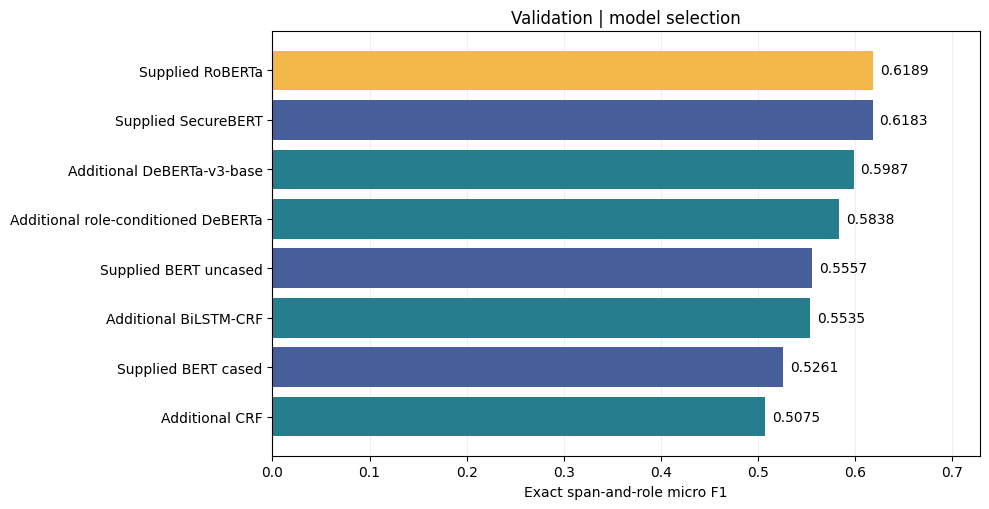

In [ ]:

import matplotlib.pyplot as plt
from pathlib import Path

ordered = sorted(val_res, key=lambda n: val_res[n]["overall"]["arg_c_f1"], reverse=True)
f1 = [val_res[n]["overall"]["arg_c_f1"] for n in ordered]
colors = ["#f2b84b" if n == selected else
          "#267d8e" if n.startswith("Additional ") else "#465e99" for n in ordered]
fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.barh(ordered, f1, color=colors)
ax.bar_label(bars, fmt="%.4f", padding=5)
ax.invert_yaxis()
ax.set(xlim=(0, min(1, max(f1) + .11)),
       xlabel="Exact span-and-role micro F1", title="Validation | model selection")
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("outputs/figures/final_validation_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## 11. Held-out test, with frozen validation-selected checkpoints

Evaluate the additional trained methods on test after the selection is fixed.
Compare with the supplied historical test prediction files, including
their CRF. Training code for the team methods is visible in Section 3, but
their original weights are unavailable. No test score is used for model tuning.


In [ ]:

import joblib

crf_test_model = joblib.load("outputs/crf_baseline/model.joblib")
crf_test_preds = {}
for record in datasets["test"]:
    lo, hi = event_window(record)
    labels_out = crf_test_model.predict_single(crf_features(record))
    crf_test_preds[record["event_uid"]] = decode_bio(labels_out, offset=lo)
ce.save_predictions("outputs/crf_baseline/test_predictions.jsonl", crf_test_preds)
assert len(crf_test_preds) == 736
print("Additional CRF test predictions saved.")


Additional CRF test predictions saved.


In [ ]:

deberta_test_model, deberta_test_tok, deberta_test_enc = ctr.load_trained(
    "outputs/deberta_v3_base", max_len=512
)
deberta_test_preds = ctr.predict_file(
    deberta_test_model, deberta_test_tok, deberta_test_enc,
    datasets["test"], "outputs/deberta_v3_base_test_predictions.jsonl"
)
assert len(deberta_test_preds) == 736
del deberta_test_model
torch.cuda.empty_cache()
print("Additional DeBERTa test predictions saved.")


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Additional DeBERTa test predictions saved.


In [ ]:

# Restore the best BiLSTM state; do not use weights from the final epoch.
from torch.utils.data import DataLoader
bi_state = torch.load("outputs/bilstm_crf/best_model.pt",
                      map_location="cpu", weights_only=False)
assert bi_state["best_epoch"] == best_epoch
assert bi_state["word_to_id"] == lstm_word_to_id
assert bi_state["labels"] == lstm_labels
bilstm_model = BiLSTMCRF(len(lstm_word_to_id), len(lstm_subtype_to_id),
                         len(lstm_labels)).to(device)
bilstm_model.load_state_dict(bi_state["model_state"])
bilstm_model.eval()
test_rows = [encode_lstm_row(row) for row in prepare_lstm_sequences(datasets["test"])]
test_loader = DataLoader(test_rows, batch_size=16, shuffle=False,
                         collate_fn=collate_lstm)
bi_test_preds = {}
with torch.no_grad():
    for words, triggers, subtypes, lengths, _, rows in test_loader:
        decoded = bilstm_model.decode(words.to(device), triggers.to(device),
                                      subtypes.to(device), lengths.to(device))
        for row, tag_ids in zip(rows, decoded):
            bi_test_preds[row["event_uid"]] = ce.bio_to_spans(
                [lstm_labels[t] for t in tag_ids], offset=row["window"][0]
            )
ce.save_predictions("outputs/bilstm_crf/test_predictions.jsonl", bi_test_preds)
assert len(bi_test_preds) == 736
del bilstm_model
torch.cuda.empty_cache()
print("Additional BiLSTM test predictions saved.")


Additional BiLSTM test predictions saved.


In [ ]:

role_test_preds = rp.predict_file(
    ROLE_OUT, datasets["test"], f"{ROLE_OUT}/test_predictions.jsonl"
)
assert len(role_test_preds) == 736
print("Role-conditioned DeBERTa test predictions saved.")


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Role-conditioned DeBERTa test predictions saved.


In [ ]:

test_files = {
    "Additional CRF": "outputs/crf_baseline/test_predictions.jsonl",
    "Additional BiLSTM-CRF": "outputs/bilstm_crf/test_predictions.jsonl",
    "Additional DeBERTa-v3-base": "outputs/deberta_v3_base_test_predictions.jsonl",
    "Additional role-conditioned DeBERTa": f"{ROLE_OUT}/test_predictions.jsonl",
    "Supplied CRF": "provided_predictions/test_crf.jsonl",
    "Supplied BERT cased": "provided_predictions/test_bert-base-cased.jsonl",
    "Supplied BERT uncased": "provided_predictions/test_bert-base-uncased.jsonl",
    "Supplied RoBERTa": "provided_predictions/test_roberta-base.jsonl",
    "Supplied SecureBERT": "provided_predictions/test_SecureBERT.jsonl",
}
test_res = {}
for name, filename in test_files.items():
    preds = ce.load_predictions(filename)
    assert set(preds) == {r["event_uid"] for r in datasets["test"]}
    test_res[name] = ce.evaluate(datasets["test"], preds, n_examples=5)
    assert not test_res[name]["warnings"]
test_table = pd.DataFrame([
    {"method": name, "source": "supplied prediction" if name.startswith("Supplied ") else "additional run",
     "Arg-C P": res["overall"]["arg_c_precision"],
     "Arg-C R": res["overall"]["arg_c_recall"],
     "Arg-C F1": res["overall"]["arg_c_f1"],
     "macro F1": res["overall"]["macro_f1"],
     "95% document bootstrap CI": ce.bootstrap_f1(res, n=1000, seed=42)}
    for name, res in test_res.items()
]).sort_values("Arg-C F1", ascending=False)
display(test_table)
assert selected in test_res
print("Validation-selected model test F1:", selected,
      test_res[selected]["overall"]["arg_c_f1"])


,method,source,Arg-C P,Arg-C R,Arg-C F1,macro F1,95% document bootstrap CI
7,Supplied RoBERTa,supplied prediction,0.621777,0.617354,0.619557,0.573554,"(0.5967914438502674, 0.6440992348713193)"
8,Supplied SecureBERT,supplied prediction,0.598291,0.630631,0.614035,0.556003,"(0.5918516711393023, 0.6371576022231045)"
3,Additional role-conditioned DeBERTa,additional run,0.517795,0.703651,0.596583,0.562911,"(0.5744642535566361, 0.619472182596291)"
2,Additional DeBERTa-v3-base,additional run,0.586383,0.600284,0.593252,0.503976,"(0.5675799086757992, 0.6193875201473635)"
6,Supplied BERT uncased,supplied prediction,0.539669,0.603129,0.569637,0.519730,"(0.5459839844697888, 0.5923612779245736)"
1,Additional BiLSTM-CRF,additional run,0.596802,0.495495,0.541451,0.492279,"(0.5113318054494524, 0.5722395685495315)"
5,Supplied BERT cased,supplied prediction,0.528922,0.541963,0.535363,0.448520,"(0.510012782275245, 0.5609022556390978)"
4,Supplied CRF,supplied prediction,0.639021,0.445709,0.525140,0.451540,"(0.4992238435268549, 0.5541516245487366)"
0,Additional CRF,additional run,0.630081,0.440967,0.518828,0.445309,"(0.491588785046729, 0.5463576158940397)"


Validation-selected model test F1: Supplied RoBERTa 0.6195574589578872


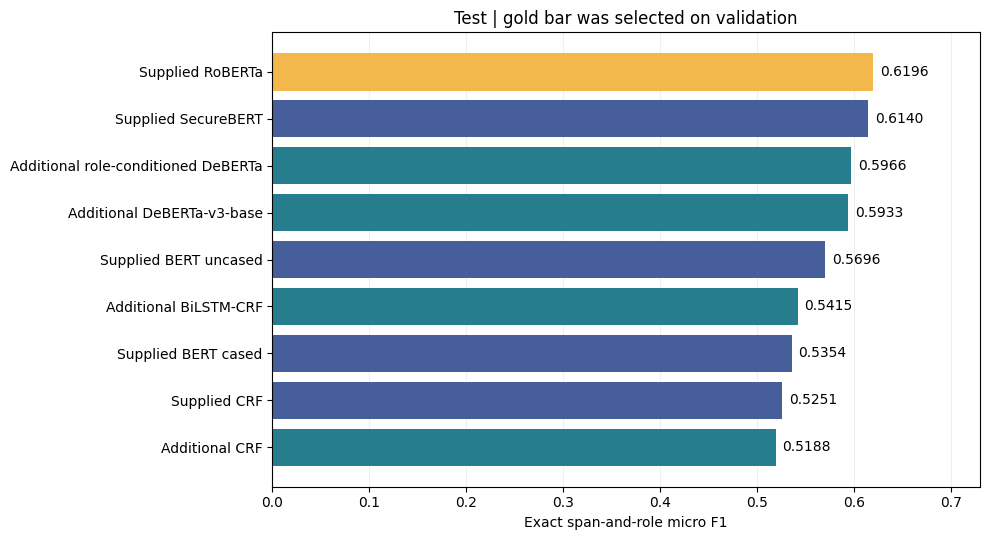

In [ ]:

ordered_test = sorted(test_res, key=lambda n: test_res[n]["overall"]["arg_c_f1"], reverse=True)
test_f1 = [test_res[n]["overall"]["arg_c_f1"] for n in ordered_test]
test_colors = ["#f2b84b" if n == selected else
               "#267d8e" if n.startswith("Additional ") else "#465e99"
               for n in ordered_test]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(ordered_test, test_f1, color=test_colors)
ax.bar_label(bars, fmt="%.4f", padding=5)
ax.invert_yaxis()
ax.set(xlim=(0, min(1, max(test_f1) + .11)),
       xlabel="Exact span-and-role micro F1", title="Test | gold bar was selected on validation")
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("outputs/figures/final_test_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## 12. Error analysis and uncertainty

Bootstrap confidence intervals and pair comparisons resample **documents**,
because events from the same document are correlated. The fraction of paired
resamples where one model wins is not a p-value. Role frequency, event subtype,
span boundaries and role confusions explain variation behind overall F1.


In [ ]:

winner = test_res[selected]
ce.print_report(winner, name=selected, top_confusions=10)
reference = "Supplied RoBERTa" if selected != "Supplied RoBERTa" else "Additional DeBERTa-v3-base"
print("Paired bootstrap, reference then selected:",
      ce.compare_models(test_res[reference], winner, n=1000, seed=42))
display(pd.DataFrame(winner["per_role"]).sort_values("support", ascending=False))
display(pd.DataFrame(winner["per_subtype"]))


RESULTS — Supplied RoBERTa   (736 events, 2109 gold arguments)
Arg-C (span + role)  P 0.6218  R 0.6174  F1 0.6196
Arg-I (span only)    P 0.6480  R 0.6434  F1 0.6457
Macro-F1 over roles  0.5736
Predicted 2094, correct 1302

PER ROLE (sorted by F1)
role                         support   pred       P       R      F1
Damage-Amount                      4      4   0.000   0.000   0.000  (<10, unstable)
Issues-Addressed                  27     19   0.211   0.148   0.174
Purpose                           64     42   0.333   0.219   0.264
Attack-Pattern                    86     93   0.269   0.291   0.279
Capabilities                      46     53   0.302   0.348   0.323
Vulnerable_System_Version         27     26   0.423   0.407   0.415
Trusted-Entity                    81     89   0.506   0.556   0.529
Patch-Number                      15     30   0.400   0.800   0.533
Supported_Platform                11     10   0.600   0.545   0.571
Vulnerable_System_Owner           33     28   0.643   0.

,role,support,predicted,tp,precision,recall,f1
21,Victim,325,292,187,0.640411,0.575385,0.606159
22,Vulnerability,223,202,142,0.702970,0.636771,0.668235
4,Compromised-Data,206,215,157,0.730233,0.762136,0.745843
23,Vulnerable_System,160,157,97,0.617834,0.606250,0.611987
1,Attacker,158,156,101,0.647436,0.639241,0.643312
18,Time,131,138,92,0.666667,0.702290,0.684015
6,Discoverer,127,126,91,0.722222,0.716535,0.719368
19,Tool,108,115,75,0.652174,0.694444,0.672646
0,Attack-Pattern,86,93,25,0.268817,0.290698,0.279330
10,Patch,82,85,57,0.670588,0.695122,0.682635


,event_subtype,support,predicted,tp,precision,recall,f1
0,Databreach,573,556,364,0.654676,0.635253,0.644818
1,DiscoverVulnerability,523,518,326,0.629344,0.623327,0.626321
2,PatchVulnerability,384,394,253,0.642132,0.658854,0.650386
3,Phishing,369,350,194,0.554286,0.525745,0.539638
4,Ransom,260,276,165,0.597826,0.634615,0.615672


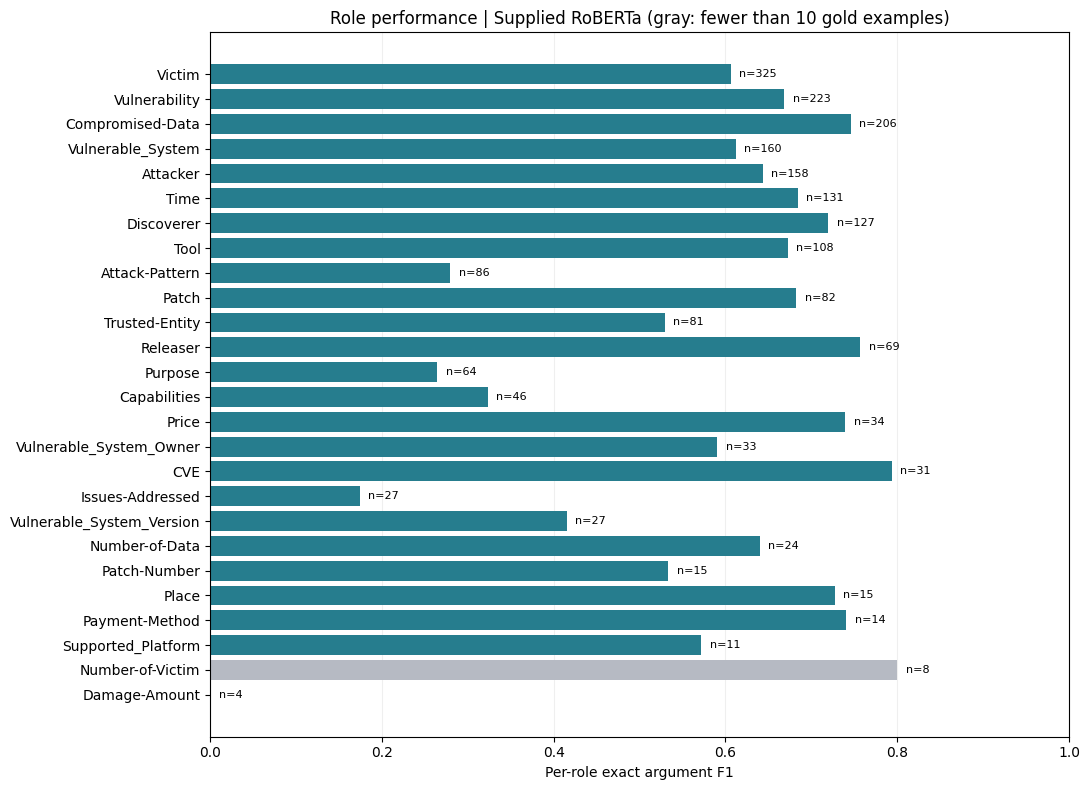

In [ ]:

role_rows = sorted(winner["per_role"], key=lambda r: r["support"], reverse=True)
fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh([r["role"] for r in role_rows], [r["f1"] for r in role_rows],
               color=["#267d8e" if r["support"] >= 10 else "#b6bac3" for r in role_rows])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="Per-role exact argument F1",
       title=f"Role performance | {selected} (gray: fewer than 10 gold examples)")
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
for bar, row in zip(bars, role_rows):
    ax.text(min(bar.get_width() + .01, .94), bar.get_y() + bar.get_height()/2,
            f"n={row['support']}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig("outputs/figures/selected_model_roles.png", dpi=160, bbox_inches="tight")
plt.show()


### Final interpretation of the executed benchmark

RoBERTa was fixed as the winner on validation (**0.6189 Arg-C F1**) and
achieved **0.6196** on test (95% document bootstrap CI **0.5968–0.6441**).
SecureBERT was close: **0.6183** validation and **0.6140** test. Their small
gap should not be described as a proven advantage without an appropriate
paired comparison. The role-conditioned model achieved **0.5838** validation
and **0.5966** test; it increased recall but did not beat RoBERTa on the
selection metric. The reported paired bootstrap fraction of **0.994** compares
RoBERTa with the *additional standard DeBERTa*, not with SecureBERT, and is
not a p-value.

For the selected RoBERTa, test recall falls from **0.748** at 1–5 tokens from
the trigger to **0.281** at 21–50 tokens. Attack-Pattern and Purpose also have
much lower per-role F1 than common roles. Rare roles (gray bars below ten gold
examples) have unstable individual estimates. This supports the task's
difficulty, but this dataset is not directly comparable to TextEE's split.


## 13. Optional per-event evidence export

The scientific results, tables and plots above are preserved as executed
notebook outputs. This cell additionally packages the underlying per-event
prediction files, CSV tables and PNG figures **while the runtime still holds
them**. The original session reset after Sections 10–12, before this ZIP was
created. Skipping this optional export does not erase the already executed
results. Rebuilding the complete per-event archive requires the saved input
bundle and checkpoints followed by inference, not retraining.


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

needed = ("validation_files", "test_files", "validation_table", "test_table", "selected")
absent = [name for name in needed if name not in globals()]
if absent:
    print("Optional export skipped: this runtime no longer contains the evaluated "
          "predictions and tables. The executed results above remain saved in the notebook.")
else:
    prediction_files = sorted(set(validation_files.values()) | set(test_files.values()))
    missing = [name for name in prediction_files if not Path(name).is_file()]
    if missing:
        print(f"Optional export skipped: {len(missing)} prediction files are missing "
              "after the runtime reset. Restore checkpoints and rerun inference to rebuild them.")
    else:
        evidence_zip = Path("/content/CASIE_Project2_Predictions_and_Results.zip")
        with ZipFile(evidence_zip, "w", compression=ZIP_DEFLATED) as archive:
            for filename in prediction_files:
                archive.write(filename)
            archive.writestr("validation_comparison.csv", validation_table.to_csv(index=False))
            archive.writestr("test_comparison.csv", test_table.to_csv(index=False))
            archive.writestr("selected_by_validation.txt", selected + "\n")
            for figure in sorted(Path("outputs/figures").glob("*.png")):
                archive.write(figure)
        print(f"Evidence archive ready: {evidence_zip.stat().st_size / 1e6:.1f} MB")
        files.download(str(evidence_zip))


## Appendix A. Retained raw CASIE preprocessing source

These condensed stages were supplied from the teammates' original raw
preprocessing notebook: annotation offset review, verified corrections and
deduplication, text-only tokenization, argument alignment, event-specific BIO
labels, document-level splitting and packaging. **They were not rerun or
independently verified end to end in this executed session.** The actual
corrected dataset used above was checked by hashes and split constraints in
Section 1. Do not treat these unused source cells as executed evidence.

`RUN_RAW_PREPROCESSING` defaults to `False` and requires the original raw
`annotation.zip` and the preprocessing intermediate files when enabled. Keep
this appendix separate from model evaluation; several names are reused.


In [ ]:
RUN_RAW_PREPROCESSING = False
print('Raw pipeline is available below; default: skip.')


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 1
    from google.colab import files
    from pathlib import Path
    import zipfile
    import json
    from collections import Counter

    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    assert len(zip_names) == 1, f"Please upload exactly one ZIP; found: {zip_names}"
    zip_path = Path(zip_names[0])
    print("Original archive:", zip_path.name)
    print("Size (MB):", round(zip_path.stat().st_size / 1_000_000, 2))

    # Original code cell 3
    with zipfile.ZipFile(zip_path) as archive:
        names = archive.namelist()
        json_files = sorted(name for name in names
                            if name.startswith('annotation/') and name.endswith('.json'))
        print('Total archive entries:', len(names))
        print('Annotation JSON files:', len(json_files))
        print('First five annotation paths:', json_files[:5])
        assert json_files, 'No annotation JSON files found in expected folder'
        sample_path = json_files[0]
        sample = json.loads(archive.read(sample_path))

    print('Sample:', sample_path)
    print('Top-level keys:', list(sample.keys()))
    print('cyberevent keys:', list(sample['cyberevent'].keys()))
    hoppers = sample['cyberevent'].get('hopper', [])
    print('Hoppers in sample:', len(hoppers))
    if hoppers:
        print('First hopper keys:', list(hoppers[0].keys()))
        events = hoppers[0].get('events', [])
        if events:
            event = events[0]
            print('First event ID/type/subtype:', event.get('index'), event.get('type'), event.get('subtype'))
            print('Trigger:', event.get('nugget'))
            print('Arguments in first event:', len(event.get('argument', [])))
            if event.get('argument'):
                print('First argument:', event['argument'][0])

    # Original code cell 5
    import json
    import zipfile
    from collections import Counter

    # 1. CONFIGURATION

    zip_path = "annotation.zip"

    # Counters
    event_types = Counter()
    event_subtypes = Counter()
    argument_roles = Counter()
    entity_types = Counter()

    events_per_document = []

    # General statistics
    total_documents = 0
    total_events = 0
    total_arguments = 0
    total_hoppers = 0

    documents_without_events = 0
    documents_with_multiple_events = 0
    events_without_arguments = 0

    # 2. READ DATASET

    with zipfile.ZipFile(zip_path, "r") as archive:

        json_files = sorted([
            name for name in archive.namelist()
            if name.startswith("annotation/")
            and name.endswith(".json")
            and not name.startswith("__MACOSX/")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            total_documents += 1

            # Get all event hoppers in the document
            hoppers = data.get("cyberevent", {}).get("hopper", [])

            total_hoppers += len(hoppers)

            document_event_count = 0

            for hopper in hoppers:

                events = hopper.get("events", [])

                for event in events:

                    total_events += 1
                    document_event_count += 1

                    # EVENT TYPE AND SUBTYPE

                    event_type = event.get("type", "MISSING")
                    event_subtype = event.get("subtype", "MISSING")

                    event_types[event_type] += 1
                    event_subtypes[event_subtype] += 1

                    # ARGUMENTS

                    arguments = event.get("argument", [])

                    if not arguments:
                        events_without_arguments += 1

                    for argument in arguments:

                        total_arguments += 1

                        # CASIE stores roles as:
                        # "role": {"type": "Compromised-Data"}

                        role_data = argument.get("role", {})

                        if isinstance(role_data, dict):
                            role = role_data.get("type", "MISSING")
                        elif isinstance(role_data, str):
                            role = role_data
                        else:
                            role = "MISSING"

                        argument_roles[role] += 1

                        # Entity type is separate from argument role
                        # Example: "type": "PII"

                        entity_type = argument.get("type", "MISSING")

                        entity_types[entity_type] += 1

            # DOCUMENT STATISTICS

            events_per_document.append(document_event_count)

            if document_event_count == 0:
                documents_without_events += 1

            if document_event_count > 1:
                documents_with_multiple_events += 1

    # 3. DISPLAY GENERAL STATISTICS

    print("=" * 60)
    print("CASIE DATASET STATISTICS")
    print("=" * 60)

    print(f"Total documents: {total_documents}")
    print(f"Total event hoppers: {total_hoppers}")
    print(f"Total event mentions: {total_events}")
    print(f"Total argument annotations: {total_arguments}")

    if total_documents > 0:
        print(
            f"Average events per document: "
            f"{total_events / total_documents:.2f}"
        )

    if total_events > 0:
        print(
            f"Average arguments per event: "
            f"{total_arguments / total_events:.2f}"
        )

    print(f"\nDocuments without events: {documents_without_events}")
    print(f"Documents with multiple events: {documents_with_multiple_events}")
    print(f"Events without arguments: {events_without_arguments}")

    # 4. EVENT TYPES

    print("\n" + "=" * 60)
    print("EVENT TYPES")
    print("=" * 60)

    for event_type, count in event_types.most_common():
        print(f"{event_type}: {count}")

    # 5. EVENT SUBTYPES

    print("\n" + "=" * 60)
    print("EVENT SUBTYPES")
    print("=" * 60)

    for subtype, count in event_subtypes.most_common():
        print(f"{subtype}: {count}")

    # 6. ARGUMENT ROLES

    print("\n" + "=" * 60)
    print("ARGUMENT ROLES")
    print("=" * 60)

    for role, count in argument_roles.most_common():
        print(f"{role}: {count}")

    # 7. ENTITY TYPES

    print("\n" + "=" * 60)
    print("ENTITY TYPES")
    print("=" * 60)

    for entity_type, count in entity_types.most_common():
        print(f"{entity_type}: {count}")

    # 8. EVENT DISTRIBUTION

    print("\n" + "=" * 60)
    print("EVENT DISTRIBUTION")
    print("=" * 60)

    if events_per_document:

        print(
            f"Minimum events per document: "
            f"{min(events_per_document)}"
        )

        print(
            f"Maximum events per document: "
            f"{max(events_per_document)}"
        )

        distribution = Counter(events_per_document)

        print("\nDocuments grouped by event count:")

        for number_of_events, document_count in sorted(distribution.items()):
            print(
                f"{number_of_events} events: "
                f"{document_count} documents"
            )

    # 9. FINAL VERIFICATION

    print("\n" + "=" * 60)
    print("VERIFICATION")
    print("=" * 60)

    print(f"JSON files processed: {len(json_files)}")

    print(
        f"Event type count matches total events: "
        f"{sum(event_types.values()) == total_events}"
    )

    print(
        f"Argument role count matches total arguments: "
        f"{sum(argument_roles.values()) == total_arguments}"
    )

    print(
        f"Entity type count matches total arguments: "
        f"{sum(entity_types.values()) == total_arguments}"
    )

    print(
        f"Document count matches distribution: "
        f"{sum(Counter(events_per_document).values()) == total_documents}"
    )

    print("\nStep 2 completed successfully.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 7
    import json
    import zipfile
    from collections import Counter
    import pandas as pd

    # 1. CONFIGURATION

    zip_path = "annotation.zip"

    issues = []
    issue_counts = Counter()

    documents_checked = 0
    events_checked = 0
    arguments_checked = 0

    # 2. ISSUE RECORDING FUNCTION

    def record_issue(
        document,
        event_id,
        argument_id,
        issue_type,
        details
    ):
        """
        Record a potential annotation problem.

        This function does not modify the dataset.
        """

        issues.append({
            "document": document,
            "event_id": event_id,
            "argument_id": argument_id,
            "issue_type": issue_type,
            "details": details
        })

        issue_counts[issue_type] += 1

    # 3. INSPECT DATASET

    with zipfile.ZipFile(zip_path, "r") as archive:

        json_files = sorted([
            name for name in archive.namelist()
            if name.startswith("annotation/")
            and name.endswith(".json")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            documents_checked += 1

            # DOCUMENT VALIDATION

            content = data.get("content")

            if not isinstance(content, str) or not content.strip():

                record_issue(
                    filename,
                    None,
                    None,
                    "Missing Document Text",
                    "Document content is missing or empty"
                )

            cyberevent = data.get("cyberevent", {})

            if not isinstance(cyberevent, dict):

                record_issue(
                    filename,
                    None,
                    None,
                    "Invalid CyberEvent Structure",
                    "cyberevent is not a dictionary"
                )

                continue

            hoppers = cyberevent.get("hopper", [])

            if not isinstance(hoppers, list):

                record_issue(
                    filename,
                    None,
                    None,
                    "Invalid Hopper Structure",
                    "hopper is not a list"
                )

                continue

            # HOPPER VALIDATION

            for hopper in hoppers:

                if not isinstance(hopper, dict):

                    record_issue(
                        filename,
                        None,
                        None,
                        "Invalid Hopper",
                        "Hopper is not a dictionary"
                    )

                    continue

                events = hopper.get("events", [])

                if not isinstance(events, list):

                    record_issue(
                        filename,
                        None,
                        None,
                        "Invalid Events Structure",
                        "events is not a list"
                    )

                    continue

                # EVENT VALIDATION

                for event in events:

                    events_checked += 1

                    if not isinstance(event, dict):

                        record_issue(
                            filename,
                            None,
                            None,
                            "Invalid Event",
                            "Event is not a dictionary"
                        )

                        continue

                    event_id = event.get("index")

                    if not event_id:

                        record_issue(
                            filename,
                            None,
                            None,
                            "Missing Event ID",
                            "Event index is missing"
                        )

                    if not event.get("type"):

                        record_issue(
                            filename,
                            event_id,
                            None,
                            "Missing Event Type",
                            "Event type is missing"
                        )

                    if not event.get("subtype"):

                        record_issue(
                            filename,
                            event_id,
                            None,
                            "Missing Event Subtype",
                            "Event subtype is missing"
                        )

                    # TRIGGER VALIDATION

                    trigger = event.get("nugget")

                    if not isinstance(trigger, dict):

                        record_issue(
                            filename,
                            event_id,
                            None,
                            "Missing or Invalid Trigger",
                            "Event nugget is missing or invalid"
                        )

                    else:

                        for field in [
                            "text",
                            "startOffset",
                            "endOffset"
                        ]:

                            if trigger.get(field) is None:

                                record_issue(
                                    filename,
                                    event_id,
                                    None,
                                    "Missing Trigger Field",
                                    f"Missing trigger field: {field}"
                                )

                    # ARGUMENT VALIDATION

                    arguments = event.get("argument", [])

                    if not isinstance(arguments, list):

                        record_issue(
                            filename,
                            event_id,
                            None,
                            "Invalid Argument Structure",
                            "argument is not a list"
                        )

                        continue

                    for argument in arguments:

                        arguments_checked += 1

                        if not isinstance(argument, dict):

                            record_issue(
                                filename,
                                event_id,
                                None,
                                "Invalid Argument",
                                "Argument is not a dictionary"
                            )

                            continue

                        argument_id = argument.get("index")

                        if not argument_id:

                            record_issue(
                                filename,
                                event_id,
                                None,
                                "Missing Argument ID",
                                "Argument index is missing"
                            )

                        # Check required argument fields

                        for field in [
                            "text",
                            "startOffset",
                            "endOffset"
                        ]:

                            if argument.get(field) is None:

                                record_issue(
                                    filename,
                                    event_id,
                                    argument_id,
                                    "Missing Argument Field",
                                    f"Missing argument field: {field}"
                                )

                        # Check role structure

                        role = argument.get("role")

                        if not isinstance(role, dict):

                            record_issue(
                                filename,
                                event_id,
                                argument_id,
                                "Invalid Argument Role",
                                "Role is not a dictionary"
                            )

                        elif not role.get("type"):

                            record_issue(
                                filename,
                                event_id,
                                argument_id,
                                "Missing Argument Role Type",
                                "role.type is missing"
                            )

    # 4. DISPLAY RESULTS

    print("=" * 60)
    print("STEP 3.1 — STRUCTURAL VALIDATION")
    print("=" * 60)

    print(f"Documents checked: {documents_checked}")
    print(f"Events checked: {events_checked}")
    print(f"Arguments checked: {arguments_checked}")

    print(f"\nTotal potential issues detected: {len(issues)}")

    print("\nIssue Categories:")

    if issue_counts:

        for issue_type, count in issue_counts.most_common():

            print(f"{issue_type}: {count}")

    else:

        print("No structural issues detected.")

    # 5. CREATE ISSUE REPORT

    issues_df = pd.DataFrame(
        issues,
        columns=[
            "document",
            "event_id",
            "argument_id",
            "issue_type",
            "details"
        ]
    )

    print("\nFirst 20 detected issues:")

    display(issues_df.head(20))

    # 6. SAVE REPORT

    issues_df.to_csv(
        "CASIE_structural_issues.csv",
        index=False
    )

    print("\nReport saved: CASIE_structural_issues.csv")

    # Original code cell 9
    import json
    import zipfile
    import pandas as pd
    from collections import Counter

    # 1. CONFIGURATION

    zip_path = "annotation.zip"

    offset_issues = []
    offset_issue_counts = Counter()

    total_triggers = 0
    total_arguments = 0

    valid_triggers = 0
    valid_arguments = 0

    # 2. OFFSET VALIDATION FUNCTION

    def validate_span(
        document_text,
        annotation,
        document_id,
        event_id,
        annotation_type
    ):
        """
        Validate the character offsets of an annotation.

        Checks:
        1. Offset types
        2. Offset boundaries
        3. Extracted text matches annotated text

        Returns True if the span is valid.
        """

        start = annotation.get("startOffset")
        end = annotation.get("endOffset")
        annotated_text = annotation.get("text")

        annotation_id = annotation.get("index")

        # CHECK 1: OFFSET TYPES

        if (
            type(start) is not int
            or type(end) is not int
        ):

            issue_type = "Invalid Offset Type"

            offset_issues.append({
                "document": document_id,
                "event_id": event_id,
                "annotation_id": annotation_id,
                "annotation_type": annotation_type,
                "issue_type": issue_type,
                "start": start,
                "end": end,
                "annotated_text": annotated_text,
                "extracted_text": None
            })

            offset_issue_counts[issue_type] += 1

            return False

        # CHECK 2: OFFSET BOUNDARIES

        if (
            start < 0
            or end <= start
            or end > len(document_text)
        ):

            issue_type = "Invalid Offset Boundary"

            offset_issues.append({
                "document": document_id,
                "event_id": event_id,
                "annotation_id": annotation_id,
                "annotation_type": annotation_type,
                "issue_type": issue_type,
                "start": start,
                "end": end,
                "annotated_text": annotated_text,
                "extracted_text": None
            })

            offset_issue_counts[issue_type] += 1

            return False

        # CHECK 3: TEXT MATCHING

        extracted_text = document_text[start:end]

        if extracted_text != annotated_text:

            # Distinguish whitespace-only mismatches
            if (
                isinstance(annotated_text, str)
                and extracted_text.strip() == annotated_text.strip()
            ):

                issue_type = "Whitespace Mismatch"

            else:

                issue_type = "Text Offset Mismatch"

            offset_issues.append({
                "document": document_id,
                "event_id": event_id,
                "annotation_id": annotation_id,
                "annotation_type": annotation_type,
                "issue_type": issue_type,
                "start": start,
                "end": end,
                "annotated_text": annotated_text,
                "extracted_text": extracted_text
            })

            offset_issue_counts[issue_type] += 1

            return False

        return True

    # 3. INSPECT ALL DOCUMENTS

    with zipfile.ZipFile(zip_path, "r") as archive:

        json_files = sorted([
            name for name in archive.namelist()
            if name.startswith("annotation/")
            and name.endswith(".json")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            document_text = data["content"]

            hoppers = data["cyberevent"]["hopper"]

            for hopper in hoppers:

                for event in hopper["events"]:

                    event_id = event.get("index")

                    # VALIDATE EVENT TRIGGER

                    trigger = event.get("nugget")

                    if isinstance(trigger, dict):

                        total_triggers += 1

                        if validate_span(
                            document_text,
                            trigger,
                            filename,
                            event_id,
                            "Trigger"
                        ):

                            valid_triggers += 1

                    # VALIDATE ARGUMENTS

                    for argument in event.get("argument", []):

                        total_arguments += 1

                        if validate_span(
                            document_text,
                            argument,
                            filename,
                            event_id,
                            "Argument"
                        ):

                            valid_arguments += 1

    # 4. DISPLAY RESULTS

    print("=" * 60)
    print("STEP 3.2 — CHARACTER OFFSET VALIDATION")
    print("=" * 60)

    print(f"Total triggers checked: {total_triggers}")
    print(f"Valid triggers: {valid_triggers}")

    print(f"\nTotal arguments checked: {total_arguments}")
    print(f"Valid arguments: {valid_arguments}")

    print(
        f"\nTotal offset issues: "
        f"{len(offset_issues)}"
    )

    print("\nIssue Categories:")

    if offset_issue_counts:

        for issue_type, count in offset_issue_counts.most_common():

            print(f"{issue_type}: {count}")

    else:

        print("No offset issues detected.")

    # 5. CREATE ISSUE REPORT

    offset_issues_df = pd.DataFrame(
        offset_issues,
        columns=[
            "document",
            "event_id",
            "annotation_id",
            "annotation_type",
            "issue_type",
            "start",
            "end",
            "annotated_text",
            "extracted_text"
        ]
    )

    print("\nFirst 20 detected issues:")

    display(offset_issues_df.head(20))

    # 6. SAVE REPORT

    offset_issues_df.to_csv(
        "CASIE_offset_issues.csv",
        index=False
    )

    print("\nReport saved: CASIE_offset_issues.csv")

    # 7. FINAL VERIFICATION

    print("\n" + "=" * 60)
    print("VERIFICATION")
    print("=" * 60)

    print(
        "Trigger counts consistent:",
        total_triggers ==
        valid_triggers +
        sum(
            1 for issue in offset_issues
            if issue["annotation_type"] == "Trigger"
        )
    )

    print(
        "Argument counts consistent:",
        total_arguments ==
        valid_arguments +
        sum(
            1 for issue in offset_issues
            if issue["annotation_type"] == "Argument"
        )
    )

    print("\nStep 3.2 completed.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 11
    import json
    import zipfile
    import pandas as pd
    from collections import Counter

    # 1. CONFIGURATION

    zip_path = "annotation.zip"

    # Results from Step 3.2
    issues_to_investigate = offset_issues_df.copy()

    # Store investigation results
    investigation_results = []

    # 2. LOAD ORIGINAL DOCUMENT TEXT

    document_cache = {}

    with zipfile.ZipFile(zip_path, "r") as archive:

        affected_documents = issues_to_investigate["document"].unique()

        for filename in affected_documents:

            with archive.open(filename) as file:
                data = json.load(file)

            document_cache[filename] = data["content"]

    # 3. INVESTIGATE EACH MISMATCH

    for _, issue in issues_to_investigate.iterrows():

        filename = issue["document"]
        document_text = document_cache[filename]

        start = issue["start"]
        end = issue["end"]

        annotated_text = issue["annotated_text"]

        possible_corrections = []

        # Only investigate valid integer offsets and text
        if (
            type(start) is int
            and type(end) is int
            and isinstance(annotated_text, str)
        ):

            # Test shifts between -2 and +2 characters
            for shift in [-2, -1, 0, 1, 2]:

                new_start = start + shift
                new_end = end + shift

                if (
                    new_start >= 0
                    and new_end <= len(document_text)
                    and new_end > new_start
                ):

                    extracted = document_text[new_start:new_end]

                    if extracted == annotated_text:

                        possible_corrections.append(shift)

        # 4. CLASSIFY THE ISSUE

        if len(possible_corrections) == 1:

            classification = "Unique Offset Shift"

            suggested_shift = possible_corrections[0]

        elif len(possible_corrections) > 1:

            classification = "Multiple Possible Shifts"

            suggested_shift = None

        else:

            classification = "Requires Manual Review"

            suggested_shift = None

        investigation_results.append({

            "document": filename,
            "event_id": issue["event_id"],
            "annotation_id": issue["annotation_id"],
            "annotation_type": issue["annotation_type"],

            "original_start": start,
            "original_end": end,

            "annotated_text": annotated_text,
            "extracted_text": issue["extracted_text"],

            "classification": classification,
            "possible_shifts": possible_corrections,
            "suggested_shift": suggested_shift
        })

    # 5. CREATE RESULTS DATAFRAME

    investigation_df = pd.DataFrame(investigation_results)

    print("=" * 60)
    print("STEP 3.3 — OFFSET MISMATCH INVESTIGATION")
    print("=" * 60)

    print(f"Total issues investigated: {len(investigation_df)}")

    print("\nIssue classifications:")

    print(
        investigation_df["classification"].value_counts()
    )

    print("\nSuggested offset shifts:")

    print(
        investigation_df["suggested_shift"].value_counts(
            dropna=False
        )
    )

    print("\nNumber of affected documents:")

    print(
        investigation_df["document"].nunique()
    )

    # 6. DISPLAY EXAMPLES

    print("\nFirst 20 investigation results:")

    display(
        investigation_df[
            [
                "document",
                "annotation_id",
                "annotated_text",
                "classification",
                "possible_shifts",
                "suggested_shift"
            ]
        ].head(20)
    )

    # 7. SAVE INVESTIGATION REPORT

    investigation_df.to_csv(
        "CASIE_offset_investigation.csv",
        index=False
    )

    print("\nReport saved: CASIE_offset_investigation.csv")

    # Original code cell 13
    import json
    import zipfile
    import pandas as pd

    # 1. IDENTIFY UNRESOLVED ANNOTATIONS

    unresolved = investigation_df[
        investigation_df["classification"] == "Requires Manual Review"
    ].copy()

    print("=" * 65)
    print("STEP 3.4 — UNRESOLVED OFFSET INVESTIGATION")
    print("=" * 65)

    print(f"Unresolved annotations: {len(unresolved)}")

    # 2. INVESTIGATE EACH ANNOTATION

    review_results = []

    with zipfile.ZipFile("annotation.zip", "r") as archive:

        for _, row in unresolved.iterrows():

            filename = row["document"]

            with archive.open(filename) as file:
                data = json.load(file)

            text = data["content"]

            start = int(row["original_start"])
            end = int(row["original_end"])

            annotated_text = row["annotated_text"]

            # Extract surrounding context
            context_start = max(0, start - 80)
            context_end = min(len(text), end + 80)

            context = text[context_start:context_end]

            # Search for exact matches within +/- 100 characters
            search_start = max(0, start - 100)
            search_end = min(len(text), end + 100)

            nearby_text = text[search_start:search_end]

            matches = []

            if isinstance(annotated_text, str) and annotated_text:

                position = nearby_text.find(annotated_text)

                while position != -1:

                    absolute_start = search_start + position
                    absolute_end = absolute_start + len(annotated_text)

                    matches.append({
                        "start": absolute_start,
                        "end": absolute_end,
                        "shift": absolute_start - start
                    })

                    position = nearby_text.find(
                        annotated_text,
                        position + 1
                    )

            review_results.append({

                "document": filename,
                "event_id": row["event_id"],
                "annotation_id": row["annotation_id"],
                "annotation_type": row["annotation_type"],

                "original_start": start,
                "original_end": end,

                "annotated_text": annotated_text,

                "original_extracted_text": (
                    text[start:end]
                    if 0 <= start < end <= len(text)
                    else "INVALID BOUNDARY"
                ),

                "surrounding_context": context,
                "nearby_exact_matches": matches,
                "number_of_matches": len(matches)
            })

    # 3. DISPLAY RESULTS

    review_df = pd.DataFrame(review_results)

    for index, row in review_df.iterrows():

        print("\n" + "=" * 65)

        print(f"CASE {index + 1}")

        print("=" * 65)

        print("Document:", row["document"])
        print("Event ID:", row["event_id"])
        print("Annotation ID:", row["annotation_id"])
        print("Annotation Type:", row["annotation_type"])

        print("\nOriginal offsets:")
        print(row["original_start"], "-", row["original_end"])

        print("\nAnnotated text:")
        print(repr(row["annotated_text"]))

        print("\nExtracted text:")
        print(repr(row["original_extracted_text"]))

        print("\nSurrounding context:")
        print(repr(row["surrounding_context"]))

        print("\nNearby exact matches:")
        print(row["nearby_exact_matches"])

    # 4. SAVE REVIEW REPORT

    review_df.to_csv(
        "CASIE_unresolved_offset_review.csv",
        index=False
    )

    print("\n" + "=" * 65)
    print("INVESTIGATION COMPLETE")
    print("=" * 65)

    print(f"Annotations reviewed: {len(review_df)}")

    print(
        "Annotations with nearby exact matches:",
        (review_df["number_of_matches"] > 0).sum()
    )

    print(
        "Annotations without nearby exact matches:",
        (review_df["number_of_matches"] == 0).sum()
    )

    print("\nReport saved: CASIE_unresolved_offset_review.csv")

    # Original code cell 15
    import json
    import zipfile
    import pandas as pd
    from collections import Counter

    # 1. CONFIGURATION

    zip_path = "annotation.zip"

    corrections = []

    # 2. COMBINE PROPOSED CORRECTIONS

    # Step 3.3: Unique shifts of -1 and -2
    unique_shifts = investigation_df[
        investigation_df["classification"] == "Unique Offset Shift"
    ].copy()

    for _, row in unique_shifts.iterrows():

        shift = int(row["suggested_shift"])

        corrections.append({
            "document": row["document"],
            "event_id": row["event_id"],
            "annotation_id": row["annotation_id"],
            "annotation_type": row["annotation_type"],
            "original_start": int(row["original_start"]),
            "original_end": int(row["original_end"]),
            "corrected_start": int(row["original_start"]) + shift,
            "corrected_end": int(row["original_end"]) + shift,
            "annotated_text": row["annotated_text"],
            "shift": shift,
            "status": "Proposed"
        })

    # Step 3.4: Unique nearby exact matches
    for _, row in review_df.iterrows():

        matches = row["nearby_exact_matches"]

        if len(matches) == 1:

            match = matches[0]

            corrections.append({
                "document": row["document"],
                "event_id": row["event_id"],
                "annotation_id": row["annotation_id"],
                "annotation_type": row["annotation_type"],
                "original_start": int(row["original_start"]),
                "original_end": int(row["original_end"]),
                "corrected_start": match["start"],
                "corrected_end": match["end"],
                "annotated_text": row["annotated_text"],
                "shift": match["shift"],
                "status": "Proposed"
            })

    corrections_df = pd.DataFrame(corrections)

    # 3. VERIFY CORRECTED OFFSETS

    verification_results = []

    with zipfile.ZipFile(zip_path, "r") as archive:

        for _, row in corrections_df.iterrows():

            with archive.open(row["document"]) as file:
                data = json.load(file)

            text = data["content"]

            start = int(row["corrected_start"])
            end = int(row["corrected_end"])

            extracted = text[start:end]

            matches = extracted == row["annotated_text"]

            verification_results.append(matches)

    corrections_df["verified"] = verification_results

    # 4. CHECK REPEATED ANNOTATION IDS

    # Annotation IDs may repeat across different documents.
    # Therefore, document ID must be part of the key.

    annotation_groups = corrections_df.groupby(
        ["document", "annotation_id"],
        dropna=False
    )

    conflicting_annotations = []

    for key, group in annotation_groups:

        unique_corrections = group[
            ["corrected_start", "corrected_end", "annotated_text"]
        ].drop_duplicates()

        if len(unique_corrections) > 1:

            conflicting_annotations.append({
                "document": key[0],
                "annotation_id": key[1],
                "number_of_corrections": len(unique_corrections)
            })

    conflicts_df = pd.DataFrame(conflicting_annotations)

    # 5. DISPLAY RESULTS

    print("=" * 60)
    print("STEP 3.5 — OFFSET CORRECTION VERIFICATION")
    print("=" * 60)

    print(f"Total proposed corrections: {len(corrections_df)}")

    print(
        "Verified exact-text corrections:",
        corrections_df["verified"].sum()
    )

    print(
        "Failed corrections:",
        (~corrections_df["verified"]).sum()
    )

    print(
        "Conflicting annotation IDs:",
        len(conflicts_df)
    )

    print("\nCorrection shifts:")

    print(
        corrections_df["shift"].value_counts().sort_index()
    )

    print("\nFirst 15 corrections:")

    display(corrections_df.head(15))

    # 6. SAVE CORRECTION REPORTS

    corrections_df.to_csv(
        "CASIE_proposed_offset_corrections.csv",
        index=False
    )

    conflicts_df.to_csv(
        "CASIE_offset_conflicts.csv",
        index=False
    )

    print("\nReports saved:")
    print("- CASIE_proposed_offset_corrections.csv")
    print("- CASIE_offset_conflicts.csv")

    # Original code cell 17
    import json
    import zipfile
    import copy
    import pandas as pd
    from collections import Counter

    # 1. CONFIGURATION

    original_zip = "annotation.zip"
    cleaned_zip = "CASIE_cleaned_annotations.zip"

    # Only use verified corrections
    verified_corrections = corrections_df[
        corrections_df["verified"] == True
    ].copy()

    # Create lookup using document, event ID, annotation ID,
    # and annotation type to avoid applying a correction
    # to an unrelated annotation.

    correction_lookup = {}

    for _, row in verified_corrections.iterrows():

        key = (
            row["document"],
            row["event_id"],
            row["annotation_id"],
            row["annotation_type"]
        )

        if key in correction_lookup:
            raise ValueError(f"Duplicate correction key: {key}")

        correction_lookup[key] = row.to_dict()

    # 2. APPLY CORRECTIONS

    applied_corrections = []
    used_correction_keys = set()

    documents_processed = 0
    corrections_applied = 0

    with zipfile.ZipFile(original_zip, "r") as source_archive:

        json_files = sorted([
            name for name in source_archive.namelist()
            if name.startswith("annotation/")
            and name.endswith(".json")
        ])

        with zipfile.ZipFile(
            cleaned_zip,
            "w",
            compression=zipfile.ZIP_DEFLATED
        ) as output_archive:

            for filename in json_files:

                with source_archive.open(filename) as file:
                    original_data = json.load(file)

                # Preserve the original data in memory
                cleaned_data = copy.deepcopy(original_data)

                documents_processed += 1

                document_text = cleaned_data["content"]

                for hopper in cleaned_data["cyberevent"]["hopper"]:

                    for event in hopper["events"]:

                        event_id = event.get("index")

                        # PROCESS TRIGGER

                        annotations = []

                        trigger = event.get("nugget")

                        if isinstance(trigger, dict):
                            annotations.append(("Trigger", trigger))

                        # PROCESS ARGUMENTS

                        for argument in event.get("argument", []):
                            annotations.append(("Argument", argument))

                        # APPLY VERIFIED CORRECTIONS

                        for annotation_type, annotation in annotations:

                            annotation_id = annotation.get("index")

                            key = (
                                filename,
                                event_id,
                                annotation_id,
                                annotation_type
                            )

                            if key not in correction_lookup:
                                continue

                            correction = correction_lookup[key]

                            old_start = annotation["startOffset"]
                            old_end = annotation["endOffset"]

                            new_start = int(
                                correction["corrected_start"]
                            )

                            new_end = int(
                                correction["corrected_end"]
                            )

                            # Ensure correction matches original offsets
                            if (
                                old_start != correction["original_start"]
                                or old_end != correction["original_end"]
                            ):
                                raise ValueError(
                                    f"Original offset mismatch: {key}"
                                )

                            # Ensure corrected text matches annotation
                            if (
                                document_text[new_start:new_end]
                                != annotation["text"]
                            ):
                                raise ValueError(
                                    f"Corrected text mismatch: {key}"
                                )

                            annotation["startOffset"] = new_start
                            annotation["endOffset"] = new_end

                            corrections_applied += 1
                            used_correction_keys.add(key)

                            applied_corrections.append({
                                "document": filename,
                                "event_id": event_id,
                                "annotation_id": annotation_id,
                                "annotation_type": annotation_type,
                                "original_start": old_start,
                                "original_end": old_end,
                                "corrected_start": new_start,
                                "corrected_end": new_end,
                                "shift": new_start - old_start,
                                "decision": "Applied verified exact-text shift"
                            })

                # Save corrected document
                output_archive.writestr(
                    filename,
                    json.dumps(
                        cleaned_data,
                        ensure_ascii=False,
                        indent=2
                    )
                )

    # 3. VERIFY ALL PROPOSED CORRECTIONS WERE APPLIED

    missing_keys = (
        set(correction_lookup.keys()) - used_correction_keys
    )

    print("=" * 60)
    print("STEP 3.6 — OFFSET CORRECTIONS APPLIED")
    print("=" * 60)

    print(f"Documents processed: {documents_processed}")
    print(f"Proposed verified corrections: {len(correction_lookup)}")
    print(f"Corrections applied: {corrections_applied}")
    print(f"Unapplied correction keys: {len(missing_keys)}")

    if missing_keys:
        print("Unapplied keys:", list(missing_keys)[:10])

    # 4. REVALIDATE CORRECTED DATASET

    remaining_issues = []

    total_annotations = 0
    valid_annotations = 0

    with zipfile.ZipFile(cleaned_zip, "r") as archive:

        for filename in sorted(archive.namelist()):

            with archive.open(filename) as file:
                data = json.load(file)

            text = data["content"]

            for hopper in data["cyberevent"]["hopper"]:

                for event in hopper["events"]:

                    annotations = []

                    if isinstance(event.get("nugget"), dict):
                        annotations.append(
                            ("Trigger", event["nugget"])
                        )

                    for argument in event.get("argument", []):
                        annotations.append(
                            ("Argument", argument)
                        )

                    for annotation_type, annotation in annotations:

                        total_annotations += 1

                        start = annotation["startOffset"]
                        end = annotation["endOffset"]

                        valid = (
                            type(start) is int
                            and type(end) is int
                            and 0 <= start < end <= len(text)
                            and text[start:end] == annotation["text"]
                        )

                        if valid:
                            valid_annotations += 1

                        else:
                            remaining_issues.append({
                                "document": filename,
                                "event_id": event.get("index"),
                                "annotation_id": annotation.get("index"),
                                "annotation_type": annotation_type,
                                "start": start,
                                "end": end,
                                "annotated_text": annotation.get("text")
                            })

    # 5. SAVE REPORTS

    applied_df = pd.DataFrame(applied_corrections)

    remaining_df = pd.DataFrame(remaining_issues)

    applied_df.to_csv(
        "CASIE_applied_corrections.csv",
        index=False
    )

    remaining_df.to_csv(
        "CASIE_remaining_offset_issues.csv",
        index=False
    )

    # 6. FINAL RESULTS

    print("\n" + "=" * 60)
    print("POST-CLEANING VALIDATION")
    print("=" * 60)

    print(f"Total annotations: {total_annotations}")
    print(f"Valid annotations: {valid_annotations}")
    print(f"Remaining issues: {len(remaining_issues)}")

    print("\nRemaining problematic annotations:")

    display(remaining_df)

    print("\nFiles created:")
    print("- CASIE_cleaned_annotations.zip")
    print("- CASIE_applied_corrections.csv")
    print("- CASIE_remaining_offset_issues.csv")

    assert documents_processed == 1000
    assert corrections_applied == len(correction_lookup)
    assert len(missing_keys) == 0
    assert total_annotations == 31186

    print("\nStep 3.6 completed successfully.")

    # Original code cell 19
    import json
    import zipfile

    # STEP 3.7 — FINAL TRIGGER INVESTIGATION

    zip_path = "CASIE_cleaned_annotations.zip"
    filename = "annotation/464.json"

    with zipfile.ZipFile(zip_path, "r") as archive:
        with archive.open(filename) as file:
            data = json.load(file)

    text = data["content"]

    # Find the exact event and trigger
    target_event = None

    for hopper in data["cyberevent"]["hopper"]:
        for event in hopper["events"]:
            if event.get("index") == "E10":
                target_event = event
                break

        if target_event is not None:
            break

    assert target_event is not None, "Event E10 not found"

    trigger = target_event["nugget"]

    assert trigger.get("index") == "T28", "Unexpected trigger ID"

    print("=" * 60)
    print("FINAL TRIGGER INVESTIGATION")
    print("=" * 60)

    print("Document length:", len(text))

    print("\nOriginal trigger:")
    print(repr(trigger["text"]))

    print("\nOriginal offsets:")
    print(trigger["startOffset"], trigger["endOffset"])

    print("\nDocument ending:")
    print(repr(text[-150:]))

    # Search for the trigger without its final period
    candidate_text = "been leaked"

    matches = []

    position = text.find(candidate_text)

    while position != -1:
        matches.append(position)
        position = text.find(candidate_text, position + 1)

    print("\nCandidate text:", repr(candidate_text))
    print("Number of matches:", len(matches))

    for position in matches:
        end = position + len(candidate_text)

        print("\nCandidate start:", position)
        print("Candidate end:", end)
        print("Extracted text:", repr(text[position:end]))
        print("Distance from original start:",
              position - trigger["startOffset"])

        print(
            "Surrounding context:",
            repr(text[max(0, position - 60):min(len(text), end + 60)])
        )

    print("\nInvestigation completed. No files modified.")

    # Original code cell 21
    import json
    import zipfile
    import pandas as pd

    # STEP 3.8 — FINAL OFFSET CORRECTION

    input_zip = "CASIE_cleaned_annotations.zip"
    output_zip = "CASIE_offset_cleaned_final.zip"

    target_document = "annotation/464.json"
    target_event_id = "E10"
    target_trigger_id = "T28"

    correction_applied = 0

    # 1. CREATE FINAL CLEANED DATASET

    with zipfile.ZipFile(input_zip, "r") as source:

        with zipfile.ZipFile(
            output_zip,
            "w",
            compression=zipfile.ZIP_DEFLATED
        ) as destination:

            for filename in source.namelist():

                if not filename.endswith(".json"):
                    continue

                with source.open(filename) as file:
                    data = json.load(file)

                if filename == target_document:

                    text = data["content"]

                    # Confirm the document has the expected ending
                    assert text.endswith("been leaked")

                    # Confirm the correction location
                    assert text[2429:2440] == "been leaked"

                    # Locate the exact event
                    for hopper in data["cyberevent"]["hopper"]:

                        for event in hopper["events"]:

                            if event.get("index") != target_event_id:
                                continue

                            trigger = event.get("nugget")

                            if not isinstance(trigger, dict):
                                continue

                            if trigger.get("index") != target_trigger_id:
                                continue

                            # Verify original annotation
                            assert trigger["text"] == "been leaked."
                            assert trigger["startOffset"] == 2429
                            assert trigger["endOffset"] == 2441

                            # Apply minimal correction
                            trigger["text"] = "been leaked"
                            trigger["endOffset"] = 2440

                            correction_applied += 1

                destination.writestr(
                    filename,
                    json.dumps(
                        data,
                        ensure_ascii=False,
                        indent=2
                    )
                )

    assert correction_applied == 1, (
        f"Expected one correction, applied {correction_applied}"
    )

    print("Final annotation correction applied successfully.")

    # 2. VALIDATE EVERY ANNOTATION

    documents_checked = 0
    events_checked = 0
    triggers_checked = 0
    arguments_checked = 0

    validation_issues = []

    with zipfile.ZipFile(output_zip, "r") as archive:

        json_files = [
            filename
            for filename in archive.namelist()
            if filename.startswith("annotation/")
            and filename.endswith(".json")
        ]

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            documents_checked += 1

            text = data["content"]

            for hopper in data["cyberevent"]["hopper"]:

                for event in hopper["events"]:

                    events_checked += 1

                    annotations = []

                    trigger = event.get("nugget")

                    if isinstance(trigger, dict):
                        annotations.append(("Trigger", trigger))
                        triggers_checked += 1

                    for argument in event.get("argument", []):
                        annotations.append(("Argument", argument))
                        arguments_checked += 1

                    for annotation_type, annotation in annotations:

                        start = annotation.get("startOffset")
                        end = annotation.get("endOffset")
                        annotated_text = annotation.get("text")

                        valid = (
                            type(start) is int
                            and type(end) is int
                            and isinstance(annotated_text, str)
                            and 0 <= start < end <= len(text)
                            and text[start:end] == annotated_text
                        )

                        if not valid:

                            validation_issues.append({
                                "document": filename,
                                "event_id": event.get("index"),
                                "annotation_id": annotation.get("index"),
                                "annotation_type": annotation_type,
                                "start": start,
                                "end": end,
                                "annotated_text": annotated_text
                            })

    # 3. SAVE FINAL CORRECTION LOG

    final_correction = pd.DataFrame([{
        "document": target_document,
        "event_id": target_event_id,
        "annotation_id": target_trigger_id,
        "annotation_type": "Trigger",
        "original_start": 2429,
        "original_end": 2441,
        "original_text": "been leaked.",
        "corrected_start": 2429,
        "corrected_end": 2440,
        "corrected_text": "been leaked",
        "reason": "Removed punctuation absent from document text",
        "decision": "Applied"
    }])

    final_correction.to_csv(
        "CASIE_final_annotation_correction.csv",
        index=False
    )

    validation_df = pd.DataFrame(validation_issues)

    validation_df.to_csv(
        "CASIE_final_offset_validation.csv",
        index=False
    )

    # 4. DISPLAY RESULTS

    print("\n" + "=" * 60)
    print("STEP 3.8 — FINAL OFFSET VALIDATION")
    print("=" * 60)

    print(f"Documents checked: {documents_checked}")
    print(f"Events checked: {events_checked}")
    print(f"Triggers checked: {triggers_checked}")
    print(f"Arguments checked: {arguments_checked}")

    print(
        "Total annotations checked:",
        triggers_checked + arguments_checked
    )

    print("Remaining offset issues:", len(validation_issues))

    print("\nVerification:")

    print("Document count correct:", documents_checked == 1000)
    print("Event count correct:", events_checked == 8485)
    print("Trigger count correct:", triggers_checked == 8485)
    print("Argument count correct:", arguments_checked == 22701)
    print("All offsets valid:", len(validation_issues) == 0)

    assert documents_checked == 1000
    assert events_checked == 8485
    assert triggers_checked == 8485
    assert arguments_checked == 22701
    assert len(validation_issues) == 0

    print("\nFiles created:")
    print("- CASIE_offset_cleaned_final.zip")
    print("- CASIE_final_annotation_correction.csv")
    print("- CASIE_final_offset_validation.csv")

    print("\nStep 3.8 completed successfully.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 23
    import json
    import zipfile
    import pandas as pd
    from collections import defaultdict, Counter

    # STEP 3.9 — OVERLAP AND REPEATED REFERENCE ANALYSIS

    zip_path = "CASIE_offset_cleaned_final.zip"

    within_event_overlaps = []
    across_event_overlaps = []
    repeated_annotation_ids = []
    conflicting_roles = []

    documents_checked = 0
    events_checked = 0

    # 1. HELPER FUNCTION

    def spans_overlap(a, b):
        """
        Return True when two character spans overlap.

        Spans use [start, end) indexing.
        """
        return (
            a["start"] < b["end"]
            and b["start"] < a["end"]
        )

    def annotation_record(argument, event_id, event_uid):
        """
        Extract argument information while preserving
        its relationship to the event.
        """

        return {
            "annotation_id": argument.get("index"),
            "event_id": event_id,
            "event_uid": event_uid,
            "start": argument["startOffset"],
            "end": argument["endOffset"],
            "text": argument.get("text"),
            "role": argument.get("role", {}).get("type"),
            "entity_type": argument.get("type")
        }

    # 2. READ CLEANED DATASET

    with zipfile.ZipFile(zip_path, "r") as archive:

        json_files = sorted([
            filename
            for filename in archive.namelist()
            if filename.startswith("annotation/")
            and filename.endswith(".json")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            documents_checked += 1

            document_arguments = []
            annotation_references = defaultdict(list)

            # PROCESS EACH EVENT

            for hopper_position, hopper in enumerate(
                data["cyberevent"]["hopper"]
            ):

                for event_position, event in enumerate(
                    hopper["events"]
                ):

                    events_checked += 1

                    event_id = event.get("index")

                    # Unique event occurrence identifier
                    event_uid = (
                        f"{hopper_position}:{event_position}"
                    )

                    event_arguments = []

                    for argument in event.get("argument", []):

                        record = annotation_record(
                            argument,
                            event_id,
                            event_uid
                        )

                        event_arguments.append(record)
                        document_arguments.append(record)

                        annotation_id = record["annotation_id"]

                        annotation_references[annotation_id].append(
                            record
                        )

                    # CHECK OVERLAPS WITHIN THIS EVENT

                    for i in range(len(event_arguments)):

                        for j in range(i + 1, len(event_arguments)):

                            arg1 = event_arguments[i]
                            arg2 = event_arguments[j]

                            if spans_overlap(arg1, arg2):

                                within_event_overlaps.append({
                                    "document": filename,
                                    "event_id": event_id,
                                    "event_uid": event_uid,
                                    "argument_1": arg1["annotation_id"],
                                    "argument_2": arg2["annotation_id"],
                                    "text_1": arg1["text"],
                                    "text_2": arg2["text"],
                                    "role_1": arg1["role"],
                                    "role_2": arg2["role"],
                                    "start_1": arg1["start"],
                                    "end_1": arg1["end"],
                                    "start_2": arg2["start"],
                                    "end_2": arg2["end"]
                                })

            # CHECK OVERLAPS ACROSS DIFFERENT EVENTS

            for i in range(len(document_arguments)):

                for j in range(i + 1, len(document_arguments)):

                    arg1 = document_arguments[i]
                    arg2 = document_arguments[j]

                    # Only compare different event occurrences
                    if arg1["event_uid"] == arg2["event_uid"]:
                        continue

                    if spans_overlap(arg1, arg2):

                        across_event_overlaps.append({
                            "document": filename,
                            "event_1": arg1["event_id"],
                            "event_2": arg2["event_id"],
                            "event_uid_1": arg1["event_uid"],
                            "event_uid_2": arg2["event_uid"],
                            "argument_1": arg1["annotation_id"],
                            "argument_2": arg2["annotation_id"],
                            "text_1": arg1["text"],
                            "text_2": arg2["text"],
                            "role_1": arg1["role"],
                            "role_2": arg2["role"]
                        })

            # CHECK REPEATED ANNOTATION IDS

            for annotation_id, references in annotation_references.items():

                if len(references) <= 1:
                    continue

                unique_events = {
                    ref["event_uid"]
                    for ref in references
                }

                unique_spans = {
                    (
                        ref["start"],
                        ref["end"],
                        ref["text"]
                    )
                    for ref in references
                }

                unique_roles = {
                    ref["role"]
                    for ref in references
                }

                repeated_annotation_ids.append({
                    "document": filename,
                    "annotation_id": annotation_id,
                    "reference_count": len(references),
                    "unique_event_count": len(unique_events),
                    "unique_span_count": len(unique_spans),
                    "unique_role_count": len(unique_roles)
                })

                # Same annotation ID assigned different roles
                if len(unique_roles) > 1:

                    conflicting_roles.append({
                        "document": filename,
                        "annotation_id": annotation_id,
                        "roles": sorted(
                            str(role)
                            for role in unique_roles
                        ),
                        "reference_count": len(references)
                    })

    # 3. CREATE DATAFRAMES

    within_df = pd.DataFrame(within_event_overlaps)
    across_df = pd.DataFrame(across_event_overlaps)
    repeated_df = pd.DataFrame(repeated_annotation_ids)
    roles_df = pd.DataFrame(conflicting_roles)

    # 4. DISPLAY RESULTS

    print("=" * 65)
    print("STEP 3.9 — OVERLAP AND REFERENCE ANALYSIS")
    print("=" * 65)

    print(f"Documents checked: {documents_checked}")
    print(f"Events checked: {events_checked}")

    print("\nOVERLAP RESULTS")
    print("-" * 65)

    print(
        "Overlapping argument pairs within events:",
        len(within_df)
    )

    print(
        "Overlapping argument pairs across events:",
        len(across_df)
    )

    print("\nANNOTATION REFERENCE RESULTS")
    print("-" * 65)

    print(
        "Repeated argument annotation IDs:",
        len(repeated_df)
    )

    print(
        "Repeated IDs with different roles:",
        len(roles_df)
    )

    if not repeated_df.empty:

        print(
            "Repeated IDs with different spans:",
            (repeated_df["unique_span_count"] > 1).sum()
        )

    else:

        print("Repeated IDs with different spans: 0")

    # 5. DISPLAY EXAMPLES

    print("\nFirst 10 within-event overlaps:")
    display(within_df.head(10))

    print("\nFirst 10 across-event overlaps:")
    display(across_df.head(10))

    print("\nFirst 10 repeated annotation IDs:")
    display(repeated_df.head(10))

    print("\nFirst 10 role conflicts:")
    display(roles_df.head(10))

    # 6. SAVE REPORTS

    within_df.to_csv(
        "CASIE_within_event_overlaps.csv",
        index=False
    )

    across_df.to_csv(
        "CASIE_across_event_overlaps.csv",
        index=False
    )

    repeated_df.to_csv(
        "CASIE_repeated_annotation_ids.csv",
        index=False
    )

    roles_df.to_csv(
        "CASIE_annotation_role_conflicts.csv",
        index=False
    )

    print("\nReports saved:")
    print("- CASIE_within_event_overlaps.csv")
    print("- CASIE_across_event_overlaps.csv")
    print("- CASIE_repeated_annotation_ids.csv")
    print("- CASIE_annotation_role_conflicts.csv")

    # 7. BASIC VERIFICATION

    assert documents_checked == 1000
    assert events_checked == 8485

    print("\nStep 3.9 completed successfully.")

    # Original code cell 25
    import json
    import zipfile
    import pandas as pd

    # STEP 3.10 — REVIEW WITHIN-EVENT OVERLAPS

    zip_path = "CASIE_offset_cleaned_final.zip"

    cases = [
        ("annotation/364.json", "E7", "T33"),
        ("annotation/471.json", "E9", "T24"),
        ("annotation/860.json", "E7", "T27")
    ]

    review_records = []

    with zipfile.ZipFile(zip_path, "r") as archive:

        for filename, target_event_id, target_annotation_id in cases:

            with archive.open(filename) as file:
                data = json.load(file)

            document_text = data["content"]

            matching_events = []

            # Find the event and its hopper position
            for hopper_index, hopper in enumerate(
                data["cyberevent"]["hopper"]
            ):

                for event_index, event in enumerate(
                    hopper["events"]
                ):

                    if event.get("index") == target_event_id:

                        matching_events.append({
                            "hopper_index": hopper_index,
                            "event_index": event_index,
                            "event": event
                        })

            print("\n" + "=" * 70)
            print("DOCUMENT:", filename)
            print("EVENT:", target_event_id)
            print("ANNOTATION:", target_annotation_id)
            print("=" * 70)

            print("Matching event records:", len(matching_events))

            for event_record in matching_events:

                event = event_record["event"]

                print("\nEvent type:", event.get("type"))
                print("Event subtype:", event.get("subtype"))

                trigger = event.get("nugget", {})

                print("Event trigger:", trigger.get("text"))

                matching_arguments = [
                    argument
                    for argument in event.get("argument", [])
                    if argument.get("index") == target_annotation_id
                ]

                print(
                    "\nMatching argument references:",
                    len(matching_arguments)
                )

                for argument in matching_arguments:

                    start = argument["startOffset"]
                    end = argument["endOffset"]

                    role = argument.get("role", {}).get("type")

                    print("\nArgument record:")
                    print(json.dumps(
                        argument,
                        indent=2,
                        ensure_ascii=False
                    ))

                    print("\nRole:", role)

                    print("\nContext:")
                    print(
                        repr(
                            document_text[
                                max(0, start - 120):
                                min(len(document_text), end + 120)
                            ]
                        )
                    )

                    review_records.append({
                        "document": filename,
                        "event_id": target_event_id,
                        "hopper_index": event_record["hopper_index"],
                        "event_index": event_record["event_index"],
                        "event_type": event.get("type"),
                        "event_subtype": event.get("subtype"),
                        "trigger": trigger.get("text"),
                        "annotation_id": target_annotation_id,
                        "text": argument.get("text"),
                        "start": start,
                        "end": end,
                        "role": role,
                        "entity_type": argument.get("type"),
                        "argument_json": json.dumps(
                            argument,
                            ensure_ascii=False,
                            sort_keys=True
                        )
                    })

    # CREATE REVIEW TABLE

    review_df_310 = pd.DataFrame(review_records)

    print("\n" + "=" * 70)
    print("STEP 3.10 — SUMMARY")
    print("=" * 70)

    display(
        review_df_310[
            [
                "document",
                "event_id",
                "event_subtype",
                "annotation_id",
                "text",
                "role",
                "entity_type"
            ]
        ]
    )

    # CHECK WHETHER REFERENCES ARE IDENTICAL

    print("\nDuplicate reference analysis:")

    for keys, group in review_df_310.groupby(
        ["document", "event_id", "annotation_id"]
    ):

        unique_records = group["argument_json"].nunique()

        unique_roles = group["role"].nunique()

        print("\nDocument:", keys[0])
        print("Event:", keys[1])
        print("Annotation:", keys[2])

        print("Total references:", len(group))
        print("Unique argument records:", unique_records)
        print("Unique roles:", unique_roles)

    # SAVE REPORT

    review_df_310.to_csv(
        "CASIE_within_event_overlap_review.csv",
        index=False
    )

    print("\nReport saved: CASIE_within_event_overlap_review.csv")
    print("No dataset files were modified.")

    # Original code cell 27
    import json
    import zipfile
    import hashlib
    import re
    import pandas as pd

    from collections import defaultdict
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    # STEP 3.11 — DOCUMENT DUPLICATE DETECTION

    zip_path = "CASIE_offset_cleaned_final.zip"

    documents = []

    # 1. LOAD DOCUMENTS

    with zipfile.ZipFile(zip_path, "r") as archive:

        json_files = sorted([
            name for name in archive.namelist()
            if name.startswith("annotation/")
            and name.endswith(".json")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            documents.append({
                "document": filename,
                "text": data["content"]
            })

    documents_df = pd.DataFrame(documents)

    print("=" * 65)
    print("STEP 3.11 — DOCUMENT DUPLICATE DETECTION")
    print("=" * 65)

    print("Documents loaded:", len(documents_df))

    # 2. EXACT DUPLICATES

    def text_hash(text):
        return hashlib.sha256(
            text.encode("utf-8")
        ).hexdigest()

    documents_df["exact_hash"] = documents_df["text"].apply(
        text_hash
    )

    exact_groups = (
        documents_df.groupby("exact_hash")["document"]
        .apply(list)
    )

    exact_groups = exact_groups[
        exact_groups.apply(len) > 1
    ]

    print("\nEXACT DUPLICATES")
    print("-" * 65)

    print("Exact duplicate groups:", len(exact_groups))

    print(
        "Documents in exact duplicate groups:",
        sum(len(group) for group in exact_groups)
    )

    # 3. NORMALIZED DUPLICATES

    def normalize_text(text):
        """
        Normalize text for duplicate detection only.

        This does NOT change the dataset text or annotations.
        """

        text = text.lower()
        text = re.sub(r"\s+", " ", text)
        text = text.strip()

        return text

    documents_df["normalized_text"] = (
        documents_df["text"].apply(normalize_text)
    )

    documents_df["normalized_hash"] = (
        documents_df["normalized_text"].apply(text_hash)
    )

    normalized_groups = (
        documents_df.groupby("normalized_hash")["document"]
        .apply(list)
    )

    normalized_groups = normalized_groups[
        normalized_groups.apply(len) > 1
    ]

    print("\nNORMALIZED DUPLICATES")
    print("-" * 65)

    print(
        "Normalized duplicate groups:",
        len(normalized_groups)
    )

    print(
        "Documents in normalized duplicate groups:",
        sum(len(group) for group in normalized_groups)
    )

    # 4. NEAR-DUPLICATE DETECTION

    print("\nNEAR-DUPLICATE DETECTION")
    print("-" * 65)

    vectorizer = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=1
    )

    tfidf_matrix = vectorizer.fit_transform(
        documents_df["text"]
    )

    similarity_matrix = cosine_similarity(tfidf_matrix)

    near_duplicates = []

    threshold = 0.90

    for i in range(len(documents_df)):

        for j in range(i + 1, len(documents_df)):

            similarity = similarity_matrix[i, j]

            if similarity >= threshold:

                near_duplicates.append({
                    "document_1": documents_df.iloc[i]["document"],
                    "document_2": documents_df.iloc[j]["document"],
                    "similarity": float(similarity),
                    "exact_duplicate": (
                        documents_df.iloc[i]["exact_hash"]
                        == documents_df.iloc[j]["exact_hash"]
                    ),
                    "normalized_duplicate": (
                        documents_df.iloc[i]["normalized_hash"]
                        == documents_df.iloc[j]["normalized_hash"]
                    )
                })

    near_duplicates_df = pd.DataFrame(near_duplicates)

    print("Similarity threshold:", threshold)

    print(
        "Document pairs above threshold:",
        len(near_duplicates_df)
    )

    if not near_duplicates_df.empty:

        print("\nHighest similarity pairs:")

        display(
            near_duplicates_df.sort_values(
                "similarity",
                ascending=False
            ).head(20)
        )

    # 5. SAVE REPORTS

    documents_df[
        [
            "document",
            "exact_hash",
            "normalized_hash"
        ]
    ].to_csv(
        "CASIE_document_hashes.csv",
        index=False
    )

    near_duplicates_df.to_csv(
        "CASIE_near_duplicate_pairs.csv",
        index=False
    )

    exact_report = pd.DataFrame([
        {
            "hash": hash_value,
            "documents": " | ".join(group),
            "group_size": len(group)
        }
        for hash_value, group in exact_groups.items()
    ])

    exact_report.to_csv(
        "CASIE_exact_duplicate_groups.csv",
        index=False
    )

    normalized_report = pd.DataFrame([
        {
            "hash": hash_value,
            "documents": " | ".join(group),
            "group_size": len(group)
        }
        for hash_value, group in normalized_groups.items()
    ])

    normalized_report.to_csv(
        "CASIE_normalized_duplicate_groups.csv",
        index=False
    )

    # 6. VERIFICATION

    assert len(documents_df) == 1000

    print("\nFiles created:")
    print("- CASIE_document_hashes.csv")
    print("- CASIE_exact_duplicate_groups.csv")
    print("- CASIE_normalized_duplicate_groups.csv")
    print("- CASIE_near_duplicate_pairs.csv")

    print("\nStep 3.11 completed successfully.")

    # Original code cell 29
    import json
    import zipfile
    import pandas as pd
    from collections import Counter
    from difflib import SequenceMatcher, unified_diff

    # STEP 3.12 — DUPLICATE DOCUMENT REVIEW

    zip_path = "CASIE_offset_cleaned_final.zip"

    candidate_pairs = [
        ("annotation/1530.json", "annotation/1554.json"),
        ("annotation/2663.json", "annotation/891.json")
    ]

    review_records = []
    annotation_comparisons = []

    # 1. HELPER FUNCTIONS

    def get_events(data):
        """Extract all event mentions while preserving their IDs."""

        events = []

        for hopper in data["cyberevent"]["hopper"]:
            for event in hopper["events"]:
                events.append(event)

        return events

    def summarize_document(data):

        events = get_events(data)

        event_types = Counter(
            event.get("type")
            for event in events
        )

        event_subtypes = Counter(
            event.get("subtype")
            for event in events
        )

        roles = Counter()

        argument_count = 0

        for event in events:

            for argument in event.get("argument", []):

                argument_count += 1

                role = argument.get("role", {}).get("type")

                roles[role] += 1

        return {
            "text_length": len(data["content"]),
            "event_count": len(events),
            "argument_count": argument_count,
            "event_types": dict(event_types),
            "event_subtypes": dict(event_subtypes),
            "argument_roles": dict(roles)
        }

    def annotation_signature(data):
        """
        Compare semantic annotation records without relying on
        event IDs, which may differ between documents.

        Includes event type, subtype, trigger and arguments.
        """

        signatures = []

        for event in get_events(data):

            trigger = event.get("nugget", {})

            arguments = []

            for argument in event.get("argument", []):

                arguments.append((
                    argument.get("text"),
                    argument.get("startOffset"),
                    argument.get("endOffset"),
                    argument.get("role", {}).get("type"),
                    argument.get("type")
                ))

            signatures.append((
                event.get("type"),
                event.get("subtype"),
                trigger.get("text"),
                trigger.get("startOffset"),
                trigger.get("endOffset"),
                tuple(sorted(arguments, key=str))
            ))

        return Counter(signatures)

    # 2. LOAD AND COMPARE PAIRS

    with zipfile.ZipFile(zip_path, "r") as archive:

        for doc1, doc2 in candidate_pairs:

            with archive.open(doc1) as file:
                data1 = json.load(file)

            with archive.open(doc2) as file:
                data2 = json.load(file)

            text1 = data1["content"]
            text2 = data2["content"]

            summary1 = summarize_document(data1)
            summary2 = summarize_document(data2)

            signatures1 = annotation_signature(data1)
            signatures2 = annotation_signature(data2)

            exact_text_match = text1 == text2

            annotation_match = signatures1 == signatures2

            character_similarity = SequenceMatcher(
                None,
                text1,
                text2,
                autojunk=False
            ).ratio()

            print("\n" + "=" * 70)
            print("DOCUMENT COMPARISON")
            print("=" * 70)

            print("Document 1:", doc1)
            print("Document 2:", doc2)

            print("\nTEXT COMPARISON")
            print("-" * 70)

            print("Exact text match:", exact_text_match)

            print(
                "Character similarity:",
                round(character_similarity, 4)
            )

            print("\nANNOTATION COMPARISON")
            print("-" * 70)

            print("Equivalent event annotations:", annotation_match)

            print("\nDocument 1 summary:")
            print(json.dumps(
                summary1,
                indent=2,
                ensure_ascii=False
            ))

            print("\nDocument 2 summary:")
            print(json.dumps(
                summary2,
                indent=2,
                ensure_ascii=False
            ))

            # DISPLAY ANNOTATION DIFFERENCES

            only_doc1 = signatures1 - signatures2
            only_doc2 = signatures2 - signatures1

            print("\nEvent signatures unique to Document 1:",
                  sum(only_doc1.values()))

            print("Event signatures unique to Document 2:",
                  sum(only_doc2.values()))

            # DISPLAY TEXT DIFFERENCES

            if not exact_text_match:

                print("\nTEXT DIFFERENCES (first 50 lines)")
                print("-" * 70)

                diff = list(unified_diff(
                    text1.splitlines(),
                    text2.splitlines(),
                    fromfile=doc1,
                    tofile=doc2,
                    lineterm=""
                ))

                for line in diff[:50]:
                    print(line)

                if not diff:
                    print(
                        "No line-level differences found."
                    )

            # SAVE SUMMARY

            review_records.append({
                "document_1": doc1,
                "document_2": doc2,
                "exact_text_match": exact_text_match,
                "character_similarity": character_similarity,
                "equivalent_annotations": annotation_match,
                "events_1": summary1["event_count"],
                "events_2": summary2["event_count"],
                "arguments_1": summary1["argument_count"],
                "arguments_2": summary2["argument_count"],
                "unique_event_signatures_1": sum(only_doc1.values()),
                "unique_event_signatures_2": sum(only_doc2.values())
            })

            annotation_comparisons.append({
                "document_1": doc1,
                "document_2": doc2,
                "unique_to_document_1": repr(list(only_doc1.elements())),
                "unique_to_document_2": repr(list(only_doc2.elements()))
            })

    # 3. DISPLAY SUMMARY TABLE

    duplicate_review_df = pd.DataFrame(review_records)

    print("\n" + "=" * 70)
    print("STEP 3.12 — FINAL SUMMARY")
    print("=" * 70)

    display(duplicate_review_df)

    # 4. SAVE REPORTS

    duplicate_review_df.to_csv(
        "CASIE_duplicate_document_review.csv",
        index=False
    )

    pd.DataFrame(annotation_comparisons).to_csv(
        "CASIE_duplicate_annotation_comparison.csv",
        index=False
    )

    print("\nFiles created:")
    print("- CASIE_duplicate_document_review.csv")
    print("- CASIE_duplicate_annotation_comparison.csv")

    print("\nNo documents were modified or removed.")
    print("Step 3.12 completed successfully.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 31
    import json
    import zipfile
    import pandas as pd

    # STEP 3.13 — DOCUMENT DEDUPLICATION

    input_zip = "CASIE_offset_cleaned_final.zip"
    output_zip = "CASIE_deduplicated.zip"

    excluded_document = "annotation/1554.json"
    retained_document = "annotation/1530.json"

    # Documents that must stay together during splitting
    near_duplicate_group = [
        "annotation/2663.json",
        "annotation/891.json"
    ]

    # 1. VERIFY EXACT DUPLICATE PAIR

    with zipfile.ZipFile(input_zip, "r") as archive:

        with archive.open(retained_document) as file:
            retained_data = json.load(file)

        with archive.open(excluded_document) as file:
            excluded_data = json.load(file)

        assert (
            retained_data["content"] == excluded_data["content"]
        ), "Documents are not exact text duplicates"

        assert (
            duplicate_review_df.loc[
                (
                    (duplicate_review_df["document_1"] == retained_document)
                    & (duplicate_review_df["document_2"] == excluded_document)
                ),
                "equivalent_annotations"
            ].eq(True).any()
        ), "Annotation equivalence was not confirmed"

    print("Exact duplicate pair verified.")

    # 2. CREATE DEDUPLICATED ARCHIVE

    documents_before = 0
    documents_after = 0

    removed_events = 0
    removed_arguments = 0

    with zipfile.ZipFile(input_zip, "r") as source:

        with zipfile.ZipFile(
            output_zip,
            "w",
            compression=zipfile.ZIP_DEFLATED
        ) as destination:

            for filename in source.namelist():

                if not (
                    filename.startswith("annotation/")
                    and filename.endswith(".json")
                ):
                    continue

                documents_before += 1

                if filename == excluded_document:

                    with source.open(filename) as file:
                        data = json.load(file)

                    for hopper in data["cyberevent"]["hopper"]:

                        for event in hopper["events"]:

                            removed_events += 1

                            removed_arguments += len(
                                event.get("argument", [])
                            )

                    continue

                # Copy the original cleaned JSON bytes unchanged
                destination.writestr(
                    filename,
                    source.read(filename)
                )

                documents_after += 1

    # 3. SAVE EXCLUSION LOG

    exclusion_log = pd.DataFrame([{
        "excluded_document": excluded_document,
        "retained_document": retained_document,
        "reason": "Exact duplicate text and equivalent event annotations",
        "events_excluded": removed_events,
        "arguments_excluded": removed_arguments,
        "decision": "Exclude from model-ready dataset",
        "original_preserved": True
    }])

    exclusion_log.to_csv(
        "CASIE_document_exclusion_log.csv",
        index=False
    )

    # 4. SAVE SPLIT CONSTRAINTS

    split_constraints = pd.DataFrame([
        {
            "document": document,
            "group_id": "NEAR_DUPLICATE_GROUP_001",
            "reason": (
                "Highly similar source text; "
                "different cybersecurity events"
            )
        }
        for document in near_duplicate_group
    ])

    split_constraints.to_csv(
        "CASIE_split_constraints.csv",
        index=False
    )

    # 5. VALIDATE DEDUPLICATED DATASET

    events_after = 0
    arguments_after = 0

    with zipfile.ZipFile(output_zip, "r") as archive:

        remaining_files = [
            filename
            for filename in archive.namelist()
            if filename.startswith("annotation/")
            and filename.endswith(".json")
        ]

        assert excluded_document not in remaining_files

        for filename in remaining_files:

            with archive.open(filename) as file:
                data = json.load(file)

            for hopper in data["cyberevent"]["hopper"]:

                for event in hopper["events"]:

                    events_after += 1

                    arguments_after += len(
                        event.get("argument", [])
                    )

    # 6. DISPLAY RESULTS

    print("\n" + "=" * 65)
    print("STEP 3.13 — DOCUMENT DEDUPLICATION")
    print("=" * 65)

    print("Documents before:", documents_before)
    print("Documents after:", documents_after)

    print("\nExcluded document:", excluded_document)
    print("Retained representative:", retained_document)

    print("\nEvents excluded:", removed_events)
    print("Arguments excluded:", removed_arguments)

    print("\nRemaining events:", events_after)
    print("Remaining arguments:", arguments_after)

    print("\nSplit constraint group:")
    print(split_constraints.to_string(index=False))

    print("\nVerification:")

    print("Document count correct:", documents_after == 999)
    print("Event count correct:", events_after == 8482)
    print("Argument count correct:", arguments_after == 22695)

    assert documents_before == 1000
    assert documents_after == 999
    assert removed_events == 3
    assert removed_arguments == 6
    assert events_after == 8482
    assert arguments_after == 22695

    print("\nFiles created:")
    print("- CASIE_deduplicated.zip")
    print("- CASIE_document_exclusion_log.csv")
    print("- CASIE_split_constraints.csv")

    print("\nStep 3.13 completed successfully.")

    # Original code cell 33
    import json
    import zipfile
    import pandas as pd

    from collections import defaultdict, Counter

    # STEP 3.14 — EVENT AND ANNOTATION INTEGRITY AUDIT

    zip_path = "CASIE_deduplicated.zip"

    duplicate_event_ids = []
    inconsistent_annotation_ids = []
    missing_roles = []
    duplicate_argument_records = []
    multi_role_arguments = []
    missing_triggers = []

    documents_checked = 0
    events_checked = 0
    arguments_checked = 0

    # 1. HELPER FUNCTIONS

    def get_role(argument):
        role = argument.get("role")

        if isinstance(role, dict):
            return role.get("type")

        return None

    def annotation_span(annotation):
        return (
            annotation.get("startOffset"),
            annotation.get("endOffset"),
            annotation.get("text")
        )

    def argument_signature(argument):
        """
        Full argument record, including metadata.

        JSON serialization allows us to detect exact duplicates
        without discarding fields such as CAPEC-Meta.
        """
        return json.dumps(
            argument,
            sort_keys=True,
            ensure_ascii=False
        )

    # 2. PROCESS DOCUMENTS

    with zipfile.ZipFile(zip_path, "r") as archive:

        json_files = sorted([
            name
            for name in archive.namelist()
            if name.startswith("annotation/")
            and name.endswith(".json")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            documents_checked += 1

            event_id_references = defaultdict(list)
            annotation_id_references = defaultdict(list)

            for hopper_index, hopper in enumerate(
                data["cyberevent"]["hopper"]
            ):

                for event_index, event in enumerate(
                    hopper["events"]
                ):

                    events_checked += 1

                    event_id = event.get("index")

                    # Unique occurrence identifier, even if IDs repeat
                    event_uid = f"{hopper_index}:{event_index}"

                    event_id_references[event_id].append(event_uid)

                    # CHECK EVENT TRIGGER

                    trigger = event.get("nugget")

                    if not isinstance(trigger, dict):

                        missing_triggers.append({
                            "document": filename,
                            "event_id": event_id,
                            "event_uid": event_uid
                        })

                    else:

                        trigger_id = trigger.get("index")

                        annotation_id_references[trigger_id].append({
                            "kind": "Trigger",
                            "event_id": event_id,
                            "event_uid": event_uid,
                            "span": annotation_span(trigger)
                        })

                    # CHECK EVENT ARGUMENTS

                    arguments = event.get("argument", [])

                    arguments_checked += len(arguments)

                    signature_counts = Counter(
                        argument_signature(arg)
                        for arg in arguments
                    )

                    # Exact duplicate argument records
                    for signature, count in signature_counts.items():

                        if count > 1:

                            duplicate_argument_records.append({
                                "document": filename,
                                "event_id": event_id,
                                "event_uid": event_uid,
                                "duplicate_count": count,
                                "extra_copies": count - 1,
                                "argument_json": signature
                            })

                    # Group arguments by annotation ID
                    arguments_by_id = defaultdict(list)

                    for argument in arguments:

                        annotation_id = argument.get("index")
                        role = get_role(argument)

                        arguments_by_id[annotation_id].append(argument)

                        annotation_id_references[annotation_id].append({
                            "kind": "Argument",
                            "event_id": event_id,
                            "event_uid": event_uid,
                            "span": annotation_span(argument)
                        })

                        if not isinstance(role, str) or not role.strip():

                            missing_roles.append({
                                "document": filename,
                                "event_id": event_id,
                                "event_uid": event_uid,
                                "annotation_id": annotation_id,
                                "text": argument.get("text")
                            })

                    # Multi-role annotations within one event
                    for annotation_id, references in arguments_by_id.items():

                        roles = {
                            get_role(arg)
                            for arg in references
                        }

                        if len(roles) > 1:

                            multi_role_arguments.append({
                                "document": filename,
                                "event_id": event_id,
                                "event_uid": event_uid,
                                "annotation_id": annotation_id,
                                "roles": sorted(str(r) for r in roles),
                                "reference_count": len(references)
                            })

            # CHECK DUPLICATE EVENT IDS

            for event_id, references in event_id_references.items():

                if len(references) > 1:

                    duplicate_event_ids.append({
                        "document": filename,
                        "event_id": event_id,
                        "occurrences": len(references),
                        "event_uids": references
                    })

            # CHECK REUSED ANNOTATION IDS

            for annotation_id, references in annotation_id_references.items():

                if len(references) <= 1:
                    continue

                spans = {
                    ref["span"]
                    for ref in references
                }

                if len(spans) > 1:

                    inconsistent_annotation_ids.append({
                        "document": filename,
                        "annotation_id": annotation_id,
                        "reference_count": len(references),
                        "unique_span_count": len(spans),
                        "references": repr(references)
                    })

    # 3. CREATE REPORTS

    reports = {
        "CASIE_duplicate_event_ids.csv":
            pd.DataFrame(duplicate_event_ids),

        "CASIE_inconsistent_annotation_ids.csv":
            pd.DataFrame(inconsistent_annotation_ids),

        "CASIE_missing_argument_roles.csv":
            pd.DataFrame(missing_roles),

        "CASIE_duplicate_argument_records.csv":
            pd.DataFrame(duplicate_argument_records),

        "CASIE_multi_role_arguments.csv":
            pd.DataFrame(multi_role_arguments),

        "CASIE_missing_event_triggers.csv":
            pd.DataFrame(missing_triggers)
    }

    for filename, dataframe in reports.items():
        dataframe.to_csv(filename, index=False)

    # 4. DISPLAY SUMMARY

    print("=" * 65)
    print("STEP 3.14 — EVENT AND ANNOTATION INTEGRITY AUDIT")
    print("=" * 65)

    print("Documents checked:", documents_checked)
    print("Events checked:", events_checked)
    print("Arguments checked:", arguments_checked)

    print("\nINTEGRITY RESULTS")
    print("-" * 65)

    print("Repeated event IDs:", len(duplicate_event_ids))

    print(
        "Annotation IDs with inconsistent spans:",
        len(inconsistent_annotation_ids)
    )

    print("Arguments with missing roles:", len(missing_roles))

    print(
        "Exact duplicate argument groups:",
        len(duplicate_argument_records)
    )

    print(
        "Extra duplicate argument copies:",
        sum(
            record["extra_copies"]
            for record in duplicate_argument_records
        )
    )

    print(
        "Within-event multi-role annotations:",
        len(multi_role_arguments)
    )

    print("Events with missing triggers:", len(missing_triggers))

    # 5. DISPLAY EXAMPLES

    for title, records in [
        ("Duplicate event IDs", duplicate_event_ids),
        ("Inconsistent annotation IDs", inconsistent_annotation_ids),
        ("Missing argument roles", missing_roles),
        ("Duplicate argument records", duplicate_argument_records),
        ("Multi-role arguments", multi_role_arguments),
        ("Missing event triggers", missing_triggers)
    ]:

        print("\n" + title + ":")
        display(pd.DataFrame(records).head(10))

    # 6. VERIFICATION

    assert documents_checked == 999
    assert events_checked == 8482
    assert arguments_checked == 22695

    print("\nReports saved:")

    for filename in reports:
        print("-", filename)

    print("\nStep 3.14 completed successfully.")
    print("No dataset files were modified.")

    # Original code cell 35
    import json
    import zipfile
    import pandas as pd

    from collections import Counter

    # STEP 4.1 — CREATE EVENT-AWARE RECORDS

    input_zip = "CASIE_deduplicated.zip"

    output_jsonl = "CASIE_event_records.jsonl"
    output_log = "CASIE_event_conversion_log.csv"

    event_records = []
    conversion_log = []

    documents_processed = 0
    events_processed = 0

    original_argument_count = 0
    exported_argument_count = 0

    duplicate_arguments_removed = 0

    # 1. PROCESS DOCUMENTS

    with zipfile.ZipFile(input_zip, "r") as archive:

        json_files = sorted([
            filename
            for filename in archive.namelist()
            if filename.startswith("annotation/")
            and filename.endswith(".json")
        ])

        for filename in json_files:

            with archive.open(filename) as file:
                data = json.load(file)

            documents_processed += 1

            document_text = data["content"]

            for hopper_index, hopper in enumerate(
                data["cyberevent"]["hopper"]
            ):

                for event_index, event in enumerate(
                    hopper["events"]
                ):

                    events_processed += 1

                    event_id = event.get("index")

                    # Unique ID across the entire dataset
                    event_uid = (
                        f"{filename}::"
                        f"{hopper_index}::"
                        f"{event_index}::"
                        f"{event_id}"
                    )

                    # PROCESS TRIGGER

                    trigger = event["nugget"]

                    trigger_record = {
                        "annotation_id": trigger.get("index"),
                        "text": trigger["text"],
                        "start": trigger["startOffset"],
                        "end": trigger["endOffset"]
                    }

                    # PROCESS ARGUMENTS

                    arguments = []
                    seen_arguments = set()

                    original_arguments = event.get("argument", [])

                    original_argument_count += len(original_arguments)

                    for argument in original_arguments:

                        # Full record signature
                        signature = json.dumps(
                            argument,
                            sort_keys=True,
                            ensure_ascii=False
                        )

                        # Remove exact duplicate records only
                        if signature in seen_arguments:

                            duplicate_arguments_removed += 1

                            conversion_log.append({
                                "document": filename,
                                "event_id": event_id,
                                "event_uid": event_uid,
                                "annotation_id": argument.get("index"),
                                "action": "Deduplicated",
                                "reason": (
                                    "Exact duplicate argument record "
                                    "within the same event"
                                )
                            })

                            continue

                        seen_arguments.add(signature)

                        role = argument.get("role", {})

                        argument_record = {
                            "annotation_id": argument.get("index"),
                            "text": argument["text"],
                            "start": argument["startOffset"],
                            "end": argument["endOffset"],
                            "role": role.get("type"),
                            "entity_type": argument.get("type"),
                            "role_metadata": {
                                key: value
                                for key, value in role.items()
                                if key != "type"
                            }
                        }

                        arguments.append(argument_record)

                        exported_argument_count += 1

                    # CREATE EVENT RECORD

                    record = {
                        "document_id": filename,
                        "document_text": document_text,

                        "hopper_index": hopper_index,
                        "hopper_id": hopper.get("index"),
                        "hopper_relation": hopper.get("relation"),

                        "event_id": event_id,
                        "event_uid": event_uid,

                        "event_type": event.get("type"),
                        "event_subtype": event.get("subtype"),

                        "trigger": trigger_record,
                        "arguments": arguments
                    }

                    event_records.append(record)

    # 2. SAVE JSONL DATASET

    with open(
        output_jsonl,
        "w",
        encoding="utf-8"
    ) as file:

        for record in event_records:

            file.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                ) + "\n"
            )

    # 3. SAVE CONVERSION LOG

    conversion_log_df = pd.DataFrame(
        conversion_log,
        columns=[
            "document",
            "event_id",
            "event_uid",
            "annotation_id",
            "action",
            "reason"
        ]
    )

    conversion_log_df.to_csv(
        output_log,
        index=False
    )

    # 4. VALIDATE EXPORTED DATASET

    unique_event_uids = {
        record["event_uid"]
        for record in event_records
    }

    invalid_triggers = 0
    invalid_arguments = 0

    for record in event_records:

        text = record["document_text"]

        trigger = record["trigger"]

        if text[
            trigger["start"]:trigger["end"]
        ] != trigger["text"]:

            invalid_triggers += 1

        for argument in record["arguments"]:

            if text[
                argument["start"]:argument["end"]
            ] != argument["text"]:

                invalid_arguments += 1

    # 5. DISPLAY RESULTS

    print("=" * 65)
    print("STEP 4.1 — EVENT-AWARE DATASET CONVERSION")
    print("=" * 65)

    print("Documents processed:", documents_processed)
    print("Events processed:", events_processed)

    print("\nARGUMENT COUNTS")
    print("-" * 65)

    print("Original argument records:", original_argument_count)

    print("Exported argument records:", exported_argument_count)

    print("Exact duplicate arguments removed:",
          duplicate_arguments_removed)

    print("\nVALIDATION")
    print("-" * 65)

    print("Unique event UIDs:", len(unique_event_uids))
    print("Invalid triggers:", invalid_triggers)
    print("Invalid arguments:", invalid_arguments)

    print("\nFiles created:")
    print("-", output_jsonl)
    print("-", output_log)

    # 6. ASSERT EXPECTED RESULTS

    assert documents_processed == 999
    assert events_processed == 8482

    assert original_argument_count == 22695
    assert exported_argument_count == 22694

    assert duplicate_arguments_removed == 1

    assert len(unique_event_uids) == events_processed

    assert invalid_triggers == 0
    assert invalid_arguments == 0

    print("\nStep 4.1 completed successfully.")

    # 7. DISPLAY ONE EXAMPLE

    print("\nEXAMPLE EVENT RECORD")
    print("-" * 65)

    example = event_records[0].copy()

    # Avoid printing the entire document text
    example["document_text"] = (
        example["document_text"][:250] + "..."
    )

    print(json.dumps(
        example,
        indent=2,
        ensure_ascii=False
    ))


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 37
    import json
    import re
    import pandas as pd

    from collections import Counter

    # STEP 4.2 — WORD TOKENIZATION AND ANNOTATION ALIGNMENT

    input_file = "CASIE_event_records.jsonl"

    token_output = "CASIE_tokenized_documents.jsonl"
    audit_output = "CASIE_token_alignment_audit.csv"
    issues_output = "CASIE_token_alignment_issues.csv"

    # Unicode-aware tokenizer:
    # - sequences of word characters
    # - individual non-whitespace punctuation/symbol characters
    #
    # \w includes Unicode letters, digits, and underscores.
    # This is intentionally a simple, reproducible baseline tokenizer.

    TOKEN_PATTERN = re.compile(r"\w+|[^\w\s]", re.UNICODE)

    # 1. LOAD EVENT RECORDS

    event_records = []

    with open(input_file, "r", encoding="utf-8") as file:

        for line in file:

            if line.strip():
                event_records.append(json.loads(line))

    print("=" * 70)
    print("STEP 4.2 — WORD TOKENIZATION AND ANNOTATION ALIGNMENT")
    print("=" * 70)

    print("Event records loaded:", len(event_records))

    # 2. COLLECT UNIQUE DOCUMENTS

    documents = {}

    for record in event_records:

        document_id = record["document_id"]
        document_text = record["document_text"]

        if document_id in documents:

            assert documents[document_id] == document_text, (
                f"Inconsistent text for {document_id}"
            )

        else:

            documents[document_id] = document_text

    print("Unique documents:", len(documents))

    # 3. TOKENIZE EACH DOCUMENT

    def tokenize_with_offsets(text):

        tokens = []

        for match in TOKEN_PATTERN.finditer(text):

            tokens.append({
                "token_id": len(tokens),
                "text": match.group(),
                "start": match.start(),
                "end": match.end()
            })

        return tokens

    tokenized_documents = {}

    total_tokens = 0

    for document_id, text in documents.items():

        tokens = tokenize_with_offsets(text)

        # Verify that token offsets reproduce the source text
        for token in tokens:

            assert (
                text[token["start"]:token["end"]]
                == token["text"]
            )

        tokenized_documents[document_id] = tokens

        total_tokens += len(tokens)

    # 4. SAVE TOKENIZED DOCUMENTS

    with open(token_output, "w", encoding="utf-8") as file:

        for document_id, tokens in tokenized_documents.items():

            record = {
                "document_id": document_id,
                "tokens": tokens
            }

            file.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )

    # 5. ALIGN ANNOTATIONS TO TOKENS

    alignment_records = []
    alignment_issues = []

    annotation_count = 0

    def align_annotation(
        document_id,
        event_uid,
        annotation_id,
        annotation_kind,
        role,
        annotation,
        tokens,
        document_text
    ):
        """
        Identify tokens overlapping an annotation.

        Exact alignment requires:
          first token start == annotation start
          last token end == annotation end

        A mismatch is reported, not silently corrected.
        """

        global annotation_count

        annotation_count += 1

        start = annotation["start"]
        end = annotation["end"]

        matching_tokens = [
            token
            for token in tokens
            if token["start"] < end
            and token["end"] > start
        ]

        token_ids = [
            token["token_id"]
            for token in matching_tokens
        ]

        if matching_tokens:

            aligned_start = matching_tokens[0]["start"]
            aligned_end = matching_tokens[-1]["end"]

            exact_alignment = (
                aligned_start == start
                and aligned_end == end
            )

            aligned_text = document_text[
                aligned_start:aligned_end
            ]

        else:

            aligned_start = None
            aligned_end = None

            exact_alignment = False
            aligned_text = ""

        record = {
            "document_id": document_id,
            "event_uid": event_uid,
            "annotation_id": annotation_id,
            "annotation_kind": annotation_kind,
            "role": role,
            "annotation_text": annotation["text"],
            "annotation_start": start,
            "annotation_end": end,
            "token_ids": json.dumps(token_ids),
            "token_count": len(token_ids),
            "aligned_start": aligned_start,
            "aligned_end": aligned_end,
            "aligned_text": aligned_text,
            "exact_alignment": exact_alignment
        }

        alignment_records.append(record)

        if not exact_alignment:

            alignment_issues.append(record)

    # 6. PROCESS TRIGGERS AND ARGUMENTS

    for event in event_records:

        document_id = event["document_id"]
        event_uid = event["event_uid"]

        text = documents[document_id]
        tokens = tokenized_documents[document_id]

        # TRIGGER

        trigger = event["trigger"]

        align_annotation(
            document_id=document_id,
            event_uid=event_uid,
            annotation_id=trigger["annotation_id"],
            annotation_kind="Trigger",
            role=event["event_subtype"],
            annotation=trigger,
            tokens=tokens,
            document_text=text
        )

        # ARGUMENTS

        for argument in event["arguments"]:

            align_annotation(
                document_id=document_id,
                event_uid=event_uid,
                annotation_id=argument["annotation_id"],
                annotation_kind="Argument",
                role=argument["role"],
                annotation=argument,
                tokens=tokens,
                document_text=text
            )

    # 7. SAVE ALIGNMENT REPORTS

    audit_df = pd.DataFrame(alignment_records)
    issues_df = pd.DataFrame(
        alignment_issues,
        columns=audit_df.columns
    )

    audit_df.to_csv(audit_output, index=False)
    issues_df.to_csv(issues_output, index=False)

    # 8. SUMMARY

    exact_count = int(audit_df["exact_alignment"].sum())
    issue_count = len(issues_df)

    trigger_issues = len(
        issues_df[
            issues_df["annotation_kind"] == "Trigger"
        ]
    )

    argument_issues = len(
        issues_df[
            issues_df["annotation_kind"] == "Argument"
        ]
    )

    print("\nTOKENIZATION")
    print("-" * 70)

    print("Documents tokenized:", len(tokenized_documents))
    print("Total tokens:", total_tokens)

    print("\nANNOTATION ALIGNMENT")
    print("-" * 70)

    print("Annotations checked:", annotation_count)
    print("Exactly aligned:", exact_count)
    print("Alignment issues:", issue_count)

    print("Trigger alignment issues:", trigger_issues)
    print("Argument alignment issues:", argument_issues)

    print(
        "Exact alignment rate:",
        f"{100 * exact_count / annotation_count:.2f}%"
    )

    print("\nALIGNMENT ISSUES BY ROLE")
    print("-" * 70)

    if not issues_df.empty:

        display(
            issues_df["role"]
            .value_counts()
            .head(20)
            .rename_axis("role")
            .reset_index(name="issue_count")
        )

        print("\nFIRST 20 ALIGNMENT ISSUES")

        display(
            issues_df[
                [
                    "document_id",
                    "event_uid",
                    "annotation_kind",
                    "role",
                    "annotation_text",
                    "aligned_text",
                    "annotation_start",
                    "annotation_end",
                    "aligned_start",
                    "aligned_end"
                ]
            ].head(20)
        )

    else:

        print("No alignment issues detected.")

    # 9. VERIFICATION

    assert len(event_records) == 8482
    assert len(documents) == 999

    assert annotation_count == 8482 + 22694

    assert exact_count + issue_count == annotation_count

    print("\nFiles created:")
    print("-", token_output)
    print("-", audit_output)
    print("-", issues_output)

    print("\nStep 4.2 completed successfully.")
    print("No source annotations were modified.")

    # Original code cell 39
    import json
    import pandas as pd
    from pathlib import Path
    from collections import Counter

    # STEP 4.3 — TEXT-ONLY TOKENIZATION AND SPAN ALIGNMENT

    events_file = "CASIE_event_records.jsonl"
    tokens_file = "CASIE_tokenized_documents.jsonl"

    output_tokens = "CASIE_aligned_tokenized_documents.jsonl"
    output_audit = "CASIE_final_token_alignment_audit.csv"
    output_issues = "CASIE_partial_token_alignment_issues.csv"

    # 1. LOAD EVENT RECORDS

    with open(events_file, "r", encoding="utf-8") as f:
        events = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    # 2. LOAD TEXT-ONLY TOKENS FROM STEP 4.2

    documents = {}

    with open(tokens_file, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                documents[record["document_id"]] = record["tokens"]

    print("=" * 70)
    print("STEP 4.3 — TEXT-ONLY TOKENIZATION AND SPAN ALIGNMENT")
    print("=" * 70)

    print("Events loaded:", len(events))
    print("Documents loaded:", len(documents))

    # 3. PRESERVE ORIGINAL TOKENIZATION

    with open(output_tokens, "w", encoding="utf-8") as f:

        for doc_id, tokens in documents.items():

            f.write(
                json.dumps(
                    {
                        "document_id": doc_id,
                        "tokens": tokens
                    },
                    ensure_ascii=False
                ) + "\n"
            )

    # 4. ALIGN ANNOTATIONS WITHOUT SPLITTING TOKENS

    audit_records = []
    issue_records = []

    def align_annotation(event, annotation, kind, role):

        doc_id = event["document_id"]
        event_uid = event["event_uid"]

        text = event["document_text"]
        tokens = documents[doc_id]

        original_start = annotation["start"]
        original_end = annotation["end"]

        # Trim surrounding whitespace for alignment only.
        # Original annotation offsets remain unchanged.

        original_text = text[original_start:original_end]

        leading = len(original_text) - len(original_text.lstrip())
        trailing = len(original_text) - len(original_text.rstrip())

        effective_start = original_start + leading
        effective_end = original_end - trailing

        if effective_start >= effective_end:
            raise ValueError(
                f"Empty effective annotation span: "
                f"{event_uid}, {annotation['annotation_id']}"
            )

        # Select existing tokens overlapping the annotation.
        # Do not modify token boundaries.

        matching_tokens = [
            token
            for token in tokens
            if token["start"] < effective_end
            and token["end"] > effective_start
        ]

        token_ids = [
            token["token_id"]
            for token in matching_tokens
        ]

        if not matching_tokens:
            raise ValueError(
                f"No overlapping tokens: "
                f"{event_uid}, {annotation['annotation_id']}"
            )

        aligned_start = matching_tokens[0]["start"]
        aligned_end = matching_tokens[-1]["end"]

        exact_alignment = (
            aligned_start == effective_start
            and aligned_end == effective_end
        )

        record = {
            "document_id": doc_id,
            "event_uid": event_uid,
            "annotation_id": annotation["annotation_id"],
            "kind": kind,
            "role": role,

            "original_text": annotation["text"],
            "original_start": original_start,
            "original_end": original_end,

            "effective_text": text[effective_start:effective_end],
            "effective_start": effective_start,
            "effective_end": effective_end,

            "token_ids": json.dumps(token_ids),
            "token_count": len(token_ids),

            "aligned_start": aligned_start,
            "aligned_end": aligned_end,

            "exact_alignment": exact_alignment
        }

        audit_records.append(record)

        if not exact_alignment:
            issue_records.append(record)

    # 5. PROCESS ALL EVENTS

    for event in events:

        align_annotation(
            event,
            event["trigger"],
            "Trigger",
            event["event_subtype"]
        )

        for argument in event["arguments"]:

            align_annotation(
                event,
                argument,
                "Argument",
                argument["role"]
            )

    # 6. SAVE ALIGNMENT REPORTS

    audit_df = pd.DataFrame(audit_records)
    issues_df = pd.DataFrame(
        issue_records,
        columns=audit_df.columns
    )

    audit_df.to_csv(output_audit, index=False)
    issues_df.to_csv(output_issues, index=False)

    # 7. VALIDATE TOKENIZATION

    total_tokens = sum(
        len(tokens)
        for tokens in documents.values()
    )

    total_annotations = len(audit_df)
    exact_count = int(audit_df["exact_alignment"].sum())
    partial_count = len(issues_df)

    assert len(events) == 8482
    assert len(documents) == 999
    assert total_tokens == 448434
    assert total_annotations == 31176

    # All annotations must have at least one overlapping token.
    assert audit_df["token_count"].gt(0).all()

    # Verify original tokens were not changed.
    with open(output_tokens, "r", encoding="utf-8") as f:

        for line in f:

            record = json.loads(line)

            assert (
                record["tokens"]
                == documents[record["document_id"]]
            )

    # 8. DISPLAY RESULTS

    print("\nTOKENIZATION")
    print("-" * 70)

    print("Documents:", len(documents))
    print("Total tokens:", total_tokens)
    print("Annotation-based token splitting: DISABLED")

    print("\nANNOTATION ALIGNMENT")
    print("-" * 70)

    print("Annotations checked:", total_annotations)
    print("Exactly aligned:", exact_count)
    print("Partial-token alignments:", partial_count)

    print(
        "Exact alignment rate:",
        round(exact_count / total_annotations * 100, 2),
        "%"
    )

    print("\nALIGNMENT ISSUES")
    print("-" * 70)

    if partial_count:

        display(
            issues_df[
                [
                    "document_id",
                    "annotation_id",
                    "kind",
                    "role",
                    "effective_text",
                    "effective_start",
                    "effective_end",
                    "aligned_start",
                    "aligned_end"
                ]
            ].head(30)
        )

    else:
        print("No partial-token alignments.")

    print("\nFILES CREATED")
    print("-" * 70)

    print("-", output_tokens)
    print("-", output_audit)
    print("-", output_issues)

    print("\nStep 4.3 completed successfully.")
    print("Original token boundaries preserved.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 42
    import json
    import pandas as pd

    from collections import Counter, defaultdict

    # STEP 4.4 — EVENT-AWARE BIO LABEL GENERATION
    # TEXT-ONLY TOKENIZATION VERSION

    events_file = "CASIE_event_records.jsonl"
    tokens_file = "CASIE_aligned_tokenized_documents.jsonl"
    alignment_file = "CASIE_final_token_alignment_audit.csv"

    output_file = "CASIE_event_BIO.jsonl"
    statistics_file = "CASIE_BIO_label_statistics.csv"
    validation_file = "CASIE_BIO_validation_report.csv"

    # 1. LOAD EVENT RECORDS

    events = []

    with open(events_file, "r", encoding="utf-8") as file:

        for line in file:

            if line.strip():
                events.append(json.loads(line))

    # 2. LOAD TEXT-ONLY TOKENIZED DOCUMENTS

    documents = {}

    with open(tokens_file, "r", encoding="utf-8") as file:

        for line in file:

            if line.strip():

                record = json.loads(line)

                documents[record["document_id"]] = record["tokens"]

    # 3. LOAD ANNOTATION ALIGNMENT RESULTS

    alignment_df = pd.read_csv(alignment_file)

    # Partial-token alignments are expected.
    # We do not require every annotation boundary to
    # coincide exactly with a token boundary.

    alignment_lookup = defaultdict(list)

    for _, row in alignment_df.iterrows():

        key = (
            row["event_uid"],
            row["annotation_id"],
            row["kind"],
            row["role"]
        )

        alignment_lookup[key].append({
            "token_ids": json.loads(row["token_ids"]),
            "exact_alignment": bool(row["exact_alignment"]),
            "effective_start": int(row["effective_start"]),
            "effective_end": int(row["effective_end"])
        })

    # 4. COLLECT ARGUMENT ROLES

    all_roles = sorted({
        argument["role"]
        for event in events
        for argument in event["arguments"]
    })

    print("=" * 70)
    print("STEP 4.4 — EVENT-AWARE BIO LABEL GENERATION")
    print("=" * 70)

    print("Events loaded:", len(events))
    print("Documents loaded:", len(documents))
    print("Argument roles:", len(all_roles))

    # 5. INITIALIZE STATISTICS

    role_counts = Counter()
    bio_label_counts = Counter()

    validation_records = []

    total_arguments = 0
    represented_arguments = 0

    exact_arguments = 0
    partial_arguments = 0

    multi_label_token_count = 0

    event_count = 0

    # 6. GENERATE EVENT-AWARE BIO LABELS

    # Write records incrementally to avoid holding the
    # entire large BIO dataset in memory.

    with open(output_file, "w", encoding="utf-8") as output:

        for event in events:

            doc_id = event["document_id"]
            event_uid = event["event_uid"]

            tokens = documents[doc_id]

            token_count = len(tokens)

            # Each token may have multiple labels.
            token_labels = [
                []
                for _ in range(token_count)
            ]

            # Separate BIO sequence for each role.
            role_layers = {
                role: ["O"] * token_count
                for role in all_roles
            }

            # TRIGGER ALIGNMENT

            trigger = event["trigger"]

            trigger_key = (
                event_uid,
                trigger["annotation_id"],
                "Trigger",
                event["event_subtype"]
            )

            trigger_matches = alignment_lookup.get(
                trigger_key, []
            )

            assert len(trigger_matches) == 1, (
                f"Missing or ambiguous trigger: {trigger_key}"
            )

            trigger_alignment = trigger_matches[0]

            trigger_token_ids = trigger_alignment["token_ids"]

            assert trigger_token_ids, (
                f"Empty trigger alignment: {event_uid}"
            )

            # ARGUMENT ALIGNMENT

            aligned_arguments = []

            for argument in event["arguments"]:

                total_arguments += 1

                role = argument["role"]

                key = (
                    event_uid,
                    argument["annotation_id"],
                    "Argument",
                    role
                )

                matches = alignment_lookup.get(key, [])

                assert len(matches) == 1, (
                    f"Missing or ambiguous argument: {key}"
                )

                alignment = matches[0]

                token_ids = alignment["token_ids"]

                assert token_ids, (
                    f"Empty argument token span: {key}"
                )

                # Track alignment quality.
                if alignment["exact_alignment"]:
                    exact_arguments += 1
                else:
                    partial_arguments += 1

                # GENERATE BIO LABELS

                for position, token_id in enumerate(token_ids):

                    prefix = "B" if position == 0 else "I"

                    label = f"{prefix}-{role}"

                    if label not in token_labels[token_id]:
                        token_labels[token_id].append(label)

                    existing_label = role_layers[role][token_id]

                    if existing_label not in ("O", label):

                        raise ValueError(
                            "Conflicting same-role BIO labels: "
                            f"{event_uid}, token {token_id}, "
                            f"{existing_label} vs {label}"
                        )

                    role_layers[role][token_id] = label

                    bio_label_counts[label] += 1

                role_counts[role] += 1
                represented_arguments += 1

                # Preserve original annotation information.
                aligned_argument = dict(argument)

                aligned_argument["token_ids"] = token_ids

                aligned_argument["exact_token_alignment"] = (
                    alignment["exact_alignment"]
                )

                aligned_argument["effective_start"] = (
                    alignment["effective_start"]
                )

                aligned_argument["effective_end"] = (
                    alignment["effective_end"]
                )

                aligned_arguments.append(aligned_argument)

            # COUNT MULTI-LABEL TOKENS

            event_multi_label_tokens = sum(
                len(labels) > 1
                for labels in token_labels
            )

            multi_label_token_count += event_multi_label_tokens

            # VALIDATE EVENT

            valid = (
                len(event["arguments"]) ==
                len(aligned_arguments)
            )

            validation_records.append({
                "document_id": doc_id,
                "event_uid": event_uid,
                "token_count": token_count,
                "argument_count": len(event["arguments"]),
                "represented_arguments": len(aligned_arguments),
                "multi_label_tokens": event_multi_label_tokens,
                "valid": valid
            })

            # CREATE EVENT RECORD

            record = {
                "document_id": doc_id,

                "event_id": event["event_id"],
                "event_uid": event_uid,

                "event_type": event["event_type"],
                "event_subtype": event["event_subtype"],

                "trigger": {
                    **trigger,
                    "token_ids": trigger_token_ids,
                    "exact_token_alignment": (
                        trigger_alignment["exact_alignment"]
                    )
                },

                "tokens": [
                    token["text"]
                    for token in tokens
                ],

                "token_offsets": [
                    [token["start"], token["end"]]
                    for token in tokens
                ],

                "token_labels": [
                    labels if labels else ["O"]
                    for labels in token_labels
                ],

                "role_layers": role_layers,

                "arguments": aligned_arguments
            }

            output.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                ) + "\n"
            )

            event_count += 1

    # 7. SAVE STATISTICS

    statistics_df = pd.DataFrame([
        {
            "role": role,
            "argument_count": role_counts[role],
            "B_count": bio_label_counts[f"B-{role}"],
            "I_count": bio_label_counts[f"I-{role}"]
        }
        for role in all_roles
    ])

    statistics_df.to_csv(
        statistics_file,
        index=False
    )

    validation_df = pd.DataFrame(validation_records)

    validation_df.to_csv(
        validation_file,
        index=False
    )

    # 8. FINAL VALIDATION

    assert event_count == 8482

    assert total_arguments == 22694

    assert represented_arguments == 22694

    assert validation_df["valid"].all()

    assert (
        exact_arguments + partial_arguments
        == total_arguments
    )

    # 9. DISPLAY RESULTS

    print("\nBIO GENERATION RESULTS")
    print("-" * 70)

    print("Event BIO records:", event_count)

    print("Arguments processed:", total_arguments)
    print("Arguments represented:", represented_arguments)

    print("\nALIGNMENT QUALITY")
    print("-" * 70)

    print("Exactly aligned arguments:", exact_arguments)
    print("Partial-token arguments:", partial_arguments)

    print(
        "Multi-label token occurrences:",
        multi_label_token_count
    )

    print("\nROLE STATISTICS")
    print("-" * 70)

    display(statistics_df)

    print("\nVALIDATION")
    print("-" * 70)

    print(
        "Valid event records:",
        int(validation_df["valid"].sum())
    )

    print(
        "Invalid event records:",
        int((~validation_df["valid"]).sum())
    )

    print("\nFILES CREATED")
    print("-" * 70)

    print("-", output_file)
    print("-", statistics_file)
    print("-", validation_file)

    print("\nStep 4.4 completed successfully.")
    print("Text-only tokenization preserved.")
    print("Event-argument relationships preserved.")

    # Original code cell 44
    import json
    import pandas as pd
    from collections import defaultdict

    print("=" * 70)
    print("STEP 4.5 — FINAL BIO INTEGRITY VALIDATION")
    print("=" * 70)

    # 1. LOAD ORIGINAL EVENT RECORDS

    with open("CASIE_event_records.jsonl", encoding="utf-8") as f:
        source_events = {
            event["event_uid"]: event
            for line in f
            if (event := json.loads(line.strip()))
        }

    # 2. LOAD ALIGNMENT AUDIT

    alignment_df = pd.read_csv(
        "CASIE_final_token_alignment_audit.csv"
    )

    alignment_lookup = defaultdict(list)

    for _, row in alignment_df.iterrows():

        key = (
            row["event_uid"],
            row["annotation_id"],
            row["kind"],
            row["role"]
        )

        alignment_lookup[key].append({
            "token_ids": json.loads(row["token_ids"]),
            "exact_alignment": str(
                row["exact_alignment"]
            ).lower() == "true",
            "effective_start": int(row["effective_start"]),
            "effective_end": int(row["effective_end"])
        })

    # 3. VALIDATE BIO RECORDS

    validation_rows = []
    multi_label_rows = []

    event_count = 0
    argument_count = 0
    partial_count = 0

    seen_event_uids = set()

    with open("CASIE_event_BIO.jsonl", encoding="utf-8") as f:

        for line in f:

            if not line.strip():
                continue

            record = json.loads(line)
            event_uid = record["event_uid"]

            assert event_uid not in seen_event_uids
            seen_event_uids.add(event_uid)

            assert event_uid in source_events

            source = source_events[event_uid]

            assert record["document_id"] == source["document_id"]
            assert record["event_type"] == source["event_type"]
            assert record["event_subtype"] == source["event_subtype"]

            tokens = record["tokens"]
            offsets = record["token_offsets"]
            labels = record["token_labels"]
            layers = record["role_layers"]

            n = len(tokens)

            assert len(offsets) == n
            assert len(labels) == n

            for layer in layers.values():
                assert len(layer) == n

            # Reconstruct labels independently.
            expected_labels = [
                set() for _ in range(n)
            ]

            expected_layers = {
                role: ["O"] * n
                for role in layers
            }

            assert len(record["arguments"]) == len(
                source["arguments"]
            )

            for original, exported in zip(
                source["arguments"],
                record["arguments"]
            ):

                argument_count += 1

                # Original annotations must remain unchanged.
                for field in (
                    "annotation_id",
                    "text",
                    "start",
                    "end",
                    "role"
                ):
                    assert exported[field] == original[field], (
                        f"Changed argument {field}: {event_uid}"
                    )

                key = (
                    event_uid,
                    original["annotation_id"],
                    "Argument",
                    original["role"]
                )

                matches = alignment_lookup[key]
                assert len(matches) == 1

                alignment = matches[0]
                ids = alignment["token_ids"]

                assert ids
                assert all(0 <= i < n for i in ids)
                assert ids == list(
                    range(ids[0], ids[-1] + 1)
                )

                assert exported["token_ids"] == ids
                assert (
                    exported["exact_token_alignment"]
                    == alignment["exact_alignment"]
                )

                assert exported["effective_start"] == (
                    alignment["effective_start"]
                )
                assert exported["effective_end"] == (
                    alignment["effective_end"]
                )

                # Independently check overlap with token offsets.
                start = alignment["effective_start"]
                end = alignment["effective_end"]

                expected_ids = [
                    i for i, (ts, te) in enumerate(offsets)
                    if ts < end and te > start
                ]

                assert ids == expected_ids, (
                    f"Incorrect token alignment: {event_uid}"
                )

                actual_exact = (
                    offsets[ids[0]][0] == start
                    and offsets[ids[-1]][1] == end
                )

                assert actual_exact == (
                    alignment["exact_alignment"]
                )

                if not actual_exact:
                    partial_count += 1

                role = original["role"]

                for position, token_id in enumerate(ids):

                    prefix = "B" if position == 0 else "I"
                    label = f"{prefix}-{role}"

                    expected_labels[token_id].add(label)

                    existing = expected_layers[role][token_id]

                    assert existing in ("O", label), (
                        f"Conflicting same-role spans: {event_uid}"
                    )

                    expected_layers[role][token_id] = label

            # Compare reconstructed labels with exported labels.
            for i in range(n):

                actual = set(labels[i])

                expected = (
                    expected_labels[i]
                    if expected_labels[i]
                    else {"O"}
                )

                assert actual == expected, (
                    f"BIO label mismatch: {event_uid}, token {i}"
                )

                if len(actual) > 1:

                    multi_label_rows.append({
                        "event_uid": event_uid,
                        "document_id": record["document_id"],
                        "token_id": i,
                        "token_text": tokens[i],
                        "labels": ", ".join(sorted(actual))
                    })

            assert layers == expected_layers, (
                f"Role-layer mismatch: {event_uid}"
            )

            # Verify trigger alignment.
            trigger = record["trigger"]
            original_trigger = source["trigger"]

            for field in ("annotation_id", "text", "start", "end"):
                assert trigger[field] == original_trigger[field]

            trigger_key = (
                event_uid,
                original_trigger["annotation_id"],
                "Trigger",
                source["event_subtype"]
            )

            trigger_matches = alignment_lookup[trigger_key]
            assert len(trigger_matches) == 1

            assert trigger["token_ids"] == (
                trigger_matches[0]["token_ids"]
            )

            validation_rows.append({
                "event_uid": event_uid,
                "document_id": record["document_id"],
                "argument_count": len(record["arguments"]),
                "valid": True
            })

            event_count += 1

    # 4. FINAL ASSERTIONS

    assert event_count == 8482
    assert argument_count == 22694
    assert partial_count == 25

    assert seen_event_uids == set(source_events)

    # 5. SAVE REPORTS

    validation_df = pd.DataFrame(validation_rows)

    multi_df = pd.DataFrame(multi_label_rows)

    validation_df.to_csv(
        "CASIE_final_BIO_integrity_report.csv",
        index=False
    )

    multi_df.to_csv(
        "CASIE_multi_label_token_review.csv",
        index=False
    )

    # 6. DISPLAY RESULTS

    print("\nVALIDATION RESULTS")
    print("-" * 70)

    print("Events validated:", event_count)
    print("Arguments validated:", argument_count)
    print("Partial-token arguments:", partial_count)
    print("Multi-label token occurrences:", len(multi_df))
    print("Invalid event records: 0")

    print("\nMULTI-LABEL TOKEN REVIEW")
    print("-" * 70)

    display(multi_df)

    print("\nFILES CREATED")
    print("-" * 70)

    print("- CASIE_final_BIO_integrity_report.csv")
    print("- CASIE_multi_label_token_review.csv")

    print("\nStep 4.5 completed successfully.")
    print("All BIO integrity checks passed.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Release completed-stage data before the next independent file-based check.
    import gc as _gc
    for _cached_name in (
        "events", "event_records", "source_events", "documents",
        "tokenized_documents", "alignment_lookup", "alignment_df",
        "audit_records", "audit_df", "issues_df", "alignment_records",
        "alignment_issues", "issue_records", "validation_rows",
        "validation_records", "expected_layers", "expected_labels",
        "record", "event", "source", "exported", "layers", "role_layers",
        "token_labels", "events_by_document", "split_data", "split_events",
        "split_docs", "grouped_documents", "datasets", "records",
        "source_records", "source_lookup", "all_exported", "exported_lookup",
        "split_records", "e", "v"
    ):
        globals().pop(_cached_name, None)
    _gc.collect()

    # Original code cell 46
    import json
    import random
    import pandas as pd

    from collections import Counter, defaultdict

    # STEP 5.1 — DOCUMENT-LEVEL DATASET SPLITTING

    BIO_FILE = "CASIE_event_BIO.jsonl"
    CONSTRAINTS_FILE = "CASIE_split_constraints.csv"

    SEED = 42

    OUTPUT_FILES = {
        "train": "CASIE_train.jsonl",
        "validation": "CASIE_validation.jsonl",
        "test": "CASIE_test.jsonl"
    }

    # 1. LOAD DATA

    with open(BIO_FILE, "r", encoding="utf-8") as f:
        events = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    constraints_df = pd.read_csv(CONSTRAINTS_FILE)

    print("=" * 70)
    print("STEP 5.1 — DOCUMENT-LEVEL DATASET SPLITTING")
    print("=" * 70)

    print("Events loaded:", len(events))
    print("Unique documents:", len({
        e["document_id"] for e in events
    }))

    print("\nCONSTRAINT FILE COLUMNS")
    print(list(constraints_df.columns))

    display(constraints_df.head(10))

    # 2. GROUP EVENTS BY DOCUMENT

    events_by_document = defaultdict(list)

    for event in events:
        events_by_document[event["document_id"]].append(event)

    document_ids = sorted(events_by_document)

    assert len(events) == 8482
    assert len(document_ids) == 999

    assert "annotation/1554.json" not in events_by_document

    # 3. BUILD NEAR-DUPLICATE GROUPS

    # Support a few common column names, but fail clearly if
    # the constraints file uses an unexpected schema.

    group_candidates = [
        "group_id",
        "constraint_group",
        "duplicate_group",
        "split_group"
    ]

    document_candidates = [
        "document_id",
        "file",
        "filename",
        "document"
    ]

    group_column = next(
        (c for c in group_candidates if c in constraints_df.columns),
        None
    )

    document_column = next(
        (c for c in document_candidates if c in constraints_df.columns),
        None
    )

    if group_column is None or document_column is None:
        raise ValueError(
            "Could not identify group/document columns in "
            "CASIE_split_constraints.csv. "
            f"Found columns: {list(constraints_df.columns)}"
        )

    constraint_groups = defaultdict(set)

    for _, row in constraints_df.iterrows():

        group_id = str(row[group_column])
        document_id = str(row[document_column])

        if document_id not in events_by_document:
            raise ValueError(
                f"Constraint document missing: {document_id}"
            )

        constraint_groups[group_id].add(document_id)

    # 4. MERGE OVERLAPPING CONSTRAINT GROUPS

    # Union-find ensures that overlapping constraint groups
    # are kept together even if a document belongs to several.

    parent = {doc: doc for doc in document_ids}

    def find(doc):
        while parent[doc] != doc:
            parent[doc] = parent[parent[doc]]
            doc = parent[doc]
        return doc

    def union(a, b):
        root_a = find(a)
        root_b = find(b)

        if root_a != root_b:
            parent[root_b] = root_a

    for members in constraint_groups.values():

        members = sorted(members)

        for doc in members[1:]:
            union(members[0], doc)

    grouped_documents = defaultdict(list)

    for doc in document_ids:
        grouped_documents[find(doc)].append(doc)

    document_groups = list(grouped_documents.values())

    # 5. VERIFY KNOWN NEAR-DUPLICATE PAIR

    near_dup_a = "annotation/2663.json"
    near_dup_b = "annotation/891.json"

    assert near_dup_a in events_by_document
    assert near_dup_b in events_by_document

    assert find(near_dup_a) == find(near_dup_b), (
        "Known near-duplicate pair was not grouped together"
    )

    # 6. ASSIGN DOCUMENT GROUPS TO SPLITS

    rng = random.Random(SEED)

    # Randomize groups, then place larger groups first.
    # This helps keep the split sizes close to their targets.

    rng.shuffle(document_groups)
    document_groups.sort(key=len, reverse=True)

    targets = {
        "train": 0.80 * len(document_ids),
        "validation": 0.10 * len(document_ids),
        "test": 0.10 * len(document_ids)
    }

    split_documents = {
        "train": [],
        "validation": [],
        "test": []
    }

    for group in document_groups:

        # Prefer the split furthest below its target
        split_name = max(
            targets,
            key=lambda name: (
                targets[name] - len(split_documents[name]),
                rng.random()
            )
        )

        split_documents[split_name].extend(group)

    # 7. CREATE DOCUMENT-TO-SPLIT LOOKUP

    document_split = {}

    for split_name, docs in split_documents.items():

        for doc in docs:

            assert doc not in document_split

            document_split[doc] = split_name

    assert len(document_split) == len(document_ids)

    assert document_split[near_dup_a] == document_split[near_dup_b]

    # 8. EXPORT EVENT RECORDS

    split_events = {
        "train": [],
        "validation": [],
        "test": []
    }

    for event in events:

        split_name = document_split[event["document_id"]]

        split_events[split_name].append(event)

    for split_name, path in OUTPUT_FILES.items():

        with open(path, "w", encoding="utf-8") as f:

            for event in split_events[split_name]:

                f.write(
                    json.dumps(event, ensure_ascii=False) + "\n"
                )

    # 9. SAVE DOCUMENT SPLIT MANIFEST

    manifest_rows = []

    for doc in sorted(document_split):

        manifest_rows.append({
            "document_id": doc,
            "split": document_split[doc],
            "event_count": len(events_by_document[doc]),
            "constraint_group_root": find(doc)
        })

    manifest_df = pd.DataFrame(manifest_rows)

    manifest_df.to_csv(
        "CASIE_document_split_manifest.csv",
        index=False
    )

    # 10. SAVE SPLIT STATISTICS

    statistics_rows = []

    for split_name in ["train", "validation", "test"]:

        split_docs = split_documents[split_name]
        split_data = split_events[split_name]

        argument_count = sum(
            len(event["arguments"])
            for event in split_data
        )

        statistics_rows.append({
            "split": split_name,
            "documents": len(split_docs),
            "document_percentage": round(
                100 * len(split_docs) / len(document_ids), 2
            ),
            "events": len(split_data),
            "arguments": argument_count
        })

    statistics_df = pd.DataFrame(statistics_rows)

    statistics_df.to_csv(
        "CASIE_split_statistics.csv",
        index=False
    )

    # 11. EVENT-SUBTYPE DISTRIBUTIONS

    subtype_counts = {}

    for split_name, split_data in split_events.items():

        subtype_counts[split_name] = Counter(
            event["event_subtype"]
            for event in split_data
        )

    all_subtypes = sorted({
        event["event_subtype"]
        for event in events
    })

    distribution_rows = []

    for subtype in all_subtypes:

        row = {"event_subtype": subtype}

        for split_name in ["train", "validation", "test"]:
            row[split_name] = subtype_counts[split_name][subtype]

        distribution_rows.append(row)

    distribution_df = pd.DataFrame(distribution_rows)

    distribution_df.to_csv(
        "CASIE_split_event_subtype_distribution.csv",
        index=False
    )

    # 12. FINAL LEAKAGE VALIDATION

    train_docs = set(split_documents["train"])
    val_docs = set(split_documents["validation"])
    test_docs = set(split_documents["test"])

    assert train_docs.isdisjoint(val_docs)
    assert train_docs.isdisjoint(test_docs)
    assert val_docs.isdisjoint(test_docs)

    assert train_docs | val_docs | test_docs == set(document_ids)

    all_event_uids = [
        event["event_uid"]
        for split_data in split_events.values()
        for event in split_data
    ]

    assert len(all_event_uids) == len(set(all_event_uids))
    assert len(all_event_uids) == 8482

    assert sum(
        row["arguments"]
        for row in statistics_rows
    ) == 22694

    # 13. DISPLAY RESULTS

    print("\nSPLIT STATISTICS")
    print("-" * 70)

    display(statistics_df)

    print("\nEVENT SUBTYPE DISTRIBUTION")
    print("-" * 70)

    display(distribution_df)

    print("\nLEAKAGE CHECKS")
    print("-" * 70)

    print("Document overlap across splits: 0")
    print("Duplicate event UIDs across splits: 0")
    print("Excluded exact duplicate absent: Yes")

    print(
        "Near-duplicate pair assigned to:",
        document_split[near_dup_a]
    )

    print("\nFiles created:")

    for path in OUTPUT_FILES.values():
        print("-", path)

    print("- CASIE_document_split_manifest.csv")
    print("- CASIE_split_statistics.csv")
    print("- CASIE_split_event_subtype_distribution.csv")

    print("\nStep 5.1 completed successfully.")

    # Release completed-stage data before the next independent file-based check.
    import gc as _gc
    for _cached_name in (
        "events", "event_records", "source_events", "documents",
        "tokenized_documents", "alignment_lookup", "alignment_df",
        "audit_records", "audit_df", "issues_df", "alignment_records",
        "alignment_issues", "issue_records", "validation_rows",
        "validation_records", "expected_layers", "expected_labels",
        "record", "event", "source", "exported", "layers", "role_layers",
        "token_labels", "events_by_document", "split_data", "split_events",
        "split_docs", "grouped_documents", "datasets", "records",
        "source_records", "source_lookup", "all_exported", "exported_lookup",
        "split_records", "e", "v"
    ):
        globals().pop(_cached_name, None)
    _gc.collect()

    # Original code cell 48
    import json
    import pandas as pd

    from collections import Counter

    # STEP 5.2 — SPLIT DISTRIBUTION AUDIT

    FILES = {
        "train": "CASIE_train.jsonl",
        "validation": "CASIE_validation.jsonl",
        "test": "CASIE_test.jsonl"
    }

    def load_jsonl(path):
        with open(path, "r", encoding="utf-8") as f:
            return [
                json.loads(line)
                for line in f
                if line.strip()
            ]

    datasets = {
        name: load_jsonl(path)
        for name, path in FILES.items()
    }

    # 1. EVENT SUBTYPE DISTRIBUTIONS

    subtype_counts = {
        name: Counter(
            event["event_subtype"]
            for event in records
        )
        for name, records in datasets.items()
    }

    all_subtypes = sorted(
        set().union(
            *(set(counts) for counts in subtype_counts.values())
        )
    )

    subtype_rows = []

    for subtype in all_subtypes:

        row = {"event_subtype": subtype}

        for split_name in FILES:

            count = subtype_counts[split_name][subtype]
            total = len(datasets[split_name])

            row[f"{split_name}_count"] = count
            row[f"{split_name}_percentage"] = round(
                100 * count / total, 2
            )

        subtype_rows.append(row)

    subtype_df = pd.DataFrame(subtype_rows)

    # 2. ARGUMENT ROLE DISTRIBUTIONS

    role_counts = {}

    for split_name, records in datasets.items():

        role_counts[split_name] = Counter(
            argument["role"]
            for event in records
            for argument in event["arguments"]
        )

    all_roles = sorted(
        set().union(
            *(set(counts) for counts in role_counts.values())
        )
    )

    role_rows = []
    warnings = []

    for role in all_roles:

        train_count = role_counts["train"][role]
        val_count = role_counts["validation"][role]
        test_count = role_counts["test"][role]

        total = train_count + val_count + test_count

        role_rows.append({
            "role": role,
            "train": train_count,
            "validation": val_count,
            "test": test_count,
            "total": total,
            "train_percentage": round(
                100 * train_count / total, 2
            ),
            "validation_percentage": round(
                100 * val_count / total, 2
            ),
            "test_percentage": round(
                100 * test_count / total, 2
            )
        })

        if train_count == 0:
            warnings.append({
                "role": role,
                "split": "train",
                "issue": "Role absent from training"
            })

        if val_count == 0:
            warnings.append({
                "role": role,
                "split": "validation",
                "issue": "Role absent from validation"
            })

        elif val_count < 10:
            warnings.append({
                "role": role,
                "split": "validation",
                "issue": "Fewer than 10 examples"
            })

        if test_count == 0:
            warnings.append({
                "role": role,
                "split": "test",
                "issue": "Role absent from test"
            })

        elif test_count < 10:
            warnings.append({
                "role": role,
                "split": "test",
                "issue": "Fewer than 10 examples"
            })

    role_df = pd.DataFrame(role_rows)

    warnings_df = pd.DataFrame(
        warnings,
        columns=["role", "split", "issue"]
    )

    # 3. SAVE REPORTS

    subtype_df.to_csv(
        "CASIE_split_subtype_percentages.csv",
        index=False
    )

    role_df.to_csv(
        "CASIE_split_role_distribution.csv",
        index=False
    )

    warnings_df.to_csv(
        "CASIE_split_coverage_warnings.csv",
        index=False
    )

    # 4. DISPLAY RESULTS

    print("=" * 70)
    print("STEP 5.2 — SPLIT DISTRIBUTION AUDIT")
    print("=" * 70)

    print("\nEVENT SUBTYPE DISTRIBUTION")
    print("-" * 70)

    display(subtype_df)

    print("\nARGUMENT ROLE DISTRIBUTION")
    print("-" * 70)

    display(role_df)

    print("\nCOVERAGE WARNINGS")
    print("-" * 70)

    print("Warnings identified:", len(warnings_df))

    if len(warnings_df):
        display(warnings_df)
    else:
        print("No missing or low-count roles detected.")

    # 5. VALIDATION

    assert sum(len(v) for v in datasets.values()) == 8482

    assert sum(
        sum(counts.values())
        for counts in role_counts.values()
    ) == 22694

    assert len(all_roles) == 26
    assert len(all_subtypes) == 5

    print("\nFiles created:")
    print("- CASIE_split_role_distribution.csv")
    print("- CASIE_split_subtype_percentages.csv")
    print("- CASIE_split_coverage_warnings.csv")

    print("\nStep 5.2 completed successfully.")
    print("Existing dataset splits were not modified.")


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Release completed-stage data before the next independent file-based check.
    import gc as _gc
    for _cached_name in (
        "events", "event_records", "source_events", "documents",
        "tokenized_documents", "alignment_lookup", "alignment_df",
        "audit_records", "audit_df", "issues_df", "alignment_records",
        "alignment_issues", "issue_records", "validation_rows",
        "validation_records", "expected_layers", "expected_labels",
        "record", "event", "source", "exported", "layers", "role_layers",
        "token_labels", "events_by_document", "split_data", "split_events",
        "split_docs", "grouped_documents", "datasets", "records",
        "source_records", "source_lookup", "all_exported", "exported_lookup",
        "split_records", "e", "v"
    ):
        globals().pop(_cached_name, None)
    _gc.collect()

    # Original code cell 50
    import json
    import hashlib
    import pandas as pd
    from pathlib import Path
    from collections import Counter

    # STEP 5.3 — FINAL SPLIT INTEGRITY AND REPRODUCIBILITY

    FILES = {
        "train": "CASIE_train.jsonl",
        "validation": "CASIE_validation.jsonl",
        "test": "CASIE_test.jsonl"
    }

    SOURCE_FILE = "CASIE_event_BIO.jsonl"
    MANIFEST_FILE = "CASIE_document_split_manifest.csv"
    CONSTRAINTS_FILE = "CASIE_split_constraints.csv"

    SEED = 42

    # 1. LOAD DATA

    def load_jsonl(path):
        with open(path, "r", encoding="utf-8") as f:
            return [
                json.loads(line)
                for line in f
                if line.strip()
            ]

    source_records = load_jsonl(SOURCE_FILE)

    datasets = {
        split: load_jsonl(path)
        for split, path in FILES.items()
    }

    manifest = pd.read_csv(MANIFEST_FILE)
    constraints = pd.read_csv(CONSTRAINTS_FILE)

    # 2. VERIFY SOURCE EVENT IDENTITIES

    source_lookup = {
        event["event_uid"]: event
        for event in source_records
    }

    assert len(source_records) == 8482
    assert len(source_lookup) == 8482

    all_exported = [
        event
        for records in datasets.values()
        for event in records
    ]

    exported_lookup = {
        event["event_uid"]: event
        for event in all_exported
    }

    assert len(all_exported) == 8482
    assert len(exported_lookup) == 8482

    assert set(source_lookup) == set(exported_lookup)

    # Check complete record equality, including labels,
    # triggers, arguments, token offsets and metadata.

    for event_uid, source_event in source_lookup.items():

        assert exported_lookup[event_uid] == source_event, (
            f"Exported record changed: {event_uid}"
        )

    # 3. VERIFY DOCUMENT ASSIGNMENTS

    document_assignments = {}

    for split, records in datasets.items():

        for event in records:

            doc_id = event["document_id"]

            if doc_id in document_assignments:

                assert document_assignments[doc_id] == split, (
                    f"Document leakage detected: {doc_id}"
                )

            document_assignments[doc_id] = split

    assert len(document_assignments) == 999

    # 4. VERIFY SPLIT MANIFEST

    assert len(manifest) == 999
    assert manifest["document_id"].is_unique

    manifest_lookup = dict(
        zip(
            manifest["document_id"],
            manifest["split"]
        )
    )

    assert manifest_lookup == document_assignments

    for _, row in manifest.iterrows():

        doc_id = row["document_id"]
        split = row["split"]

        actual_count = sum(
            event["document_id"] == doc_id
            for event in datasets[split]
        )

        assert actual_count == row["event_count"], (
            f"Manifest event count mismatch: {doc_id}"
        )

    # 5. VERIFY NEAR-DUPLICATE CONSTRAINTS

    assert {"document", "group_id"}.issubset(
        constraints.columns
    )

    for group_id, group in constraints.groupby("group_id"):

        group_splits = {
            document_assignments[doc_id]
            for doc_id in group["document"]
        }

        assert len(group_splits) == 1, (
            f"Constraint group split across datasets: {group_id}"
        )

    assert (
        document_assignments["annotation/2663.json"]
        ==
        document_assignments["annotation/891.json"]
    )

    assert "annotation/1554.json" not in document_assignments

    # 6. VERIFY ARGUMENT AND EVENT COUNTS

    total_arguments = sum(
        len(event["arguments"])
        for event in all_exported
    )

    assert total_arguments == 22694

    all_subtypes = {
        event["event_subtype"]
        for event in all_exported
    }

    all_roles = {
        argument["role"]
        for event in all_exported
        for argument in event["arguments"]
    }

    assert len(all_subtypes) == 5
    assert len(all_roles) == 26

    # 7. GENERATE INTEGRITY REPORT

    report_rows = []

    for split, records in datasets.items():

        documents = {
            event["document_id"]
            for event in records
        }

        arguments = sum(
            len(event["arguments"])
            for event in records
        )

        report_rows.append({
            "split": split,
            "documents": len(documents),
            "events": len(records),
            "arguments": arguments,
            "manifest_verified": True,
            "source_records_unchanged": True,
            "document_leakage": False
        })

    report_df = pd.DataFrame(report_rows)

    report_df.to_csv(
        "CASIE_final_split_integrity_report.csv",
        index=False
    )

    # 8. GENERATE FILE CHECKSUMS

    def sha256_file(path):

        digest = hashlib.sha256()

        with open(path, "rb") as f:

            for chunk in iter(
                lambda: f.read(1024 * 1024),
                b""
            ):
                digest.update(chunk)

        return digest.hexdigest()

    files_to_hash = [
        SOURCE_FILE,
        MANIFEST_FILE,
        CONSTRAINTS_FILE,
        *FILES.values()
    ]

    checksum_rows = []

    for path in files_to_hash:

        checksum_rows.append({
            "filename": Path(path).name,
            "sha256": sha256_file(path),
            "size_bytes": Path(path).stat().st_size
        })

    checksums_df = pd.DataFrame(checksum_rows)

    checksums_df.to_csv(
        "CASIE_dataset_checksums.csv",
        index=False
    )

    # 9. GENERATE DATASET METADATA

    metadata = {
        "dataset": "CASIE",
        "task": "Cybersecurity Event Argument Extraction",
        "representation": "Event-aware multilabel BIO",
        "random_seed": SEED,

        "split_strategy": (
            "Document-level randomized grouping with "
            "known near-duplicate constraints"
        ),

        "target_split_ratios": {
            "train": 0.80,
            "validation": 0.10,
            "test": 0.10
        },

        "documents": 999,
        "events": 8482,
        "arguments": 22694,
        "event_subtypes": sorted(all_subtypes),
        "argument_roles": sorted(all_roles),

        "known_near_duplicate_group": [
            "annotation/2663.json",
            "annotation/891.json"
        ],

        "excluded_exact_duplicate": "annotation/1554.json",

    "tokenization": {
        "method": "Text-only regex word tokenization",
        "annotation_aware_splitting": False,
        "total_document_tokens": 448434,
        "alignment_policy": (
            "Annotations are mapped to overlapping tokens "
            "without modifying token boundaries."
        ),
        "exactly_aligned_annotations": 31151,
        "partial_token_annotations": 25,
        "exact_alignment_rate": 0.9992
    },

    "known_limitations": [
        "Rare argument roles have small evaluation counts.",
        "25 argument occurrences have partial-token alignment.",
        "Partial-token BIO labels cannot reproduce every exact character boundary.",
        "Two annotations contain trailing non-breaking spaces.",
        "Some event arguments have multiple simultaneous roles.",
        "Four event-token occurrences have multiple BIO labels.",
        "Token labels are event-conditioned, not document-global."
    ],

        "split_statistics": report_rows
    }

    with open(
        "CASIE_dataset_metadata.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2,
            ensure_ascii=False
        )

    # 10. DISPLAY RESULTS

    print("=" * 70)
    print("STEP 5.3 — FINAL DATASET INTEGRITY CHECK")
    print("=" * 70)

    print("\nDATASET SUMMARY")
    print("-" * 70)

    display(report_df)

    print("\nINTEGRITY CHECKS")
    print("-" * 70)

    print("Source event records unchanged: PASS")
    print("Document split manifest: PASS")
    print("Document-level leakage: NONE")
    print("Near-duplicate constraints: PASS")
    print("Excluded exact duplicate absent: PASS")

    print("\nTOTAL COUNTS")
    print("-" * 70)

    print("Documents:", len(document_assignments))
    print("Events:", len(all_exported))
    print("Arguments:", total_arguments)
    print("Event subtypes:", len(all_subtypes))
    print("Argument roles:", len(all_roles))

    print("\nFILE CHECKSUMS")
    print("-" * 70)

    display(checksums_df)

    print("\nFiles created:")
    print("- CASIE_final_split_integrity_report.csv")
    print("- CASIE_dataset_checksums.csv")
    print("- CASIE_dataset_metadata.json")

    print("\nStep 5.3 completed successfully.")
    print("All dataset integrity checks passed.")

    # Original code cell 52
    from pathlib import Path
    import pandas as pd
    from pandas.errors import EmptyDataError

    print("=" * 70)
    print("STEP 6.0 — CORRECTION FILE VERIFICATION")
    print("=" * 70)

    files_to_check = [
        "CASIE_applied_corrections.csv",
        "CASIE_final_annotation_correction.csv",
        "CASIE_final_offset_validation.csv",
        "CASIE_partial_token_alignment_issues.csv",
        "CASIE_event_records.jsonl",
        "CASIE_document_split_manifest.csv"
    ]

    for filename in files_to_check:
        path = Path(filename)

        if not path.exists():
            print(f"\nMISSING: {filename}")
            continue

        print(f"\nFOUND: {filename}")
        print("Size:", path.stat().st_size, "bytes")

        if filename.endswith(".csv"):
            try:
                df = pd.read_csv(path)
                print("Rows:", len(df))
                print("Columns:", list(df.columns))
            except EmptyDataError:
                print("Empty CSV — no records or columns")

    # Release completed-stage data before the next independent file-based check.
    import gc as _gc
    for _cached_name in (
        "events", "event_records", "source_events", "documents",
        "tokenized_documents", "alignment_lookup", "alignment_df",
        "audit_records", "audit_df", "issues_df", "alignment_records",
        "alignment_issues", "issue_records", "validation_rows",
        "validation_records", "expected_layers", "expected_labels",
        "record", "event", "source", "exported", "layers", "role_layers",
        "token_labels", "events_by_document", "split_data", "split_events",
        "split_docs", "grouped_documents", "datasets", "records",
        "source_records", "source_lookup", "all_exported", "exported_lookup",
        "split_records", "e", "v"
    ):
        globals().pop(_cached_name, None)
    _gc.collect()


In [ ]:
if RUN_RAW_PREPROCESSING:
    # Original code cell 53
    import zipfile
    from pathlib import Path

    # STEP 6.1 — FINAL DATASET PACKAGING (CORRECTED)

    README_FILE = "CASIE_README.md"

    TEAM_ZIP = "CASIE_Team_Dataset.zip"
    AUDIT_ZIP = "CASIE_Preprocessing_Audit.zip"
    REQUESTED_ZIP = "CASIE_Teammate_Requested_Files.zip"

    # 1. CREATE UPDATED README

    readme = """# CASIE Cybersecurity Event Argument Extraction Dataset

    ## Project Overview

    This dataset supports cybersecurity event argument extraction.

    The objective is to identify the roles of entities and
    information associated with specific cybersecurity incidents.

    Unlike basic named entity recognition, the model must identify
    which arguments belong to a particular event.

    ## Dataset Summary

    - Documents: 999
    - Event mentions: 8,482
    - Argument records: 22,694
    - Event subtypes: 5
    - Argument roles: 26

    ## Dataset Splits

    | Split | Documents | Events | Arguments |
    |---|---:|---:|---:|
    | Training | 799 | 6,877 | 18,445 |
    | Validation | 100 | 869 | 2,140 |
    | Test | 100 | 736 | 2,109 |

    Splitting was performed at document level using random seed 42.

    All events belonging to the same document remain in the same
    split.

    Known near-duplicate documents were grouped together.

    ## Main Files

    CASIE_train.jsonl
        Training data.

    CASIE_validation.jsonl
        Validation data.

    CASIE_test.jsonl
        Held-out test data.

    CASIE_event_records.jsonl
        Cleaned event records with original annotation information.

    CASIE_document_split_manifest.csv
        Document-to-split assignments.

    CASIE_split_constraints.csv
        Known near-duplicate grouping constraints.

    CASIE_dataset_metadata.json
        Dataset metadata and preprocessing limitations.

    CASIE_dataset_checksums.csv
        SHA-256 hashes for dataset verification.

    ## Record Structure

    Each model-ready JSONL line represents one cybersecurity event.

    Important fields:

    document_id
        Original CASIE document identifier.

    event_uid
        Unique event identifier.

    event_type
        General cybersecurity event category.

    event_subtype
        Specific event subtype.

    trigger
        Event trigger annotation and token positions.

    tokens
        Tokenized document text.

    token_offsets
        Character offsets of each token.

    token_labels
        Event-conditioned BIO labels.
        Each token contains a list of labels.

    role_layers
        Separate BIO sequence for each argument role.

    arguments
        Original argument information and aligned token IDs.

    ## Tokenization Policy

    Tokenization is performed using document text only.

    The tokenizer uses a Unicode-aware regular expression:

        \\w+|[^\\w\\s]

    Ground-truth annotation boundaries are NOT used to split tokens.

    This ensures the same tokenization procedure can be applied
    to previously unseen cybersecurity reports.

    Total document tokens: 448,434

    Total annotations checked: 31,176

    Exactly aligned annotations: 31,151

    Partial-token annotations: 25

    All annotations were mapped to overlapping tokens.

    Original character offsets are preserved.

    For the 25 partial-token cases, BIO labels represent the
    overlapping tokens rather than exact character boundaries.

    ## BIO Labeling

    B-ROLE:
        Beginning of an argument span.

    I-ROLE:
        Inside an argument span.

    O:
        Outside an argument span.

    Labels are generated separately for each event.

    The same document may therefore appear in multiple event
    records with different argument labels.

    Some tokens have multiple simultaneous argument roles.

    Do not collapse multi-label annotations into one arbitrary
    label.

    ## Cleaning Summary

    1. Validated original CASIE annotation structure.
    2. Identified and resolved 1,095 character-offset issues.
    3. Applied 1,094 verified offset corrections.
    4. Resolved one additional annotation manually.
    5. Removed one exact duplicate document.
    6. Preserved a near-duplicate pair in the same split.
    7. Removed one repeated identical argument record.
    8. Preserved legitimate multi-role annotations.
    9. Applied text-only tokenization.
    10. Preserved all original token boundaries.
    11. Mapped annotations to overlapping tokens.
    12. Documented 25 partial-token alignment cases.
    13. Handled trailing non-breaking spaces during alignment.
    14. Generated event-conditioned multilabel BIO labels.
    15. Validated event records and argument representations.
    16. Created document-level train/validation/test splits.
    17. Verified dataset integrity and leakage constraints.

    ## Validation

    - All 8,482 event records validated.
    - All 22,694 argument records represented.
    - All 31,176 annotations mapped to tokens.
    - No invalid BIO event records.
    - No detected document overlap across splits.
    - Known near-duplicate grouping constraints satisfied.
    - Exported split records match validated source records.

    ## Known Limitations

    ### Rare Argument Roles

    Some argument roles have very few examples in the
    validation and test datasets.

    Damage-Amount has only 42 examples across the dataset.

    Per-role evaluation results for rare categories should
    be interpreted cautiously.

    ### Partial-Token Alignment

    25 annotation occurrences do not align exactly with
    text-only token boundaries.

    These annotations are mapped to overlapping tokens.

    Their original character offsets remain available.

    Token-level BIO labels may cover slightly more text
    than the original character-level annotation.

    ### Multi-Role Arguments

    Some event-token occurrences have multiple BIO labels.

    Four event-token occurrences were identified with
    multiple simultaneous labels.

    The dataset preserves these using multilabel token
    annotations and role-specific BIO layers.

    ### Full-Document Token Sequences

    Each event record contains the tokenized source document.

    These sequences may exceed transformer context limits.

    Model developers should implement an appropriate
    event-centered context-window strategy.

    ### Evaluation

    The test set should remain held out until final evaluation.

    Recommended metrics include argument-level micro-F1,
    macro-F1, and per-role precision, recall, and F1.

    Evaluation should be based on predicted argument spans
    and roles rather than token accuracy alone.

    ## Reproducibility

    Random seed: 42

    Document assignments:

    CASIE_document_split_manifest.csv

    Dataset checksums:

    CASIE_dataset_checksums.csv

    Automatic offset corrections:

    CASIE_applied_corrections.csv

    Final manual correction:

    CASIE_final_annotation_correction.csv

    Partial-token alignment audit:

    CASIE_partial_token_alignment_issues.csv
    """

    Path(README_FILE).write_text(
        readme,
        encoding="utf-8"
    )

    # 2. DEFINE TEAM DATASET FILES

    team_files = [
        "CASIE_train.jsonl",
        "CASIE_validation.jsonl",
        "CASIE_test.jsonl",
        "CASIE_event_records.jsonl",
        "CASIE_document_split_manifest.csv",
        "CASIE_split_constraints.csv",
        "CASIE_dataset_metadata.json",
        "CASIE_dataset_checksums.csv",
        README_FILE
    ]

    # 3. DEFINE TEAMMATE REQUESTED FILES

    requested_files = [
        "CASIE_event_records.jsonl",
        "CASIE_document_split_manifest.csv",
        "CASIE_applied_corrections.csv"
    ]

    # 4. DEFINE PREPROCESSING AUDIT FILES

    audit_files = [
        "CASIE_applied_corrections.csv",
        "CASIE_final_annotation_correction.csv",
        "CASIE_final_offset_validation.csv",
        "CASIE_document_hashes.csv",
        "CASIE_exact_duplicate_groups.csv",
        "CASIE_normalized_duplicate_groups.csv",
        "CASIE_near_duplicate_pairs.csv",
        "CASIE_duplicate_document_review.csv",
        "CASIE_duplicate_annotation_comparison.csv",
        "CASIE_document_exclusion_log.csv",
        "CASIE_duplicate_event_ids.csv",
        "CASIE_inconsistent_annotation_ids.csv",
        "CASIE_missing_argument_roles.csv",
        "CASIE_duplicate_argument_records.csv",
        "CASIE_multi_role_arguments.csv",
        "CASIE_missing_event_triggers.csv",
        "CASIE_event_conversion_log.csv",
        "CASIE_token_alignment_audit.csv",
        "CASIE_token_alignment_issues.csv",
        "CASIE_final_token_alignment_audit.csv",
        "CASIE_partial_token_alignment_issues.csv",
        "CASIE_BIO_label_statistics.csv",
        "CASIE_BIO_validation_report.csv",
        "CASIE_final_BIO_integrity_report.csv",
        "CASIE_multi_label_token_review.csv",
        "CASIE_split_statistics.csv",
        "CASIE_split_event_subtype_distribution.csv",
        "CASIE_split_role_distribution.csv",
        "CASIE_split_subtype_percentages.csv",
        "CASIE_split_coverage_warnings.csv",
        "CASIE_final_split_integrity_report.csv"
    ]

    # 5. VERIFY REQUIRED FILES

    required_files = sorted(
        set(team_files + requested_files)
    )

    missing_required = [
        filename
        for filename in required_files
        if not Path(filename).is_file()
    ]

    assert not missing_required, (
        f"Missing required files: {missing_required}"
    )

    available_audit_files = [
        filename
        for filename in audit_files
        if Path(filename).is_file()
    ]

    missing_audit_files = [
        filename
        for filename in audit_files
        if not Path(filename).is_file()
    ]

    # 6. CREATE ZIP ARCHIVES

    def create_zip(output_path, filenames, compression):

        with zipfile.ZipFile(
            output_path,
            "w",
            compression=compression,
            allowZip64=True
        ) as archive:

            for filename in filenames:
                archive.write(
                    filename,
                    arcname=filename
                )

    create_zip(
        TEAM_ZIP,
        team_files,
        zipfile.ZIP_STORED
    )

    create_zip(
        REQUESTED_ZIP,
        requested_files,
        zipfile.ZIP_DEFLATED
    )

    create_zip(
        AUDIT_ZIP,
        available_audit_files + [README_FILE],
        zipfile.ZIP_DEFLATED
    )

    # 7. VERIFY ZIP ARCHIVES

    archives = {
        TEAM_ZIP: team_files,
        REQUESTED_ZIP: requested_files,
        AUDIT_ZIP: available_audit_files + [README_FILE]
    }

    for zip_path, expected_files in archives.items():

        with zipfile.ZipFile(zip_path, "r") as archive:

            assert set(archive.namelist()) == set(expected_files)

            assert archive.testzip() is None, (
                f"Corrupted archive: {zip_path}"
            )

    # 8. DISPLAY RESULTS

    print("=" * 70)
    print("STEP 6.1 — FINAL DATASET PACKAGING")
    print("=" * 70)

    for zip_path, included_files in archives.items():

        print("\nArchive:", zip_path)
        print("Files included:", len(included_files))
        print(
            "Size (MB):",
            round(
                Path(zip_path).stat().st_size / 1_000_000,
                2
            )
        )

    print("\nMISSING OPTIONAL AUDIT FILES")
    print("-" * 70)

    if missing_audit_files:
        for filename in missing_audit_files:
            print("-", filename)
    else:
        print("None")

    print("\nARCHIVE VERIFICATION")
    print("-" * 70)

    for zip_path in archives:
        print(zip_path, "PASS")

    print("\nStep 6.1 completed successfully.")
